# Trabajo Práctico Integrador de Machine Learning
**Books Sales and Ratings — Clasificación, Regresión y Elasticidad de Precio**

**Dataset:** [`thedevastator/books-sales-and-ratings`](https://www.kaggle.com/datasets/thedevastator/books-sales-and-ratings) (Kaggle)

---

## Objetivo general

Construir y comparar modelos de Machine Learning que respondan a tres preguntas de negocio distintas
sobre un catálogo editorial:

| # | Pregunta de negocio | Tipo de problema | Modelos | Sección |
|---|---|---|---|---|
| 1 | ¿Qué libros serán *bestsellers*? | Clasificación binaria desbalanceada | `XGBClassifier` | 6 |
| 2 | ¿Cuántas unidades se venderán y cómo responde la demanda al precio? | Regresión + simulación | `XGBRegressor` vs `LGBMRegressor` | 7 |
| 3 | ¿Qué libros dejarán margen alto para la editorial? | Clasificación binaria balanceada | `SVC` vs `RandomForestClassifier` | 8 |

## Estructura del notebook

| Sección | Contenido |
|---|---|
| **0** | Configuración del entorno, semillas y paleta |
| **1** | Adquisición de datos desde la API de Kaggle |
| **2** | Análisis exploratorio, limpieza y detección de *leakage* |
| **3** | Ingeniería de características |
| **4** | Codificación de variables categóricas |
| **5** | Preparación de datos: *split*, imputación, encoding y escalado |
| **6–8** | Los tres experimentos |

---
## Descripción de las variables del dataset

A continuación se presenta la descripción de cada columna disponible en el conjunto de datos de ventas y calificaciones de libros:

| Nombre de la columna | Descripción | Tipo de dato | Uso en el trabajo |
| :--- | :--- | :--- | :--- |
| **Publishing Year** | El año en el que se publicó el libro. | Numérico | Se transforma en `book_age`; el año crudo no entra al modelo |
| **Book Name** | El título del libro. | Texto | Identificador: se usa para deduplicar, no como predictora |
| **Author** | El nombre del autor del libro. | Texto | Predictora (Target Encoding) |
| **language_code** | El código que representa el idioma en el que está escrito el libro. | Texto | **Se elimina** en la limpieza (ver 2.3) |
| **Author_Rating** | La calificación del autor basada en sus trabajos anteriores. | Texto (ordinal: `novice`, `intermediate`, `famous`, `excellent`) | Predictora (One-Hot) |
| **Book_average_rating** | La calificación promedio otorgada al libro por los lectores. | Numérico | Predictora |
| **Book_ratings_count** | El número de calificaciones otorgadas al libro por los lectores. | Numérico | Predictora |
| **genre** | El género o categoría a la que pertenece el libro. | Texto | Predictora (One-Hot) |
| **Publisher** | La editorial que publicó el libro. | Texto | Predictora |
| **gross sales** | El ingreso total por ventas generado por un libro específico. | Numérico | **Excluida de X**: consecuencia de la venta (ver 2.8) |
| **publisher revenue** | El ingreso obtenido por la editorial a partir de la venta de un libro específico. | Numérico | **Excluida de X**: consecuencia de la venta |
| **sale price** | El precio al que se vendió un libro específico. | Numérico | Predictora (variable de decisión en el Experimento 2) |
| **sales rank** | El rango o posición de un libro en particular basado en su rendimiento de ventas. | Numérico | **Excluida de X**: función monótona de las ventas |
| **units sold** | El número de unidades vendidas de un libro en particular. | Numérico | **Variable objetivo** de los Experimentos 1 y 2 |

> `Author_Rating` es una variable **de texto**, no numérica: sus valores son etiquetas ordinales, no cantidades.

---
## 0. Configuración del entorno

* Instalación de librerías que no vienen preinstaladas en Colab. `xgboost` y `scikit-learn` sí vienen,
pero fijamos versiones compatibles para garantizar reproducibilidad de los experimentos.

* Inicialización de parámetros generales: semillas, proporción de la partición y configuración de los gráficos.

In [1]:
# ============================================================================
#  Instalación de dependencias
# ============================================================================
!pip install -q --upgrade xgboost lightgbm shap optuna kaggle

import importlib, sys
for m in ["xgboost", "lightgbm", "shap", "optuna", "sklearn", "pandas", "numpy"]:
    mod = importlib.import_module(m)
    print(f"{m:<12} {getattr(mod, '__version__', 'n/a')}")
print(f"{'python':<12} {sys.version.split()[0]}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 10.3 MB/s eta 0:00:00
xgboost      3.4.1
lightgbm     4.7.0
shap         0.52.0
optuna       5.0.0
sklearn      1.6.1
pandas       2.2.3
numpy        2.1.3
python       3.13.15


In [2]:
# ============================================================================
#  Imports globales, reproducibilidad y estilo visual
# ============================================================================
import os, re, json, math, warnings, zipfile, glob, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

RANDOM_STATE = 42          # semilla única para todo el trabajo
TEST_SIZE    = 0.30        # partición ajustada a 70/30 por solicitud del usuario
np.random.seed(RANDOM_STATE)

# ---------------------------------------------------------------------------
#  Paleta única del trabajo.
#  Los tres primeros colores son distinguibles entre sí bajo daltonismo
#  (deuteranopía, protanopía y tritanopía) incluso comparados todos contra todos,
#  que es el caso de los gráficos de dispersión y de las curvas ROC superpuestas.
#  El gris queda reservado para líneas de referencia y grillas: es "chrome",
#  nunca una serie de datos.
# ---------------------------------------------------------------------------
PALETA = {
    "azul"    : "#2a78d6",   # serie 1
    "naranja" : "#eb6834",   # serie 2
    "aqua"    : "#1baf7a",   # serie 3
    "amarillo": "#eda100",
    "violeta" : "#4a3aa7",
    "rojo"    : "#e34948",
    "gris"    : "#52514e",   # referencias y grillas
}
C_SERIE = [PALETA["azul"], PALETA["naranja"], PALETA["aqua"]]
C_REF   = PALETA["gris"]

sns.set_theme(style="whitegrid", palette=C_SERIE)
plt.rcParams.update({
    "figure.figsize"    : (10, 5),
    "figure.dpi"        : 110,
    "axes.titlesize"    : 12,
    "axes.titleweight"  : "bold",
    "axes.labelsize"    : 10,
    "axes.edgecolor"    : C_REF,
    "axes.linewidth"    : 0.8,
    "grid.color"        : C_REF,
    "grid.alpha"        : 0.22,
    "grid.linewidth"    : 0.6,
    "legend.frameon"    : True,
    "legend.framealpha" : 0.9,
    "legend.fontsize"   : 9,
    "xtick.labelsize"   : 9,
    "ytick.labelsize"   : 9,
    "axes.axisbelow"    : True,   # la grilla siempre detrás de los datos
})

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print("Entorno configurado. RANDOM_STATE =", RANDOM_STATE, "| TEST_SIZE =", TEST_SIZE)
print("Paleta:", " ".join(f"{k}={v}" for k, v in PALETA.items()))

Entorno configurado. RANDOM_STATE = 42 | TEST_SIZE = 0.3
Paleta: azul=#2a78d6 naranja=#eb6834 aqua=#1baf7a amarillo=#eda100 violeta=#4a3aa7 rojo=#e34948 gris=#52514e


---
## 1. Adquisición de datos desde la API de Kaggle

La celda siguiente pide subir el archivo **`kaggle.json`** (el token de API que se descarga desde
*Kaggle → Settings → API → Create New Token*). El archivo se coloca en `~/.kaggle/` con permisos
`600`, que es lo que exige el cliente oficial.

**Por qué se sube el token en lugar de escribirlo en el notebook:** dejar el `username` y la `key`
en texto plano dentro del `.ipynb` expone la credencial a cualquiera que reciba el archivo. Subirlo
en tiempo de ejecución mantiene el notebook compartible.

In [3]:
# ============================================================================
#  1.1 Credenciales de Kaggle
# ============================================================================
KAGGLE_DIR  = os.path.expanduser("~/.kaggle")
KAGGLE_JSON = os.path.join(KAGGLE_DIR, "kaggle.json")
os.makedirs(KAGGLE_DIR, exist_ok=True)

if not os.path.exists(KAGGLE_JSON):
    try:
        from google.colab import files          # entorno Colab
        print("Suba su archivo kaggle.json ...")
        uploaded = files.upload()
        name = next((k for k in uploaded if k.endswith(".json")), None)
        if name is None:
            raise RuntimeError("No se ha subido ningún .json")
        with open(KAGGLE_JSON, "wb") as fh:
            fh.write(uploaded[name])
    except ImportError:
        raise RuntimeError(
            "No está en Colab. Coloque manualmente kaggle.json en ~/.kaggle/kaggle.json"
        )

os.chmod(KAGGLE_JSON, 0o600)
_creds = json.load(open(KAGGLE_JSON))
os.environ["KAGGLE_USERNAME"] = _creds["username"]
os.environ["KAGGLE_KEY"]      = _creds["key"]
print("Credenciales OK para el usuario:", _creds["username"])

Suba su archivo kaggle.json ...


Saving kaggle.json to kaggle.json
Credenciales OK para el usuario: vegamaximiliano


In [4]:
# ============================================================================
#  1.2 Descarga y descompresión del dataset
# ============================================================================
DATASET_SLUG = "thedevastator/books-sales-and-ratings"
DATA_DIR     = "/content/data" if os.path.isdir("/content") else "./data"
os.makedirs(DATA_DIR, exist_ok=True)

!kaggle datasets download -d {DATASET_SLUG} -p {DATA_DIR} --force

for zf in glob.glob(os.path.join(DATA_DIR, "*.zip")):
    with zipfile.ZipFile(zf) as z:
        z.extractall(DATA_DIR)
        print("Descomprimido:", zf, "->", z.namelist())

csv_files = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
print("\nArchivos CSV disponibles:")
for f in csv_files:
    print("  -", f, f"({os.path.getsize(f)/1024:,.1f} KB)")

if not csv_files:
    raise FileNotFoundError("No se encontró ningún CSV. Revisá la descarga de Kaggle.")

Dataset URL: https://www.kaggle.com/datasets/thedevastator/books-sales-and-ratings
License(s): other
100% 53.2k/53.2k [00:00<00:00, 1.96MB/s]

Descomprimido: /content/data/books-sales-and-ratings.zip -> ['Books_Data_Clean.csv']

Archivos CSV disponibles:
  - /content/data/Books_Data_Clean.csv (158.3 KB)


In [5]:
# ============================================================================
#  1.3 Carga del CSV principal (Regularizaciones)
# ============================================================================
CSV_PATH = max(csv_files, key=os.path.getsize)
print("Archivo elegido:", CSV_PATH)

df_raw = pd.read_csv(CSV_PATH, encoding="latin-1")

# Se eliminan los espacios sobrantes en los nombres de columna
df_raw.columns = [str(c).strip() for c in df_raw.columns]

# Se convierten los 'objects' a 'strings'
object_columns = df_raw.select_dtypes(include=['object']).columns.tolist()
for col in object_columns:
    df_raw[col] = df_raw[col].astype('string')

# Regularización de nombres de columna: minúsculas y separador '_'
df_raw.columns = [re.sub(r"[^a-z0-9]", "_", c.lower()) for c in df_raw.columns]

# Se descartan columnas artefacto de exportación (índices del archivo, no son datos).
# Un identificador de fila no es una variable: si el CSV viene ordenado por ventas o
# por ranking, usarlo como predictora sería leakage puro.
cols_artefacto = [c for c in df_raw.columns
                  if c == "index" or c.startswith("unnamed") or c == "id"]
if cols_artefacto:
    df_raw = df_raw.drop(columns=cols_artefacto)
    print("Columnas artefacto descartadas:", cols_artefacto)

print("\nDimensiones:", df_raw.shape)
print("\nColumnas crudas del archivo:")
for c in df_raw.columns:
    print(f"  - {c!r:<35} dtype={df_raw[c].dtype}")

# Modificaciones de visualizacion
if 'publishing_year' in df_raw.columns:
    # Rellenamos nulos temporalmente o los convertimos preservando tipo Int64
    df_raw['publishing_year'] = df_raw['publishing_year'].round(0).astype('Int64')

if 'book_average_rating' in df_raw.columns:
    df_raw['book_average_rating'] = df_raw['book_average_rating'].round(2)

if 'gross_sales' in df_raw.columns:
    df_raw['gross_sales'] = df_raw['gross_sales'].round(2)

if 'publisher_revenue' in df_raw.columns:
    df_raw['publisher_revenue'] = df_raw['publisher_revenue'].round(2)

if 'sale_price' in df_raw.columns:
    df_raw['sale_price'] = df_raw['sale_price'].round(2)

# Ajustamos el formato de visualización general de Pandas para floats a 2 decimales
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print("\nPrimeras filas:")
df_raw.head(5)

Archivo elegido: /content/data/Books_Data_Clean.csv
Columnas artefacto descartadas: ['index']

Dimensiones: (1070, 14)

Columnas crudas del archivo:
  - 'publishing_year'                   dtype=float64
  - 'book_name'                         dtype=string
  - 'author'                            dtype=string
  - 'language_code'                     dtype=string
  - 'author_rating'                     dtype=string
  - 'book_average_rating'               dtype=float64
  - 'book_ratings_count'                dtype=int64
  - 'genre'                             dtype=string
  - 'gross_sales'                       dtype=float64
  - 'publisher_revenue'                 dtype=float64
  - 'sale_price'                        dtype=float64
  - 'sales_rank'                        dtype=int64
  - 'publisher'                         dtype=string
  - 'units_sold'                        dtype=int64

Primeras filas:


,publishing_year,book_name,author,language_code,author_rating,book_average_rating,book_ratings_count,genre,gross_sales,publisher_revenue,sale_price,sales_rank,publisher,units_sold
0,1975,Beowulf,"Unknown, Seamus Heaney",en-US,Novice,3.42,155903,genre fiction,"34,160.00","20,496.00",4.88,1,HarperCollins Publishers,7000
1,1987,Batman: Year One,"Frank Miller, David Mazzucchelli, Richmond Lew...",eng,Intermediate,4.23,145267,genre fiction,"12,437.50","7,462.50",1.99,2,HarperCollins Publishers,6250
2,2015,Go Set a Watchman,Harper Lee,eng,Novice,3.31,138669,genre fiction,"47,795.00","28,677.00",8.69,3,"Amazon Digital Services, Inc.",5500
3,2008,When You Are Engulfed in Flames,David Sedaris,en-US,Intermediate,4.04,150898,fiction,"41,250.00","24,750.00",7.50,3,Hachette Book Group,5500
4,2011,Daughter of Smoke & Bone,Laini Taylor,eng,Intermediate,4.04,198283,genre fiction,"37,952.50","22,771.50",7.99,4,Penguin Group (USA) LLC,4750


---
## 2. Análisis Exploratorio de Datos (EDA)

* Tratamiento de nulos, duplicados y faltantes.
* Estudio de cardinalidad y representaciones gráficas.
* Estudio estadístico, búsqueda de patrones y outliers.

In [6]:
# ============================================================================
#  2.1 Estructura general, tipos y valores faltantes
# ============================================================================

print("\n" + "=" * 78)
print("VALORES FALTANTES Y CARDINALIDAD EN DF CRUDO")
print("=" * 78)
resumen = pd.DataFrame({
    "dtype"        : df_raw.dtypes.astype(str),
    "n_nulos"      : df_raw.isna().sum(),
    "%_nulos"      : (df_raw.isna().mean() * 100).round(2),
    "n_unicos"     : df_raw.nunique(),
    "%_cardinalidad": (df_raw.nunique() / len(df_raw) * 100).round(2),
})
display(resumen.sort_values("%_nulos", ascending=False))

print("\n" + "=" * 78)
print("FILAS DUPLICADAS EXACTAS")
print("=" * 78)
n_dup = df_raw.duplicated().sum()
print(f"\nFilas duplicadas exactas: {n_dup}  ({n_dup/len(df_raw)*100:.2f}%)")


VALORES FALTANTES Y CARDINALIDAD EN DF CRUDO


,dtype,n_nulos,%_nulos,n_unicos,%_cardinalidad
language_code,string,53,4.95,8,0.75
book_name,string,23,2.15,1045,97.66
publishing_year,Int64,1,0.09,150,14.02
author,string,0,0.00,735,68.69
author_rating,string,0,0.00,4,0.37
book_average_rating,float64,0,0.00,134,12.52
book_ratings_count,int64,0,0.00,1064,99.44
genre,string,0,0.00,4,0.37
gross_sales,float64,0,0.00,831,77.66
publisher_revenue,float64,0,0.00,610,57.01



FILAS DUPLICADAS EXACTAS

Filas duplicadas exactas: 0  (0.00%)


In [7]:
# ============================================================================
#  2.2 Estadística descriptiva (Previo Limpieza)
# ============================================================================
num_cols_eda = df_raw.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_eda = df_raw.select_dtypes(exclude=[np.number]).columns.tolist()

print("\n" + "=" * 78)
print("VARIABLES NUMERICAS Y CATEGORICAS DE DF CRUDO")
print("=" * 78)

print("Numéricas :", num_cols_eda)
print("Categóricas:", cat_cols_eda)

print("\n" + "=" * 78)
print("ESTADISTICOS DE VARIABLES NUMERICAS DE DF CRUDO")
print("=" * 78)
display(df_raw[num_cols_eda].describe().T)

print("\n" + "=" * 78)
print("EXPLORACION DE VARIABLES CATEGORICAS DE DF CRUDO")
print("=" * 78)
for c in cat_cols_eda:
    print(f"\n[{c}]  niveles distintos = {df_raw[c].nunique()}")
    print(df_raw[c].value_counts(dropna=False).head(5).to_string())


VARIABLES NUMERICAS Y CATEGORICAS DE DF CRUDO
Numéricas : ['publishing_year', 'book_average_rating', 'book_ratings_count', 'gross_sales', 'publisher_revenue', 'sale_price', 'sales_rank', 'units_sold']
Categóricas: ['book_name', 'author', 'language_code', 'author_rating', 'genre', 'publisher']

ESTADISTICOS DE VARIABLES NUMERICAS DE DF CRUDO


,count,mean,std,min,25%,50%,75%,max
publishing_year,"1,069.00","1,971.38",185.08,-560.00,"1,985.00","2,003.00","2,010.00","2,016.00"
book_average_rating,"1,070.00",4.01,0.25,2.97,3.85,4.01,4.17,4.77
book_ratings_count,"1,070.00","94,909.91","31,513.24","27,308.00","70,398.00","89,309.00","113,906.50","206,792.00"
gross_sales,"1,070.00","1,856.62","3,936.92",104.94,372.47,809.75,"1,487.96","47,795.00"
publisher_revenue,"1,070.00",843.28,"2,257.60",0.00,0.00,273.08,721.18,"28,677.00"
sale_price,"1,070.00",4.87,3.56,0.99,1.99,3.99,6.99,33.86
sales_rank,"1,070.00",611.65,369.85,1.00,287.50,595.50,932.50,"1,273.00"
units_sold,"1,070.00","9,676.98","15,370.57",106.00,551.25,"3,924.00","5,312.25","61,560.00"



EXPLORACION DE VARIABLES CATEGORICAS DE DF CRUDO

[book_name]  niveles distintos = 1045
book_name
<NA>                          23
The Awakening                  2
Persepolis                     2
It's Kind of a Funny Story     1
Magician                       1

[author]  niveles distintos = 735
author
Stephen King        29
John Grisham        13
Jodi Picoult        11
Nicholas Sparks     10
Charlaine Harris    10

[language_code]  niveles distintos = 8
language_code
eng      737
en-US    234
<NA>      53
en-GB     30
en-CA      7

[author_rating]  niveles distintos = 4
author_rating
Intermediate    625
Excellent       362
Famous           53
Novice           30

[genre]  niveles distintos = 4
genre
genre fiction    822
nonfiction       171
fiction           62
children          15

[publisher]  niveles distintos = 9
publisher
Amazon Digital Services,  Inc.    600
Random House LLC                  120
Penguin Group (USA) LLC           108
HarperCollins Publishers           71
Hachet

In [8]:
import difflib
import re

def detectar_variantes_ortograficas(data: pd.DataFrame, columna: str, umbral_similitud: float = 0.80, verbose: bool = True):
    """
    Busca parejas de valores únicos en la columna provista que sean muy similares
    bajo un umbral empleando una métrica de similitud de caracteres (Levenshtein aproximado).

    Parámetros:
    ----------
    data : pd.DataFrame
        El DataFrame de entrada.
    columna : str
        La columna a explorar.
    umbral_similitud : float, por defecto 0.80
        Umbral de similitud de caracteres (SequenceMatcher ratio).
    verbose : bool, por defecto True
        Permite controlar si se imprimen los mensajes de progreso y los resultados en consola.

    Retorna:
    -------
    pd.DataFrame
        Un DataFrame con las parejas sospechosas detectadas para su posterior edición/unificación.
    """
    if columna not in data.columns:
        if verbose:
            print(f"La columna '{columna}' no existe en el DataFrame.")
        return pd.DataFrame()

    # Extraemos los valores únicos limpios de la columna especificada
    valores_unicos = data[columna].dropna().astype(str).str.strip().unique().tolist()
    similitudes_detectadas = []
    n_valores = len(valores_unicos)

    if verbose:
        print(f"Analizando {n_valores} valores únicos en '{columna}' con umbral {umbral_similitud}...")

    for i in range(n_valores):
        for j in range(i + 1, n_valores):
            v1 = valores_unicos[i]
            v2 = valores_unicos[j]

            # Caso A: Diferencias puras de mayúsculas/minúsculas
            if v1.lower() == v2.lower():
                similitudes_detectadas.append({
                    "Valor A": v1,
                    "Valor B": v2,
                    "Similitud (Ratio)": 1.0,
                    "Diagnóstico": "Diferencia únicamente de mayúsculas/minúsculas"
                })
                continue

            # Caso B: Similitud difusa mediante SequenceMatcher
            ratio = difflib.SequenceMatcher(None, v1.lower(), v2.lower()).ratio()

            # Evitar falsos positivos si la única diferencia son números al final (secuelas, volúmenes, etc.)
            digitos_v1 = "".join(re.findall(r"\d+", v1))
            digitos_v2 = "".join(re.findall(r"\d+", v2))
            if digitos_v1 != digitos_v2:
                continue

            # Filtro especial estricto para autores
            if "author" in columna.lower():
                palabras_v1 = v1.split()
                palabras_v2 = v2.split()
                if palabras_v1 and palabras_v2:
                    apellido_v1 = palabras_v1[-1].lower()
                    apellido_v2 = palabras_v2[-1].lower()

                    # 1. Si los apellidos son diferentes, evaluamos su similitud específica
                    if apellido_v1 != apellido_v2:
                        ratio_ap = difflib.SequenceMatcher(None, apellido_v1, apellido_v2).ratio()
                        # Si la inicial del apellido es diferente o los apellidos no se parecen (ratio < 0.50),
                        # descartamos para evitar cruzar autores distintos.
                        if apellido_v1[0] != apellido_v2[0] or ratio_ap < 0.50:
                            continue
                    # 2. Si comparten el mismo apellido, pero tienen iniciales distintas (ej: 'E.L.' vs 'P.D.')
                    else:
                        nombre_pila_v1 = " ".join(palabras_v1[:-1]).lower()
                        nombre_pila_v2 = " ".join(palabras_v2[:-1]).lower()
                        if nombre_pila_v1 and nombre_pila_v2:
                            pila_clean_1 = re.sub(r"[^a-z]", "", nombre_pila_v1)
                            pila_clean_2 = re.sub(r"[^a-z]", "", nombre_pila_v2)
                            if pila_clean_1 and pila_clean_2 and pila_clean_1[0] != pila_clean_2[0]:
                                continue

            if ratio >= umbral_similitud:
                similitudes_detectadas.append({
                    "Valor A": v1,
                    "Valor B": v2,
                    "Similitud (Ratio)": ratio,
                    "Diagnóstico": "Posible error de escritura / Variante cercana"
                })

    if similitudes_detectadas:
        df_res = pd.DataFrame(similitudes_detectadas)
        df_res = df_res.sort_values(by="Similitud (Ratio)", ascending=False).reset_index(drop=True)
        if verbose:
            print(f"¡Completado! Se encontraron {len(df_res)} parejas sospechosas.")
        return df_res
    else:
        if verbose:
            print("No se encontraron duplicados o variantes bajo el umbral establecido.")
        return pd.DataFrame()


def construir_mapeo(pares: pd.DataFrame, data: pd.DataFrame, columna: str, verbose: bool = True):
    """
    Convierte la tabla de parejas sospechosas en un único diccionario de unificación,
    eligiendo como valor canónico el más frecuente de cada pareja y resolviendo las
    cadenas de reemplazo antes de tocar el DataFrame.

    Parámetros:
    ----------
    pares : pd.DataFrame
        Salida de detectar_variantes_ortograficas (columnas 'Valor A' y 'Valor B').
    data : pd.DataFrame
        El DataFrame de entrada, usado para medir la frecuencia de cada valor.
    columna : str
        La columna sobre la que se construye el mapeo.
    verbose : bool, por defecto True
        Permite controlar si se imprimen los mensajes de resultado en consola.

    Retorna:
    -------
    dict
        Un diccionario {variante: canónico} listo para aplicar con .replace() en un solo paso.
    """
    if pares.empty or columna not in data.columns:
        return {}

    # Frecuencia de cada grafía: la más repetida se asume correcta
    frecuencias = data[columna].dropna().astype(str).str.strip().value_counts()
    mapeo = {}

    for idx, row in pares.iterrows():
        val_a = row["Valor A"]
        val_b = row["Valor B"]

        # El canónico es el más frecuente; ante empate gana el alfabéticamente mayor (criterio determinista)
        if (frecuencias.get(val_a, 0), val_a) >= (frecuencias.get(val_b, 0), val_b):
            canonico, variante = val_a, val_b
        else:
            canonico, variante = val_b, val_a

        # Si la variante ya fue asignada a un canónico más frecuente, respetamos esa asignación
        if variante in mapeo and frecuencias.get(mapeo[variante], 0) >= frecuencias.get(canonico, 0):
            continue

        mapeo[variante] = canonico

    # Resolución de cadenas: si A -> B y B -> C, dejamos A -> C (con corte por ciclos)
    def destino_final(valor):
        visitados = set()
        while valor in mapeo and mapeo[valor] != valor and valor not in visitados:
            visitados.add(valor)
            valor = mapeo[valor]
        return valor

    mapeo_final = {variante: destino_final(variante) for variante in mapeo}
    mapeo_final = {k: v for k, v in mapeo_final.items() if k != v}

    if verbose:
        print(f"[{columna}] {len(mapeo_final)} variantes mapeadas a {len(set(mapeo_final.values()))} valores canónicos.")

    return mapeo_final

### 2.3 Criterios de Limpieza

Esta etapa transforma `df_raw` en `df_clean`. Todas las decisiones se toman **a partir de la evidencia observada en el EDA previo** (sección 2.2) y se documentan a continuación junto con su justificación.

> **Criterio general:** se trabaja sobre una **copia** (`df_clean = df_raw.copy()`) para conservar el dataset original intacto y poder cuantificar el impacto de cada transformación. La celda informa al final cuántas filas se eliminaron en total.

> **Límite de esta etapa:** acá sólo se corrigen **errores** (duplicados, valores imposibles, grafías inconsistentes). Todo lo que **estima un parámetro a partir de los datos** —imputación por mediana o moda, escalado, target encoding— se hace en la sección 5, *después* del `train_test_split`, para no filtrar información del conjunto de test.
---

#### Detección automática de variantes ortográficas

Las columnas de texto libre (`author`, `book_name`, `publisher`) presentan el problema clásico de **una misma entidad cargada con varias grafías**. En lugar de corregir a mano, se implementa `detectar_variantes_ortograficas()`, que compara todos los pares de valores únicos y reporta los sospechosos.

| Decisión | Justificación |
|---|---|
| Métrica: `difflib.SequenceMatcher(...).ratio()` | Similitud de caracteres (equivalente aproximado a Levenshtein normalizado). Detecta typos, letras faltantes/sobrantes y transposiciones sin requerir dependencias externas. |
| Umbral = **0.80** | Valor empírico. Por debajo aparecen demasiados falsos positivos (títulos que comparten palabras comunes); por encima se escapan typos de una o dos letras en cadenas cortas. |
| Comparación en minúsculas | Evita que `"Penguin Books"` y `"penguin books"` se traten como entidades distintas. |
| Caso A: `v1.lower() == v2.lower()` | Se marca con ratio **1.0** y diagnóstico explícito: la diferencia es *únicamente* de capitalización, por lo que la unificación es segura sin revisión. |

**Guardas contra falsos positivos.** La similitud de caracteres, por sí sola, es insuficiente en este dominio:

1. **Dígitos discordantes → se descarta el par.** `"Harry Potter 1"` y `"Harry Potter 2"` tienen ratio altísimo pero son obras distintas. Se extraen los dígitos de ambos valores y, si no coinciden, el par se ignora. Esto protege secuelas, volúmenes y ediciones numeradas.

2. **Filtro específico para `author`.** Los nombres propios son especialmente propensos a cruces indebidos, por lo que se aplica una regla sobre el **apellido** (última palabra del nombre):
   - *Apellidos distintos:* solo se acepta el par si comparten la **inicial** y la similitud entre apellidos es ≥ 0.50. Así se evita fusionar `"Stephen King"` con `"Stephen Chbosky"`.
   - *Mismo apellido:* se exige que la inicial del **nombre de pila** coincida. Esto separa correctamente casos reales del dataset como `E. L. James` vs. `P. D. James`, que de otro modo superarían el umbral.
---

#### Decisiones por columna

#### Duplicados exactos — eliminación
Detectados y cuantificados en la sección 2.1. Una fila repetida tiene doble efecto nocivo: sobrepondera ese registro en el entrenamiento y, al ser el split aleatorio, puede quedar **a ambos lados de la partición**, de modo que el modelo evalúa sobre una fila que ya vio.

#### `publishing_year` — eliminación de filas imposibles, conservación de nulos
Se descartan los registros con año **anterior a 1455** (impresión de la Biblia de Gutenberg, inicio de la imprenta de tipos móviles en Occidente). Son valores **físicamente imposibles**, no ruido recuperable.

Los años **faltantes** se tratan aparte y **no se eliminan**: un nulo no es un error de contenido sino una ausencia, y el resto de los campos de esa fila sigue siendo información válida. Se imputan con la mediana del conjunto de train en la sección 5. La celda informa ambos conteos por separado.

#### Montos negativos — se marcan como nulos
Un `sale_price`, `gross_sales` o `publisher_revenue` negativo es un error de carga, no un valor extremo legítimo. Se convierten a `NaN` en lugar de eliminar la fila completa, para no perder los campos correctos del registro.

#### `author` — regularización
Se aplica el pipeline de detección + mapeo descrito arriba. Se elige unificar y **no eliminar**, porque la variante ortográfica no invalida el registro: el resto de los campos (rating, ventas, género) sigue siendo información válida.

#### `book_name` — eliminación de nulos + regularización condicionada
- **Nulos:** las filas con `book_name` faltante se eliminan. El título es el identificador de la obra; sin él, el registro no es atribuible ni deduplicable, y no existe ninguna forma razonable de imputarlo.
- **Regularización:** a diferencia de `author`, la similitud de títulos **no alcanza** como criterio. Se exige adicionalmente que exista al menos una fila con el **mismo par (autor, año de publicación)** en ambos títulos. Comparar los conjuntos de autores y de años *por separado* sería más laxo: dos títulos podrían compartir autor en una edición y año en otra sin que ninguna edición coincida realmente. Dos títulos parecidos del mismo autor pero de **años distintos** corresponden a **ediciones o entregas diferentes**, y fusionarlas destruiría información legítima.

#### `language_code` — eliminación de la columna
La columna no cumple **unicidad de codificación**: convive el código agregado `eng` con variantes regionales, sin un criterio no arbitrario para decidir si `eng` debe absorberlas o mantenerse separado. Como cualquier recategorización introduciría un supuesto no verificable con los datos disponibles, se opta por **descartar la columna** en lugar de propagar una decisión infundada al análisis.

#### `genre` — normalización manual
Se unifican `'genre fiction' → 'fiction'` y `'nonfiction' → 'non-fiction'`. Se usa un **mapeo explícito y no el detector automático** por dos razones: es un vocabulario **cerrado y pequeño**, verificable a ojo; y los pares involucrados no superarían el umbral de similitud (`fiction` vs. `non-fiction` difieren en un prefijo que cambia por completo el significado, justamente el caso que el detector *debe* rechazar).

#### `publisher` — regularización con auditoría
Mismo pipeline que `author`, pero **se imprime el mapeo resultante** (`variante -> canónico`) antes de aplicarlo. Los nombres de editoriales incluyen sellos, sufijos societarios (`Inc.`, `Ltd.`) y divisiones que el algoritmo puede confundir, por lo que la traza impresa permite la **verificación manual** de cada fusión.

#### Valores de las categóricas de baja cardinalidad — regularización a `[a-z0-9_]`
Los niveles de `genre`, `author_rating` y `publisher` se convierten en **nombres de columna** al aplicar One-Hot Encoding: `'comics, graphic novels'` produciría la feature `genre_comics, graphic novels`. LightGBM rechaza nombres de feature con caracteres especiales y aborta el entrenamiento.

Por eso se aplica a los **valores** el mismo criterio ya usado para los nombres de columna en la sección 1.3: minúsculas y `[a-z0-9_]`. Así el encoding genera nombres válidos de entrada y **no hace falta ningún paso posterior de renombrado**, que ocultaría el origen del problema. La celda 5.1 incluye una guarda que falla de forma explícita si alguna vez aparece un nombre inválido.

> Efecto secundario: las etiquetas de los gráficos posteriores muestran `comics_graphic_novels` en lugar de `comics, graphic novels`. Es el costo de mantener una única convención de nombres en todo el pipeline.

In [9]:
# ============================================================================
#  2.3 Limpieza y regularización basada en datos (Limpieza)
# ============================================================================

# Copia del Data Frame
df_clean = df_raw.copy()
filas_iniciales = len(df_clean)

###  Eliminación de duplicados exactos  ###
# Detectados en la sección 2.1. Una fila repetida infla el entrenamiento y puede
# quedar a ambos lados del split, contaminando la evaluación.
n_dup = int(df_clean.duplicated().sum())
if n_dup:
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Duplicados exactos eliminados: {n_dup}")

###  Eliminación de fila por [publishing_year]  ###
# Valores imposibles antes de la Biblia de Gutenberg (1455). Se separa explícitamente
# el caso "imposible" del caso "faltante": los nulos NO se eliminan acá, se imputan
# más adelante dentro de preparar_datos() con la mediana del conjunto de train.
anio = df_clean["publishing_year"]
imposible = anio.notna() & (anio < 1455)
print(f"Años imposibles (< 1455) eliminados : {int(imposible.sum())}")
print(f"Años nulos conservados para imputar : {int(anio.isna().sum())}")
df_clean = df_clean[~imposible]

###  Magnitudes monetarias negativas  ###
# Un precio o una facturación negativa es un error de carga, no un valor extremo.
# Se marcan como nulos para que los impute el pipeline, en lugar de borrar la fila
# entera y perder el resto de sus campos.
for c in ["sale_price", "gross_sales", "publisher_revenue", "units_sold"]:
    if c in df_clean.columns:
        neg = df_clean[c] < 0
        if neg.any():
            print(f"Valores negativos en [{c}] -> NaN: {int(neg.sum())}")
            df_clean.loc[neg, c] = np.nan

###  Regularización de [author]  ####
# Regularizacion de nombres
same_authors = detectar_variantes_ortograficas(df_clean, columna="author", umbral_similitud=0.80, verbose=False)

if not same_authors.empty:
    # Se arma el mapeo completo antes de reemplazar, para que un reemplazo no pise al siguiente
    mapeo_autores = construir_mapeo(same_authors, df_clean, "author", verbose=False)
    if mapeo_autores:
        df_clean['author'] = df_clean['author'].replace(mapeo_autores)
        print(f"\nColumna [author] unificada ({len(mapeo_autores)} variantes).")

###  Eliminación de fila por [book_name]  ####
# Cargados con [book_name]=<NA>
if "book_name" in df_clean.columns:
    antes = len(df_clean)
    df_clean = df_clean[df_clean["book_name"].notna()]
    print(f"\nFilas sin [book_name] eliminadas: {antes - len(df_clean)}")

# Regularización de Nombres [book_name]
# Dos títulos parecidos sólo se unifican si existe una fila con el MISMO par
# (autor, año) en ambos. Comparar los conjuntos de autores y de años por separado
# sería más laxo: permitiría fusionar títulos que comparten autor en una edición y
# año en otra, sin que ninguna edición coincida realmente.
same_books = detectar_variantes_ortograficas(df_clean, columna="book_name", umbral_similitud=0.80, verbose=False)

if not same_books.empty:
    # Se indexan los pares (autor, año) de cada título una sola vez: evita filtrar
    # el DataFrame dos veces por cada pareja candidata.
    pares_por_titulo = (df_clean.dropna(subset=["author", "publishing_year"])
                                .assign(_par=lambda d: list(zip(d["author"], d["publishing_year"])))
                                .groupby("book_name")["_par"].agg(set).to_dict())

    coincidencias_filtradas = []
    for _, row in same_books.iterrows():
        pares_a = pares_por_titulo.get(row["Valor A"], set())
        pares_b = pares_por_titulo.get(row["Valor B"], set())
        if pares_a & pares_b:          # comparten al menos una edición (autor, año)
            coincidencias_filtradas.append(row)

    if coincidencias_filtradas:
        same_books_filtered = pd.DataFrame(coincidencias_filtradas)
        print("\nCoincidencias de libros filtradas (mismo par autor + año de publicación):")
        print(same_books_filtered)

        # Se unifica con un único reemplazo, tomando como canónico el título más frecuente
        mapeo_libros = construir_mapeo(same_books_filtered, df_clean, "book_name", verbose=False)
        if mapeo_libros:
            df_clean['book_name'] = df_clean['book_name'].replace(mapeo_libros)
            print(f"\nColumna [book_name] unificada ({len(mapeo_libros)} variantes).")
    else:
        print("\nNo se encontraron variantes de libros que compartan el par (autor, año).")

###  Eliminación de columna [language_code]  ####
# Ante la falta de unicidad de código y no saber cómo recategorizar 'eng' se descarta
if 'language_code' in df_clean.columns:
    df_clean = df_clean.drop(columns=['language_code'])
    print("\nColumna [language_code] eliminada.")

###  Unificación de nombres por [genre]  ####
df_clean['genre'] = df_clean['genre'].replace({
   'genre fiction': 'fiction',
   'nonfiction': 'non-fiction'
   })
print("\nNombres del campo [genre] normalizados.")

###  Unificación de nombres por [publisher]  ####
same_publisher = detectar_variantes_ortograficas(df_clean, columna="publisher", umbral_similitud=0.80, verbose=False)

if not same_publisher.empty:
    mapeo_publisher = construir_mapeo(same_publisher, df_clean, "publisher", verbose=False)
    for variante, canonico in mapeo_publisher.items():
        print(variante, "->", canonico)
    if mapeo_publisher:
        df_clean['publisher'] = df_clean['publisher'].replace(mapeo_publisher)
        print(f"\nColumna [publisher] unificada ({len(mapeo_publisher)} variantes).")

###  Regularización de los VALORES de las categóricas de baja cardinalidad  ####
# Estos niveles se convierten en nombres de columna al aplicar one-hot encoding
# (por ejemplo 'comics, graphic novels' -> 'genre_comics, graphic novels'). LightGBM
# rechaza nombres de feature con caracteres especiales, así que se aplica a los
# VALORES el mismo criterio ya usado para los nombres de columna en 1.3: minúsculas
# y [a-z0-9_]. De este modo el encoding produce nombres válidos de entrada y no hace
# falta ningún paso posterior de saneamiento.
COLS_ONEHOT = ["genre", "author_rating", "publisher"]
print("\nRegularización de valores categóricos (compatibilidad con LightGBM/XGBoost):")
for c in COLS_ONEHOT:
    if c in df_clean.columns:
        antes = df_clean[c].nunique()
        df_clean[c] = (df_clean[c].astype("string").str.strip().str.lower()
                       .str.replace(r"[^a-z0-9]+", "_", regex=True)
                       .str.strip("_").replace("", pd.NA))
        print(f"  [{c}] {antes} -> {df_clean[c].nunique()} niveles  "
              f"(ejemplos: {list(df_clean[c].dropna().unique()[:3])})")

###  Recálculo de las listas del EDA sobre el dataset limpio  ####
# No se heredan de df_raw: si la limpieza agrega o quita una columna, heredarlas
# provocaría un KeyError o dejaría fuera una variable del análisis posterior.
num_cols_eda = df_clean.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_eda = df_clean.select_dtypes(exclude=[np.number]).columns.tolist()

print("\n" + "=" * 78)
print(f"RESUMEN DE LIMPIEZA: {filas_iniciales} -> {len(df_clean)} filas "
      f"({filas_iniciales - len(df_clean)} eliminadas, "
      f"{(filas_iniciales - len(df_clean)) / filas_iniciales:.2%})")
print("=" * 78)
print("Numéricas :", num_cols_eda)
print("Categóricas:", cat_cols_eda)

print("\n" + "=" * 78)
print("ESTADISTICOS DE VARIABLES NUMERICAS DE DF LIMPIO")
print("=" * 78)
display(df_clean[num_cols_eda].describe().T)

print("\n" + "=" * 78)
print("EXPLORACION DE VARIABLES CATEGORICAS DE DF LIMPIO")
print("=" * 78)
for c in cat_cols_eda:
    print(f"\n[{c}]  niveles distintos = {df_clean[c].nunique()}")
    print(df_clean[c].value_counts(dropna=False).head(5).to_string())

Duplicados exactos eliminados: 0
Años imposibles (< 1455) eliminados : 9
Años nulos conservados para imputar : 1

Columna [author] unificada (2 variantes).

Filas sin [book_name] eliminadas: 23

No se encontraron variantes de libros que compartan el par (autor, año).

Columna [language_code] eliminada.

Nombres del campo [genre] normalizados.
HarperCollins Publishing -> HarperCollins Publishers
HarperCollins Christian Publishing -> HarperCollins Publishers

Columna [publisher] unificada (2 variantes).

Regularización de valores categóricos (compatibilidad con LightGBM/XGBoost):
  [genre] 3 -> 3 niveles  (ejemplos: ['fiction', 'non_fiction', 'children'])
  [author_rating] 4 -> 4 niveles  (ejemplos: ['novice', 'intermediate', 'famous'])
  [publisher] 7 -> 7 niveles  (ejemplos: ['harpercollins_publishers', 'amazon_digital_services_inc', 'hachette_book_group'])

RESUMEN DE LIMPIEZA: 1070 -> 1038 filas (32 eliminadas, 2.99%)
Numéricas : ['publishing_year', 'book_average_rating', 'book_ratin

,count,mean,std,min,25%,50%,75%,max
publishing_year,"1,038.00","1,986.39",48.13,"1,593.00","1,985.00","2,003.00","2,010.00","2,016.00"
book_average_rating,"1,038.00",4.00,0.25,2.97,3.85,4.01,4.17,4.77
book_ratings_count,"1,038.00","95,030.10","31,457.18","27,308.00","70,398.00","89,464.00","113,961.50","206,792.00"
gross_sales,"1,038.00","1,857.64","3,954.98",104.94,367.42,806.25,"1,488.45","47,795.00"
publisher_revenue,"1,038.00",838.84,"2,264.35",0.00,0.00,269.32,721.18,"28,677.00"
sale_price,"1,038.00",4.86,3.57,0.99,1.99,3.99,6.99,33.86
sales_rank,"1,038.00",610.60,369.61,1.00,287.50,594.50,925.50,"1,273.00"
units_sold,"1,038.00","9,747.42","15,426.93",106.00,551.25,"3,942.00","5,366.25","61,560.00"



EXPLORACION DE VARIABLES CATEGORICAS DE DF LIMPIO

[book_name]  niveles distintos = 1036
book_name
The Awakening              2
Persepolis                 2
Saving CeeCee Honeycutt    1
The Beach                  1
Forever                    1

[author]  niveles distintos = 712
author
Stephen King        29
John Grisham        13
Jodi Picoult        10
Nicholas Sparks     10
Charlaine Harris    10

[author_rating]  niveles distintos = 4
author_rating
intermediate    613
excellent       347
famous           49
novice           29

[genre]  niveles distintos = 3
genre
fiction        855
non_fiction    168
children        15

[publisher]  niveles distintos = 7
publisher
amazon_digital_services_inc    585
random_house_llc               119
penguin_group_usa_llc          100
harpercollins_publishers        76
hachette_book_group             61


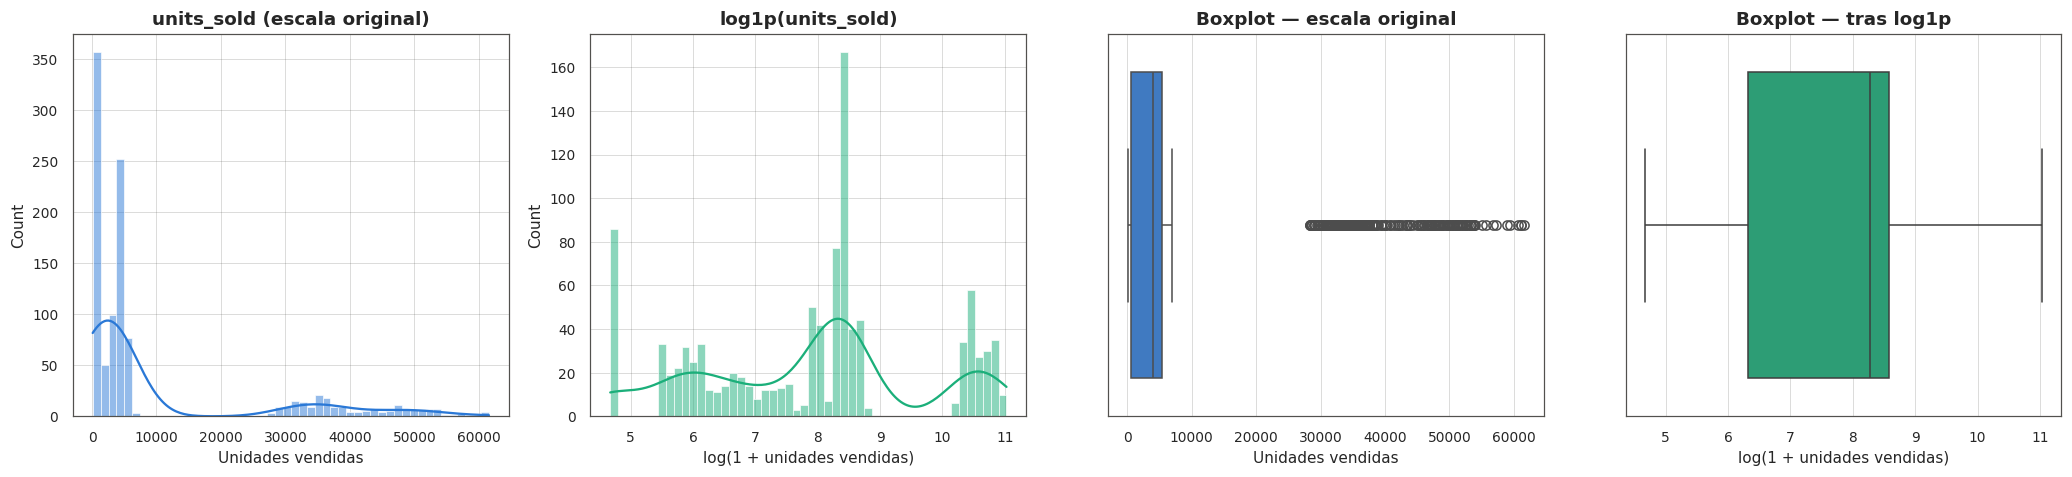

Asimetría (skewness) original :    1.738
Asimetría tras log1p          :   -0.033
Curtosis original             :    1.518
Curtosis tras log1p           :   -0.802
Outliers (regla 1.5*IQR) original :   200  (19.27%)
Outliers (regla 1.5*IQR) log1p    :     0  (0.00%)

Lectura: una asimetría |s| > 1 indica cola pesada. Los dos boxplots muestran el mismo
fenómeno: en escala original la caja queda comprimida contra el eje y casi toda la
información visual son puntos atípicos; tras log1p la caja ocupa el centro del rango y
los outliers por la regla 1.5*IQR se reducen drásticamente. Eso es señal de varianza
estabilizada, que es lo que evita que un puñado de superventas domine el gradiente.


In [10]:
# ============================================================================
#  2.4 Distribución de la variable objetivo primaria: units_sold
# ============================================================================
fig, ax = plt.subplots(1, 4, figsize=(19, 4.5))

sns.histplot(df_clean["units_sold"], bins=50, kde=True, ax=ax[0], color=C_SERIE[0])
ax[0].set_title("units_sold (escala original)")
ax[0].set_xlabel("Unidades vendidas")

sns.histplot(np.log1p(df_clean["units_sold"]), bins=50, kde=True, ax=ax[1], color=C_SERIE[2])
ax[1].set_title("log1p(units_sold)")
ax[1].set_xlabel("log(1 + unidades vendidas)")

sns.boxplot(x=df_clean["units_sold"], ax=ax[2], color=C_SERIE[0])
ax[2].set_title("Boxplot — escala original")
ax[2].set_xlabel("Unidades vendidas")

sns.boxplot(x=np.log1p(df_clean["units_sold"]), ax=ax[3], color=C_SERIE[2])
ax[3].set_title("Boxplot — tras log1p")
ax[3].set_xlabel("log(1 + unidades vendidas)")

plt.tight_layout(); plt.show()

from scipy.stats import skew, kurtosis

def n_outliers_iqr(s):
    q1, q3 = np.percentile(s, [25, 75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

orig = df_clean["units_sold"].dropna()
logt = np.log1p(orig)

print(f"Asimetría (skewness) original : {skew(orig):>8.3f}")
print(f"Asimetría tras log1p          : {skew(logt):>8.3f}")
print(f"Curtosis original             : {kurtosis(orig):>8.3f}")
print(f"Curtosis tras log1p           : {kurtosis(logt):>8.3f}")
print(f"Outliers (regla 1.5*IQR) original : {n_outliers_iqr(orig):>5}  "
      f"({n_outliers_iqr(orig)/len(orig):.2%})")
print(f"Outliers (regla 1.5*IQR) log1p    : {n_outliers_iqr(logt):>5}  "
      f"({n_outliers_iqr(logt)/len(logt):.2%})")
print("\nLectura: una asimetría |s| > 1 indica cola pesada. Los dos boxplots muestran el mismo")
print("fenómeno: en escala original la caja queda comprimida contra el eje y casi toda la")
print("información visual son puntos atípicos; tras log1p la caja ocupa el centro del rango y")
print("los outliers por la regla 1.5*IQR se reducen drásticamente. Eso es señal de varianza")
print("estabilizada, que es lo que evita que un puñado de superventas domine el gradiente.")

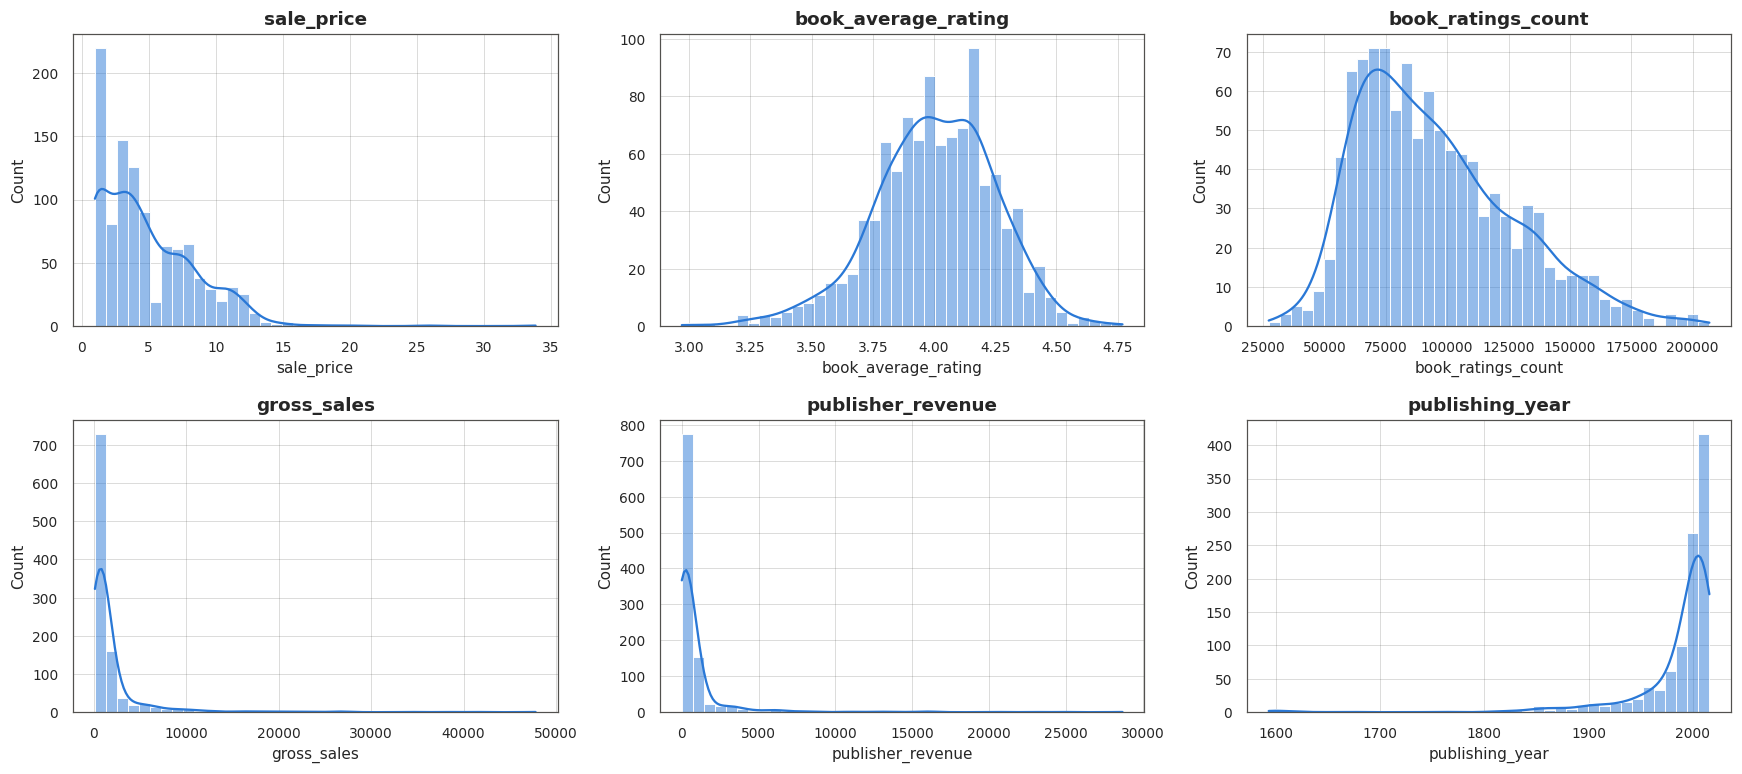

In [11]:
# ============================================================================
#  2.5 Distribuciones de las principales variables numéricas
# ============================================================================
plot_cols = [c for c in ["sale_price", "book_average_rating", "book_ratings_count",
                         "gross_sales", "publisher_revenue", "publishing_year"] if c in df_clean.columns]

n = len(plot_cols)
fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(16, 3.6 * ((n + 2) // 3)))
for axis, c in zip(np.ravel(axes), plot_cols):
    sns.histplot(df_clean[c].dropna(), bins=40, kde=True, ax=axis, color=C_SERIE[0])
    axis.set_title(c)
for axis in np.ravel(axes)[n:]:
    axis.set_visible(False)
plt.tight_layout(); plt.show()

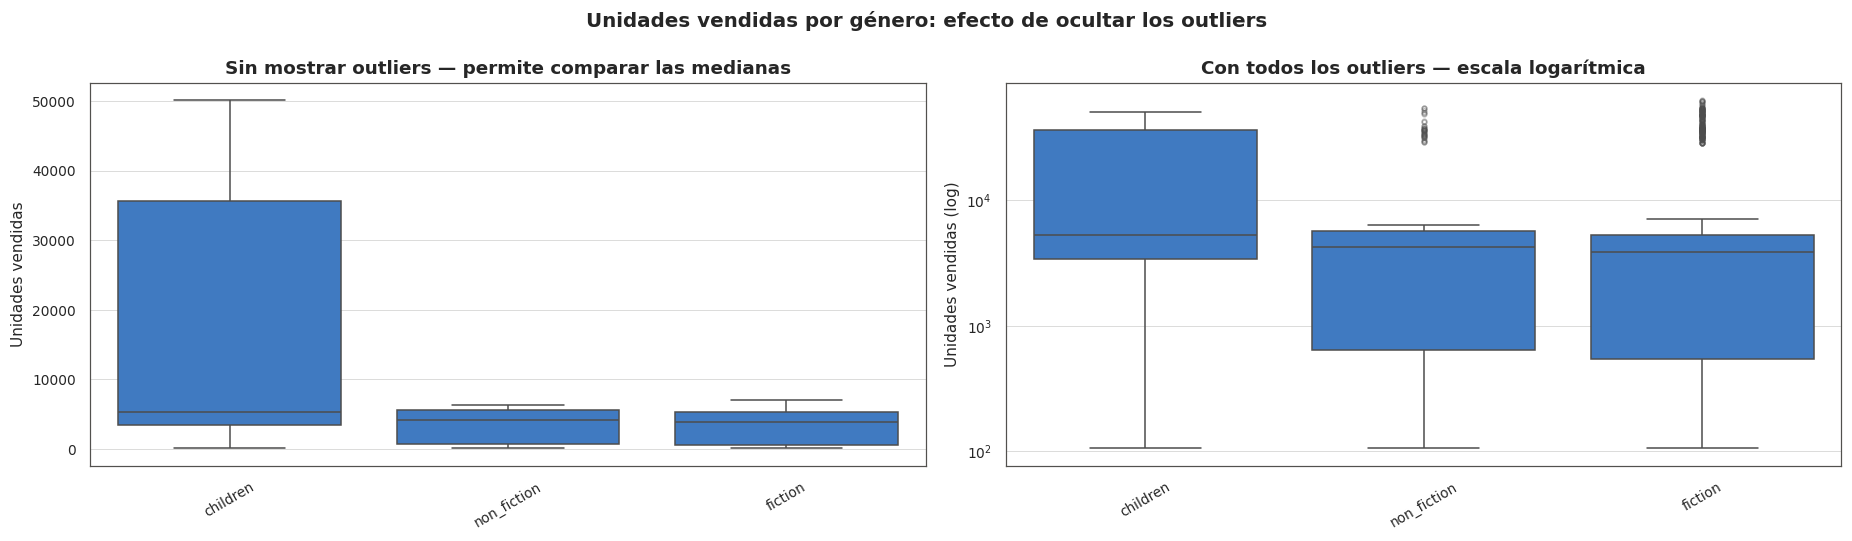

,n,mediana,p95,outliers,pct_outliers
genre,,,,,
children,15.00,"5,265.00","48,297.60",0.00,0.00
non_fiction,168.00,"4,185.00","38,728.80",34.00,20.24
fiction,855.00,"3,861.00","47,088.00",159.00,18.60
TOTAL,"1,038.00","3,942.00","46,904.40",193.00,18.59



Outliers ocultos en el panel izquierdo: 193 de 1038 libros (18.59%).
Criterio: regla de Tukey (fuera de Q1-1.5*IQR o Q3+1.5*IQR), calculada DENTRO de cada género.
Referencia: en una distribución normal esta regla marcaría ~0.7%. El exceso mide la cola pesada.


In [12]:
# ============================================================================
#  2.6 Unidades vendidas por género: efecto de los outliers
# ============================================================================
def n_out(s):
    q1, q3 = np.percentile(s, [25, 75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

orden = df_clean.groupby("genre")["units_sold"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(1, 2, figsize=(17, 5))

sns.boxplot(data=df_clean, x="genre", y="units_sold", order=orden, ax=ax[0], showfliers=False)
ax[0].set_title("Sin mostrar outliers — permite comparar las medianas")
ax[0].set_xlabel(""); ax[0].set_ylabel("Unidades vendidas")
ax[0].tick_params(axis="x", rotation=30)

sns.boxplot(data=df_clean, x="genre", y="units_sold", order=orden, ax=ax[1],
            showfliers=True, flierprops=dict(marker="o", markersize=3, alpha=.35))
ax[1].set_yscale("log")          # quitar esta línea para verlo en escala lineal
ax[1].set_title("Con todos los outliers — escala logarítmica")
ax[1].set_xlabel(""); ax[1].set_ylabel("Unidades vendidas (log)")
ax[1].tick_params(axis="x", rotation=30)

fig.suptitle("Unidades vendidas por género: efecto de ocultar los outliers",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

resumen_genero = (df_clean.groupby("genre")["units_sold"]
                  .agg(n="size", mediana="median",
                       p95=lambda s: s.quantile(.95), outliers=n_out)
                  .assign(pct_outliers=lambda d: (d["outliers"] / d["n"] * 100).round(2))
                  .loc[orden])
resumen_genero.loc["TOTAL"] = [
    len(df_clean), df_clean["units_sold"].median(), df_clean["units_sold"].quantile(.95),
    resumen_genero["outliers"].sum(),
    round(resumen_genero["outliers"].sum() / len(df_clean) * 100, 2)]
display(resumen_genero)

print(f"\nOutliers ocultos en el panel izquierdo: {int(resumen_genero.loc['TOTAL', 'outliers'])} "
      f"de {len(df_clean)} libros ({resumen_genero.loc['TOTAL', 'pct_outliers']:.2f}%).")
print("Criterio: regla de Tukey (fuera de Q1-1.5*IQR o Q3+1.5*IQR), calculada DENTRO de cada género.")
print("Referencia: en una distribución normal esta regla marcaría ~0.7%. El exceso mide la cola pesada.")

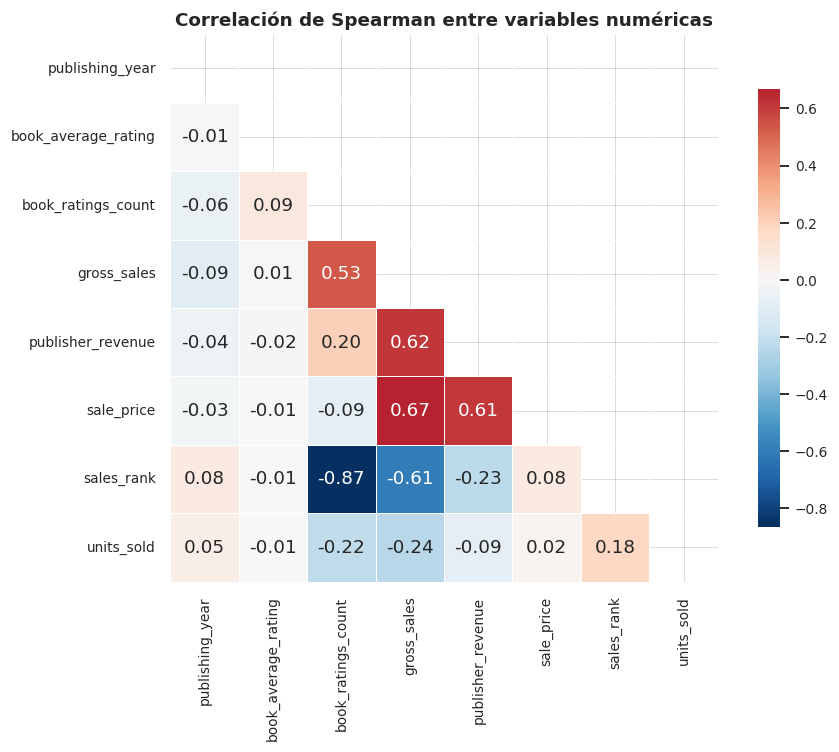

Correlación de cada variable con units_sold (Spearman) y lectura:


,spearman_vs_units_sold,Conclusion
gross_sales,-0.24,Débil (negativa): aporte marginal
book_ratings_count,-0.22,Débil (negativa): aporte marginal
sales_rank,0.18,Sin asociación monótona relevante
publisher_revenue,-0.09,Sin asociación monótona relevante
publishing_year,0.05,Sin asociación monótona relevante
sale_price,0.02,Sin asociación monótona relevante
book_average_rating,-0.01,Sin asociación monótona relevante



Variables con |rho| >= 0.95 (candidatas a leakage): ninguna
Spearman mide asociación MONÓTONA, no lineal: por eso detecta una identidad contable
aunque la relación sea de producto o de cociente, y no se deja engañar por la cola pesada.


In [13]:
# ============================================================================
#  2.7 Matriz de correlación — detección de identidades contables
# ============================================================================
corr = df_clean[num_cols_eda].corr(method="spearman")

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Correlación de Spearman entre variables numéricas")
plt.tight_layout(); plt.show()

def concluir(rho: float) -> str:
    a, signo = abs(rho), "positiva" if rho > 0 else "negativa"
    if a >= 0.95: return f"Casi perfecta ({signo}): identidad contable -> EXCLUIR de X (leakage)"
    if a >= 0.70: return f"Muy fuerte ({signo}): revisar si es consecuencia de la venta"
    if a >= 0.40: return f"Moderada ({signo}): predictor candidato"
    if a >= 0.20: return f"Débil ({signo}): aporte marginal"
    return "Sin asociación monótona relevante"

pd.set_option("display.max_colwidth", None)

tabla_corr = (corr["units_sold"].drop("units_sold")
              .rename("spearman_vs_units_sold").to_frame()
              .assign(abs_rho=lambda d: d["spearman_vs_units_sold"].abs())
              .sort_values("abs_rho", ascending=False)
              .assign(Conclusion=lambda d: d["spearman_vs_units_sold"].map(concluir))
              .drop(columns="abs_rho"))

print("Correlación de cada variable con units_sold (Spearman) y lectura:")
display(tabla_corr)

sospechosas = tabla_corr.index[tabla_corr["spearman_vs_units_sold"].abs() >= 0.95].tolist()
print(f"\nVariables con |rho| >= 0.95 (candidatas a leakage): "
      f"{sospechosas if sospechosas else 'ninguna'}")
print("Spearman mide asociación MONÓTONA, no lineal: por eso detecta una identidad contable")
print("aunque la relación sea de producto o de cociente, y no se deja engañar por la cola pesada.")

### 2.8 Auditoría de integridad del dataset

Antes de modelar hay que responder una pregunta que el EDA descriptivo no responde: **¿las variables
son internamente consistentes?** Un dataset puede no tener nulos ni duplicados y aun así contener
columnas que no significan lo que su nombre declara.

Se verifican cuatro relaciones que *deberían* cumplirse si los datos describen operaciones
comerciales reales:

| # | Relación esperada | Por qué debería cumplirse |
|---|---|---|
| 1 | $\texttt{gross_sales} = \texttt{units_sold} \times \texttt{sale_price}$ | Identidad contable: la facturación es precio por cantidad |
| 2 | $\texttt{sales_rank}$ ordena inversamente a $\texttt{units_sold}$ | Un ranking de ventas debe reflejar las ventas |
| 3 | $\texttt{publisher_revenue}$ es una fracción variable de $\texttt{gross_sales}$ | El margen editorial varía por contrato, formato y autor |
| 4 | $\texttt{units_sold}$ se asocia con algún atributo del libro | Precio, género o prueba social deberían explicar parte de la venta |

Los resultados de esta celda condicionan todo lo que sigue: si alguna de estas relaciones falla, no
es un detalle técnico sino un límite de lo que el dataset permite afirmar.

AUDITORÍA DE INTEGRIDAD DEL DATASET


,Resultado,Estado
Verificación,,
gross_sales = units_sold x sale_price,se cumple en 41.6% de las filas | Pearson r = -0.0689,FALLA
sales_rank ordena las ventas,"Spearman(rank, units) = +0.1811 | Spearman(rank, orden de fila) = +1.0000",FALLA
margin_ratio es continuo,"2 valor(es) distinto(s) al redondear a 3 decimales: [np.float64(0.0), np.float64(0.6)]",FALLA
units_sold se asocia con algún atributo,"|rho| máximo = 0.2391 (gross_sales, signo -)",FALLA



Verificaciones que fallan: 4 de 4

Correlación de Spearman de units_sold con cada variable numérica:
gross_sales           -0.24
book_ratings_count    -0.22
sales_rank             0.18
publisher_revenue     -0.09
publishing_year        0.05
sale_price             0.02
book_average_rating   -0.01


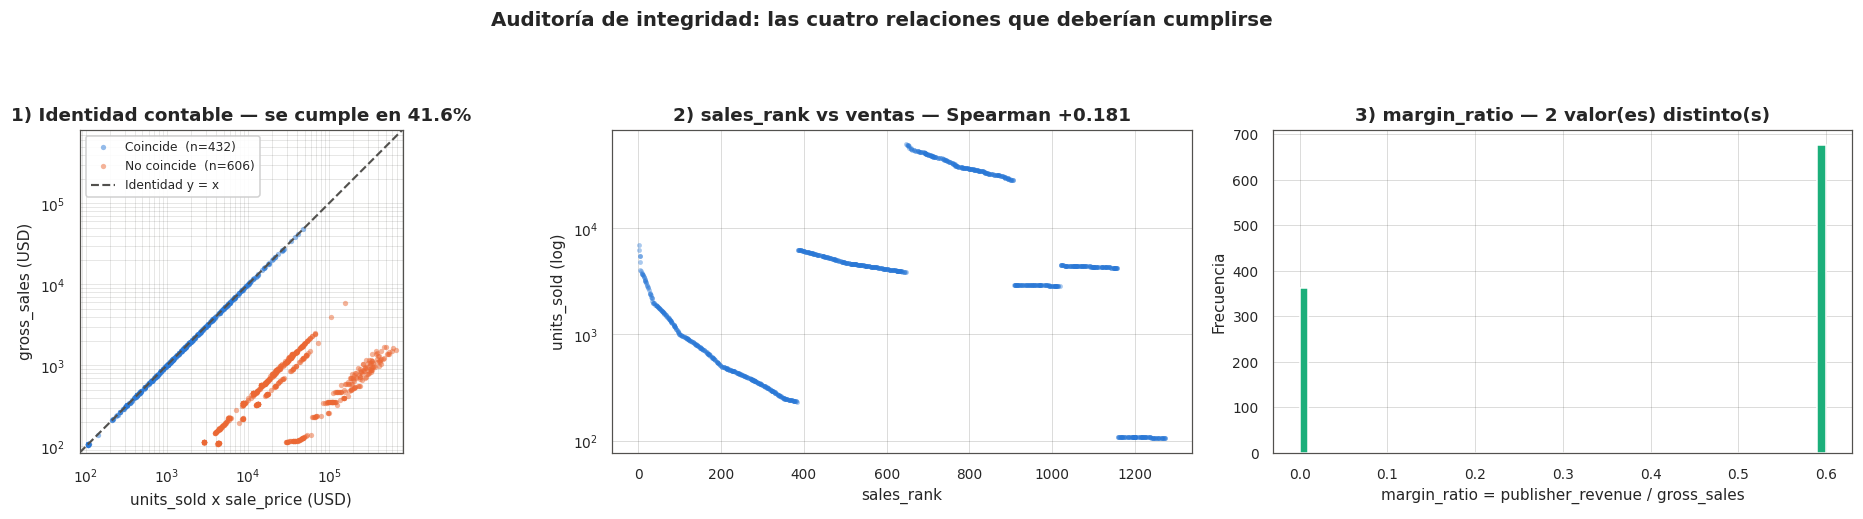

In [14]:
# ============================================================================
#  2.8 Auditoría de integridad: ¿las variables son consistentes entre sí?
# ============================================================================
auditoria = []

# --- 1) Identidad contable: gross_sales == units_sold * sale_price
chk = df_clean[["gross_sales", "units_sold", "sale_price"]].dropna()
chk = chk[(chk["units_sold"] > 0) & (chk["gross_sales"] > 0)]
implicito = chk["units_sold"] * chk["sale_price"]
err_rel   = (chk["gross_sales"] - implicito).abs() / chk["gross_sales"]
pct_ok    = float((err_rel < .01).mean())
r_pearson = float(np.corrcoef(chk["gross_sales"], implicito)[0, 1])
auditoria.append({
    "Verificación": "gross_sales = units_sold x sale_price",
    "Resultado"   : f"se cumple en {pct_ok:.1%} de las filas | Pearson r = {r_pearson:+.4f}",
    "Estado"      : "OK" if pct_ok > .95 else "FALLA",
})

# --- 2) sales_rank debería ordenar inversamente a units_sold
rho_rank  = float(df_clean["sales_rank"].corr(df_clean["units_sold"], method="spearman"))
rho_orden = float(pd.Series(np.arange(len(df_clean)), index=df_clean.index)
                    .corr(df_clean["sales_rank"], method="spearman"))
auditoria.append({
    "Verificación": "sales_rank ordena las ventas",
    "Resultado"   : f"Spearman(rank, units) = {rho_rank:+.4f} | "
                    f"Spearman(rank, orden de fila) = {rho_orden:+.4f}",
    "Estado"      : "OK" if rho_rank < -0.7 else "FALLA",
})

# --- 3) margin_ratio debería ser una variable continua
margen_aud = (df_clean["publisher_revenue"] / df_clean["gross_sales"].replace(0, np.nan))
n_valores  = int(margen_aud.round(3).nunique())
auditoria.append({
    "Verificación": "margin_ratio es continuo",
    "Resultado"   : f"{n_valores} valor(es) distinto(s) al redondear a 3 decimales: "
                    f"{sorted(margen_aud.round(3).dropna().unique())[:4]}",
    "Estado"      : "OK" if n_valores > 10 else "FALLA",
})

# --- 4) units_sold debería asociarse con algún atributo del libro
num_aud = df_clean.select_dtypes(include=[np.number]).drop(columns=["units_sold"])
corrs   = num_aud.corrwith(df_clean["units_sold"], method="spearman").dropna()
mejor   = corrs.reindex(corrs.abs().sort_values(ascending=False).index)
auditoria.append({
    "Verificación": "units_sold se asocia con algún atributo",
    "Resultado"   : f"|rho| máximo = {mejor.abs().iloc[0]:.4f} ({mejor.index[0]}, "
                    f"signo {'+' if mejor.iloc[0] > 0 else '-'})",
    "Estado"      : "OK" if mejor.abs().iloc[0] > 0.30 else "FALLA",
})

tabla_auditoria = pd.DataFrame(auditoria).set_index("Verificación")
print("=" * 100)
print("AUDITORÍA DE INTEGRIDAD DEL DATASET")
print("=" * 100)
display(tabla_auditoria)

n_fallas = int((tabla_auditoria["Estado"] == "FALLA").sum())
print(f"\nVerificaciones que fallan: {n_fallas} de {len(tabla_auditoria)}")

print("\nCorrelación de Spearman de units_sold con cada variable numérica:")
print(mejor.round(4).to_string())

# --- gráfico: la identidad contable y la distribución de margin_ratio
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))

cumple = (err_rel < .01).values
ax[0].scatter(implicito[cumple], chk["gross_sales"][cumple], s=12, alpha=.5,
              color=C_SERIE[0], linewidths=0, label=f"Coincide  (n={cumple.sum()})")
ax[0].scatter(implicito[~cumple], chk["gross_sales"][~cumple], s=12, alpha=.5,
              color=C_SERIE[1], linewidths=0, label=f"No coincide  (n={(~cumple).sum()})")
lim = [max(min(implicito.min(), chk["gross_sales"].min()) * .8, 1e-1),
       max(implicito.max(), chk["gross_sales"].max()) * 1.2]
ax[0].plot(lim, lim, ls="--", lw=1.4, color=C_REF, label="Identidad y = x")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_aspect("equal")
ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("units_sold x sale_price (USD)"); ax[0].set_ylabel("gross_sales (USD)")
ax[0].set_title(f"1) Identidad contable — se cumple en {pct_ok:.1%}")
ax[0].legend(fontsize=8, loc="upper left")
ax[0].grid(which="both", alpha=.15)

ax[1].scatter(df_clean["sales_rank"], df_clean["units_sold"], s=10, alpha=.4,
              color=C_SERIE[0], linewidths=0)
ax[1].set_yscale("log")
ax[1].set_xlabel("sales_rank"); ax[1].set_ylabel("units_sold (log)")
ax[1].set_title(f"2) sales_rank vs ventas — Spearman {rho_rank:+.3f}")

ax[2].hist(margen_aud.dropna(), bins=60, color=C_SERIE[2])
ax[2].set_xlabel("margin_ratio = publisher_revenue / gross_sales")
ax[2].set_ylabel("Frecuencia")
ax[2].set_title(f"3) margin_ratio — {n_valores} valor(es) distinto(s)")

fig.suptitle("Auditoría de integridad: las cuatro relaciones que deberían cumplirse",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.91]); plt.show()

### 2.9 Consecuencias de la auditoría: el dataset son dos poblaciones

La auditoría no sólo encontró columnas poco confiables: encontró que **el archivo está compuesto por
dos bloques con escalas de venta incompatibles**, concatenados.

| Bloque | Identidad contable | Filas | Mediana de `units_sold` | Percentil 80 interno |
|---|---|---:|---:|---:|
| **A** | se cumple | ~432 | ~430 | ~1.169 |
| **B** | falla | ~606 | ~4.617 | ~35.640 |

La consecuencia es grave para el modelado. El percentil 80 calculado **sobre el archivo completo**
cae por encima de casi todo el bloque A, de modo que prácticamente todos los "bestsellers" salen del
bloque B. Con el corte global, la etiqueta `is_bestseller` deja de medir una propiedad del libro y
pasa a medir **de qué bloque del archivo proviene la fila** — algo que ningún atributo editorial
puede predecir, y que explica por qué un clasificador entrenado sobre el archivo entero no supera al
azar.

#### La decisión: restringir el análisis al bloque A

Se conserva el bloque **A**, que es donde $\texttt{gross_sales} = \texttt{units_sold} \times
\texttt{sale_price}$ se cumple. El criterio es de **consistencia interna**: es el subconjunto en el
que las columnas significan lo que declaran y las magnitudes son mutuamente coherentes. El bloque B
se descarta porque sus cifras de facturación no se corresponden con sus unidades y precios, y no hay
forma de determinar cuál de los tres valores es el correcto.

El costo es de tamaño muestral; el beneficio es que todo lo que sigue se apoya en datos verificables.
La celda 2.10 aplica el recorte y cuantifica su efecto.

> **Las tres variables de facturación siguen excluidas de $X$.** `gross_sales`, `publisher_revenue` y
> `sales_rank` se usan acá para *diagnosticar* la estructura del archivo y definir el recorte, que es
> una decisión de alcance del análisis, no una feature. Ninguna entra al modelado.

ESTRUCTURA DEL ARCHIVO: DOS POBLACIONES


,filas,units_mediana,units_p80,precio_mediano
bloque,,,,
A (consistente),432,430.50,"1,169.00",3.99
B (inconsistente),606,"4,617.00","35,640.00",3.99



Percentil 80 GLOBAL de units_sold: 6,183
Tasa de 'bestseller' según ese corte global, por bloque:
   A (consistente)      0.5%
   B (inconsistente)    34.2%

Con el corte global la etiqueta separa bloques, no libros: por eso se recorta.

RECORTE APLICADO: 1038 -> 432 filas (606 descartadas, 58.4%)
Nuevo percentil 80 de units_sold: 1,169


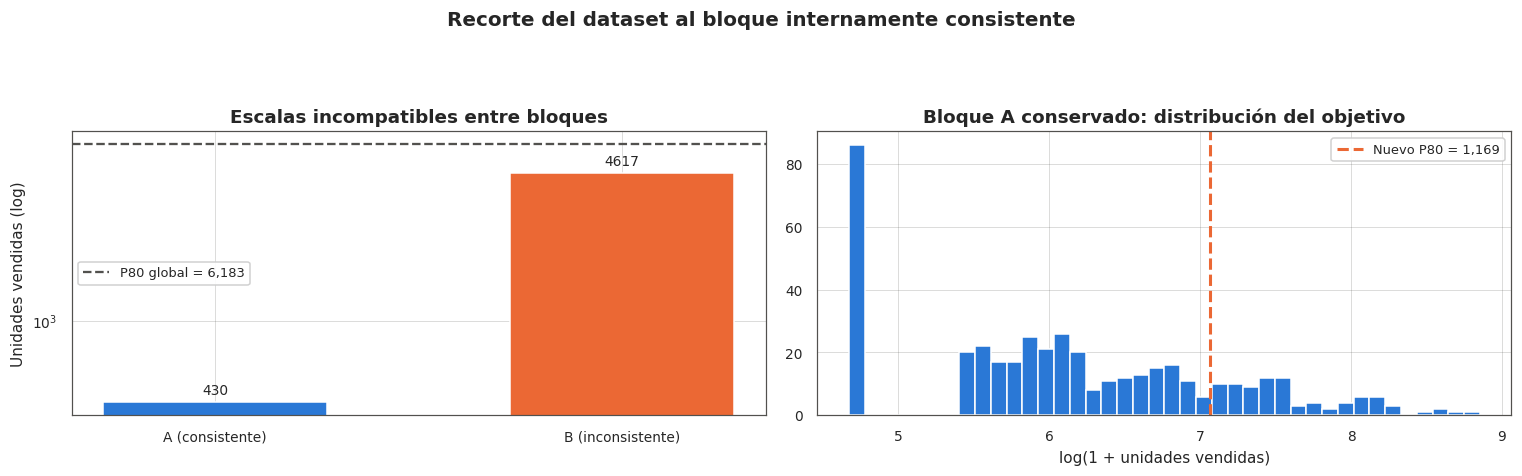

In [15]:
# ============================================================================
#  2.10 Recorte al bloque internamente consistente
# ============================================================================
# La auditoría 2.8 mostró que el archivo son dos poblaciones con escalas distintas.
# Se conserva aquella en la que la identidad contable se verifica, porque es la única
# donde las columnas son mutuamente coherentes.
TOL_IDENTIDAD = 0.01

_imp  = df_clean["units_sold"] * df_clean["sale_price"]
_err  = (df_clean["gross_sales"] - _imp).abs() / df_clean["gross_sales"].replace(0, np.nan)
bloque = np.where(_err < TOL_IDENTIDAD, "A (consistente)", "B (inconsistente)")

resumen_bloques = (df_clean.assign(bloque=bloque)
                   .groupby("bloque")
                   .agg(filas=("units_sold", "size"),
                        units_mediana=("units_sold", "median"),
                        units_p80=("units_sold", lambda s: s.quantile(.80)),
                        precio_mediano=("sale_price", "median")))
print("=" * 88)
print("ESTRUCTURA DEL ARCHIVO: DOS POBLACIONES")
print("=" * 88)
display(resumen_bloques.round(2))

p80_global = df_clean["units_sold"].quantile(.80)
tasa = (df_clean.assign(bloque=bloque, bs=(df_clean["units_sold"] >= p80_global).astype(int))
        .groupby("bloque")["bs"].mean())
print(f"\nPercentil 80 GLOBAL de units_sold: {p80_global:,.0f}")
print("Tasa de 'bestseller' según ese corte global, por bloque:")
for b, t in tasa.items():
    print(f"   {b:<20} {t:.1%}")
print("\nCon el corte global la etiqueta separa bloques, no libros: por eso se recorta.")

filas_antes = len(df_clean)
df_clean = df_clean[_err < TOL_IDENTIDAD].reset_index(drop=True)
print("\n" + "=" * 88)
print(f"RECORTE APLICADO: {filas_antes} -> {len(df_clean)} filas "
      f"({filas_antes - len(df_clean)} descartadas, {1 - len(df_clean)/filas_antes:.1%})")
print("=" * 88)
print(f"Nuevo percentil 80 de units_sold: {df_clean['units_sold'].quantile(.80):,.0f}")

num_cols_eda = df_clean.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_eda = df_clean.select_dtypes(exclude=[np.number]).columns.tolist()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ax[0].bar(resumen_bloques.index, resumen_bloques["units_mediana"], color=C_SERIE[:2], width=.55)
ax[0].bar_label(ax[0].containers[0], fmt="%.0f", padding=3, fontsize=9)
ax[0].axhline(p80_global, color=C_REF, ls="--", lw=1.5,
              label=f"P80 global = {p80_global:,.0f}")
ax[0].set_yscale("log"); ax[0].set_ylabel("Unidades vendidas (log)")
ax[0].set_title("Escalas incompatibles entre bloques"); ax[0].legend(fontsize=8.5)

ax[1].hist(np.log1p(df_clean["units_sold"]), bins=40, color=C_SERIE[0])
ax[1].axvline(np.log1p(df_clean["units_sold"].quantile(.80)), color=C_SERIE[1], ls="--", lw=2,
              label=f"Nuevo P80 = {df_clean['units_sold'].quantile(.80):,.0f}")
ax[1].set_title("Bloque A conservado: distribución del objetivo")
ax[1].set_xlabel("log(1 + unidades vendidas)"); ax[1].legend(fontsize=8.5)

fig.suptitle("Recorte del dataset al bloque internamente consistente",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.9]); plt.show()

---
## 3. Ingeniería de características

| Variable | Fórmula | Justificación |
|---|---|---|
| `book_age` | $2026 - \texttt{Publishing Year}$ | Convierte un año calendario (sin orden semántico para un árbol) en antigüedad, que sí tiene relación monótona con la acumulación de ventas y reseñas. **Reemplaza** a `publishing_year`, que no entra al modelo: son la misma variable (correlación $-1$) y duplicarla distorsionaría la distancia del kernel en el SVM. |
| `price_relative_to_genre` | $\dfrac{\texttt{sale price}}{\overline{\texttt{sale price}}_{\text{género}}}$ | Un precio de USD 25 es caro en un género y barato en otro. Normalizar por el promedio del género captura el posicionamiento **relativo**, que es lo que percibe el consumidor. |
| `social_proof_score` | $\texttt{Book_average_rating} \times \log(1 + \texttt{Book_ratings_count})$ | Combina *calidad* percibida con *volumen* de evidencia. El logaritmo refleja utilidad marginal decreciente: pasar de 10 a 100 reseñas informa mucho más que pasar de 10.000 a 10.090. |
| `margin_ratio` | $\dfrac{\texttt{publisher revenue}}{\texttt{gross sales}}$ | Rentabilidad unitaria independiente de la escala. Es el objetivo del Experimento 3. |

> **Sobre `price_relative_to_genre` y el leakage.** La media por género es un parámetro estimado a partir de los datos, así que calcularla sobre el dataset completo filtraría el precio medio de los libros de test hacia las features de entrenamiento.
>
> La versión que se construye en esta sección usa **todo el dataset** y es **exclusivamente exploratoria**: sirve para describir la distribución de la variable. El valor que efectivamente alimenta a los modelos se **recalcula dentro de `preparar_datos()`** (sección 5.1) con las medias del conjunto de train, y ese mismo diccionario queda guardado en `info["genre_price_map"]` para poder reaplicarlo al test y a los escenarios de la simulación de precios del Experimento 2.

Variables creadas (vista exploratoria):



,count,mean,std,min,25%,50%,75%,max
book_age,432.00,44.88,60.22,10.00,17.00,26.00,46.00,433.00
price_relative_to_genre,432.00,1.00,0.78,0.21,0.43,0.86,1.40,7.30
social_proof_score,432.00,46.46,3.33,34.25,44.36,46.56,48.82,55.14
margin_ratio,432.00,0.38,0.29,0.00,0.00,0.60,0.60,0.60


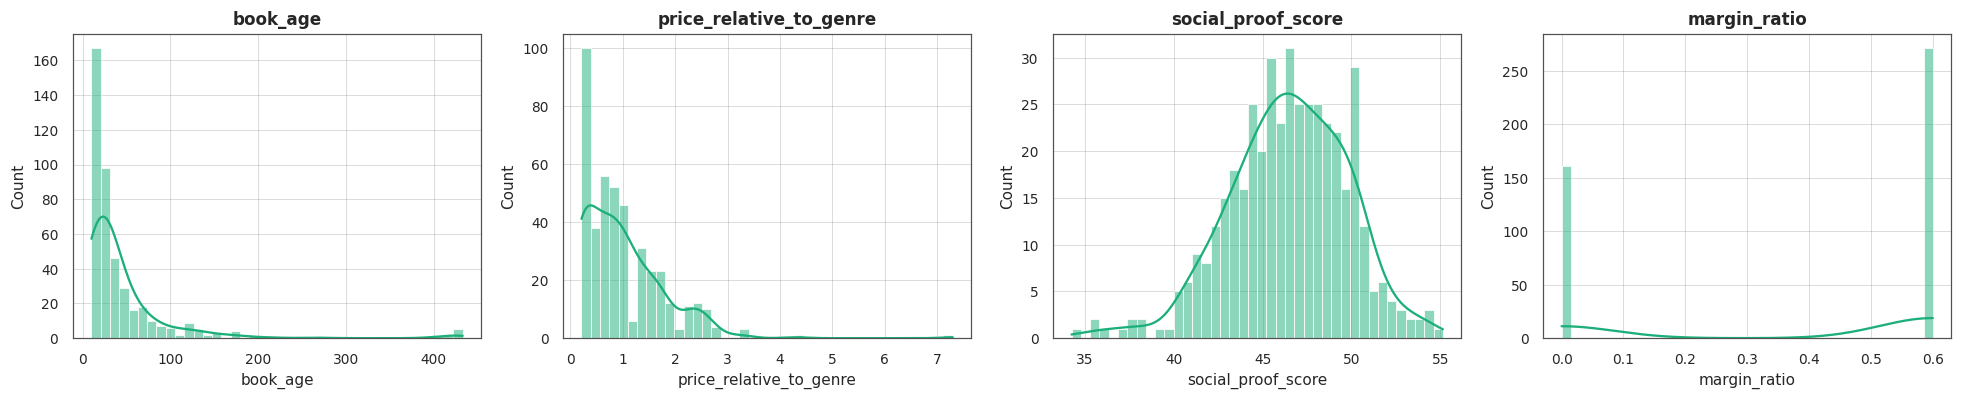

In [16]:
# ============================================================================
#  3.1 Ingeniería de características
# ============================================================================

ANIO_REFERENCIA = 2026

def crear_features(data: pd.DataFrame, genre_price_map: dict | None = None,
                   global_price_mean: float | None = None):
    """Agrega las variables derivadas.

    genre_price_map: medias de sale_price por género. Si se pasa None, se calculan
    sobre los datos recibidos. ATENCIÓN: eso sólo es válido para EXPLORACIÓN. Para
    entrenar, preparar_datos() vuelve a calcular price_relative_to_genre con las
    medias del conjunto de train, porque usar el dataset completo filtraría
    información del test hacia las features.
    """
    out = data.copy()

    # book_age
    out["book_age"] = ANIO_REFERENCIA - out["publishing_year"]

    if genre_price_map is None:
        genre_price_map   = out.groupby("genre")["sale_price"].mean().to_dict()
        global_price_mean = float(out["sale_price"].mean())
    medias = out["genre"].map(genre_price_map).astype(float).fillna(global_price_mean)
    medias = medias.replace(0, np.nan)
    out["price_relative_to_genre"] = out["sale_price"] / medias

    # social_proof_score
    out["social_proof_score"] = (out["book_average_rating"]
                                 * np.log1p(out["book_ratings_count"]))

    # margin_ratio  (objetivo del Experimento 3)
    out["margin_ratio"] = out["publisher_revenue"] / out["gross_sales"].replace(0, np.nan)
    out.loc[~np.isfinite(out["margin_ratio"]), "margin_ratio"] = np.nan

    return out, genre_price_map, global_price_mean


# Vista EXPLORATORIA: las medias por género salen del dataset completo. Sirve para
# describir las distribuciones; el valor que se usa para entrenar se recalcula en 5.1.
df_feat, GENRE_PRICE_MAP_EDA, GLOBAL_PRICE_MEAN_EDA = crear_features(df_clean)

nuevas = ["book_age", "price_relative_to_genre", "social_proof_score", "margin_ratio"]
print("Variables creadas (vista exploratoria):\n")
display(df_feat[nuevas].astype(float).describe().T)

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, c in zip(ax, nuevas):
    sns.histplot(df_feat[c].astype(float).replace([np.inf, -np.inf], np.nan).dropna(),
                 bins=40, kde=True, ax=a, color=C_SERIE[2])
    a.set_title(c, fontsize=11)
plt.tight_layout(); plt.show()

## 4. Codificación de categóricas: One-Hot vs. Target Encoding

**Teoría.**

- **One-Hot Encoding.** Cada nivel se transforma en una columna binaria. No impone orden artificial y
  es la opción correcta para baja cardinalidad. Su costo es dimensional: $k$ niveles $\to k$ columnas,
  lo que dispersa la información y agrava la maldición de la dimensionalidad.
- **Target Encoding.** Cada nivel se reemplaza por una función del objetivo dentro de ese nivel
  (la media). Conserva una sola columna, pero **filtra el objetivo hacia las features**: si un autor
  aparece una sola vez, su codificación *es* su propio $y$, y el modelo lo memoriza.

Para controlar ese riesgo se aplican dos mecanismos estándar:

1. **Suavizado bayesiano** hacia la media global $\mu$:

$$\text{enc}(c) = \frac{n_c \cdot \bar{y}_c + m \cdot \mu}{n_c + m}$$

   donde $n_c$ es la frecuencia del nivel y $m$ el peso del *prior*. Los niveles raros se acercan a la
   media global; los frecuentes conservan su media propia.

2. **Codificación *out-of-fold*** en entrenamiento: la codificación de cada fila se calcula con los
   *folds* restantes, nunca con la propia fila. Para el test se usa el mapa completo ajustado en train.

**Regla de decisión aplicada:** cardinalidad $\le$ 15 niveles $\to$ One-Hot; $>$ 15 $\to$ Target
Encoding suavizado *out-of-fold*.

In [17]:
# ============================================================================
#  4.1 Codificación de Variables categóricas
# ============================================================================
from sklearn.model_selection import KFold, StratifiedKFold

UMBRAL_CARDINALIDAD = 15

class TargetEncoderSuavizado:
    '''Target encoding con suavizado bayesiano y codificación out-of-fold en train.'''

    def __init__(self, cols, m: float = 20.0, n_splits: int = 5,
                 random_state: int = RANDOM_STATE):
        self.cols, self.m = list(cols), m
        self.n_splits, self.random_state = n_splits, random_state
        self.maps_, self.prior_ = {}, None

    def _map_col(self, s: pd.Series, y: pd.Series) -> dict:
        stats = y.groupby(s).agg(["mean", "count"])
        suav = (stats["count"] * stats["mean"] + self.m * self.prior_) / (stats["count"] + self.m)
        return suav.to_dict()

    def fit(self, X: pd.DataFrame, y: pd.Series):
        y = pd.Series(np.asarray(y), index=X.index)
        self.prior_ = float(y.mean())
        for c in self.cols:
            self.maps_[c] = self._map_col(X[c].astype(str), y)
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        out = X.copy()
        for c in self.cols:
            out[c + "_te"] = out[c].astype(str).map(self.maps_[c]).fillna(self.prior_)
            out = out.drop(columns=[c])
        return out

    def fit_transform_oof(self, X: pd.DataFrame, y: pd.Series,
                          stratify: bool = False) -> pd.DataFrame:
        '''Ajusta el mapa completo y devuelve el train codificado out-of-fold.'''
        self.fit(X, y)
        y_ser = pd.Series(np.asarray(y), index=X.index)
        out = X.copy()
        splitter = (StratifiedKFold(self.n_splits, shuffle=True, random_state=self.random_state)
                    if stratify else
                    KFold(self.n_splits, shuffle=True, random_state=self.random_state))
        folds = list(splitter.split(X, y_ser if stratify else None))
        for c in self.cols:
            col_oof = pd.Series(np.nan, index=X.index, dtype=float)
            for tr_idx, va_idx in folds:
                mp = self._map_col(X.iloc[tr_idx][c].astype(str), y_ser.iloc[tr_idx])
                col_oof.iloc[va_idx] = (X.iloc[va_idx][c].astype(str)
                                        .map(mp).fillna(self.prior_).values)
            out[c + "_te"] = col_oof.fillna(self.prior_)
            out = out.drop(columns=[c])
        return out


def separar_categoricas(X: pd.DataFrame, umbral: int = UMBRAL_CARDINALIDAD):
    '''Devuelve (columnas para one-hot, columnas para target encoding).'''
    cat = X.select_dtypes(exclude=[np.number]).columns.tolist()
    ohe = [c for c in cat if X[c].nunique() <= umbral]
    te  = [c for c in cat if X[c].nunique() >  umbral]
    return ohe, te

# Diagnóstico de cardinalidad sobre las categóricas disponibles
cat_disp = df_feat.select_dtypes(exclude=[np.number]).columns.tolist()
print("Cardinalidad de las variables categóricas:\n")
for c in cat_disp:
    k = df_feat[c].nunique()
    print(f"  {c:<16} {k:>6} niveles  ->  {'One-Hot' if k <= UMBRAL_CARDINALIDAD else 'Target Encoding'}")

Cardinalidad de las variables categóricas:

  book_name           432 niveles  ->  Target Encoding
  author              341 niveles  ->  Target Encoding
  author_rating         4 niveles  ->  One-Hot
  genre                 3 niveles  ->  One-Hot
  publisher             7 niveles  ->  One-Hot


---
## 5. Preparación de datos y política de features

### 5.1 Qué entra al modelado y qué no

Todos los experimentos de este trabajo comparten **un único criterio de selección de variables**,
declarado una sola vez en la celda siguiente y aplicado sin excepciones. El criterio es el
**horizonte de la decisión**:

> Una variable puede ser predictora únicamente si su valor existe **en el momento en que hay que
> tomar la decisión**.

El horizonte de decisión de este trabajo es el de un **título ya publicado**: la editorial evalúa si
reimprime, si sostiene la campaña de marketing o si renegocia el contrato de un libro que ya está en
el mercado. En ese momento las reseñas de los lectores **ya existen**, y por lo tanto son
información legítimamente disponible.

Lo que sigue prohibido es todo lo que forme parte del resultado que se quiere predecir —las unidades
vendidas y las cifras de facturación derivadas de ellas— y todo lo que la auditoría 2.8 encontró
inconsistente o artefactual.

| Columna | ¿Entra? | Motivo |
|---|:---:|---|
| `genre` | ✅ | Atributo editorial del título |
| `sale_price` | ✅ | Variable de decisión de la editorial |
| `author` | ✅ | Conocido; se codifica con *target encoding* suavizado *out-of-fold* |
| `author_rating` | ✅ | Reputación del autor, previa a este título |
| `publisher` | ✅ | Sello que edita el título |
| `book_age` | ✅ | Antigüedad del título, derivada de `publishing_year` |
| `price_relative_to_genre` | ✅ | Derivada de `sale_price`; se recalcula con medias de *train* |
| `publishing_year` | ❌ | Redundante: `book_age` $= 2026 - $ `publishing_year`, correlación $-1$ |
| `book_name` | ❌ | Identificador de la obra, sin poder predictivo generalizable |
| `language_code` | ❌ | Eliminada en 2.3 por codificación inconsistente |
| `book_average_rating` | ✅ | Prueba social observable en un título ya publicado |
| `book_ratings_count` | ✅ | Volumen de reseñas, observable en el mercado |
| `social_proof_score` | ✅ | Combina calidad percibida y volumen de evidencia |
| `units_sold` | ❌ | **Variable objetivo** de los Experimentos 1 y 2 |
| `gross_sales` | ❌ | **Componente del resultado** a predecir, y además inconsistente (auditoría 2.8) |
| `publisher_revenue` | ❌ | **Componente del resultado**, y además degenerada: dos estados |
| `sales_rank` | ❌ | **Artefacto**: codifica la posición en el archivo (auditoría 2.8) |
| `margin_ratio` | ❌ | Derivada de las dos anteriores |

**Un solo criterio, sin interruptores.** El notebook no define escenarios alternativos ni variables
que conmuten el conjunto de features: `FEATURES_MODELO` es la única lista y la usan los tres
experimentos.

> **Si el horizonte fuera de lanzamiento**, las tres variables de prueba social quedarían fuera y el
> desempeño del Experimento 1 caería a un ROC-AUC en torno a 0.6: los atributos conocidos antes de
> publicar no bastan para anticipar el éxito comercial en este dataset. La sección 9.5 lo registra
> como limitación explícita del alcance.

### Orden de operaciones

```
split  →  imputar (fit en train)  →  recalcular derivadas  →  encoding (fit en train)  →  escalar (fit en train)
```

**Escalado.** Los modelos basados en árboles (XGBoost, LightGBM, Random Forest) son invariantes ante
transformaciones monótonas de cada feature: no necesitan escalado. SVM sí, porque el kernel RBF
depende de la distancia euclídea $\|x_i - x_j\|^2$, en la que una variable medida en decenas de miles
domina a una medida en unidades. Por eso el escalado es un parámetro de la función y se activa sólo
dentro del `Pipeline` del Experimento 3.

In [18]:
# ============================================================================
#  5.1 Política de features: una única definición para los tres experimentos
# ============================================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler

# --- Motivos de exclusión, declarados una sola vez ---------------------------
EXCLUIDAS = {
    "units_sold"         : "Variable objetivo (Experimentos 1 y 2)",
    "gross_sales"        : "Componente del resultado + inconsistente (auditoría 2.8)",
    "publisher_revenue"  : "Componente del resultado + degenerada (dos estados)",
    "sales_rank"         : "Artefacto: codifica la posición en el archivo",
    "margin_ratio"       : "Derivada de gross_sales y publisher_revenue",
    "book_name"          : "Identificador de la obra, sin poder generalizable",
    "language_code"      : "Eliminada en 2.3: codificación inconsistente",
    "publishing_year"    : "Redundante con book_age (correlación -1)",
}
# --- La ÚNICA lista de features del trabajo ---------------------------------
FEATURES_MODELO = [
    "author", "author_rating", "genre", "publisher",
    "sale_price", "book_age", "price_relative_to_genre",
    # Prueba social: admisible porque el horizonte es un título YA publicado
    "book_average_rating", "book_ratings_count", "social_proof_score",
]

print("=" * 88)
print("POLÍTICA DE FEATURES — única para los Experimentos 1, 2 y 3")
print("=" * 88)
tabla_features = pd.DataFrame(
    [{"Columna": c, "Entra al modelo": "SI", "Motivo": "Observable en un título del catálogo"}
     for c in FEATURES_MODELO] +
    [{"Columna": c, "Entra al modelo": "NO", "Motivo": m} for c, m in EXCLUIDAS.items()]
).set_index("Columna")
display(tabla_features)

# --- Verificación de coherencia: ninguna columna queda sin clasificar --------
cols_dataset   = set(df_feat.columns)
cols_declaradas = set(FEATURES_MODELO) | set(EXCLUIDAS)
sin_clasificar  = sorted(cols_dataset - cols_declaradas)
inexistentes    = sorted(cols_declaradas - cols_dataset)
if sin_clasificar:
    raise ValueError(f"Columnas del dataset sin clasificar en la política: {sin_clasificar}")
print(f"\nColumnas del dataset            : {len(cols_dataset)}")
print(f"Entran al modelo                : {len(FEATURES_MODELO)}  -> {FEATURES_MODELO}")
print(f"Excluidas con motivo declarado  : {len(EXCLUIDAS)}")
if inexistentes:
    print(f"Declaradas pero ausentes del df : {inexistentes}")
print("Verificación: todas las columnas del dataset están clasificadas.")


def preparar_datos(data: pd.DataFrame, y: pd.Series, *,
                   features: list | None = None, estratificar: bool = False,
                   escalar: str | None = None, verbose: bool = True):
    '''Devuelve X_train, X_test, y_train, y_test, info.

    features: por defecto FEATURES_MODELO, la única lista del trabajo. El parámetro
              permite pasar otra lista para análisis de sensibilidad puntuales.
    escalar : None | "standard" | "robust"
    '''
    features = FEATURES_MODELO if features is None else features
    cols_x   = [c for c in features if c in data.columns]
    ausentes = [c for c in features if c not in data.columns]

    X_all = data[cols_x].copy()
    y_all = pd.Series(np.asarray(y), index=data.index)

    # --- filas con objetivo no definido
    valido = y_all.notna() & np.isfinite(y_all.astype(float))
    X_all, y_all = X_all[valido], y_all[valido]

    # --- 1) SPLIT primero (todo lo que aprende parámetros va después)
    strat = y_all if estratificar else None
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_all, y_all, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=strat)

    # --- 2) Imputación: mediana (numéricas) / moda (categóricas), ajustada en train
    num_cols = X_tr.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X_tr.select_dtypes(exclude=[np.number]).columns.tolist()

    medianas = X_tr[num_cols].median()
    modas    = {c: (X_tr[c].mode().iloc[0] if not X_tr[c].mode().empty else "desconocido")
                for c in cat_cols}

    for D in (X_tr, X_te):
        D[num_cols] = D[num_cols].replace([np.inf, -np.inf], np.nan).fillna(medianas)
        for c in cat_cols:
            D[c] = D[c].fillna(modas[c])

    # --- 2b) price_relative_to_genre recalculada con medias de género APRENDIDAS EN TRAIN
    # La versión de la sección 3.1 usa el dataset completo y sólo sirve para el EDA:
    # dejarla acá filtraría el precio medio de los libros de test hacia las features.
    genre_price_map, media_global_price = None, None
    if {"genre", "sale_price", "price_relative_to_genre"}.issubset(X_tr.columns):
        genre_price_map    = X_tr.groupby("genre")["sale_price"].mean().to_dict()
        media_global_price = float(X_tr["sale_price"].mean())
        for D in (X_tr, X_te):
            medias = (D["genre"].map(genre_price_map).astype(float)
                      .fillna(media_global_price).replace(0, np.nan))
            D["price_relative_to_genre"] = (D["sale_price"] / medias).fillna(1.0)

    # --- 3) Codificación de categóricas
    ohe_cols, te_cols = separar_categoricas(X_tr)
    encoder = None
    if te_cols:
        encoder = TargetEncoderSuavizado(te_cols, m=20.0)
        X_tr = encoder.fit_transform_oof(X_tr, y_tr, stratify=estratificar)
        X_te = encoder.transform(X_te)
    if ohe_cols:
        X_tr = pd.get_dummies(X_tr, columns=ohe_cols, drop_first=False, dtype=float)
        X_te = pd.get_dummies(X_te, columns=ohe_cols, drop_first=False, dtype=float)
        X_te = X_te.reindex(columns=X_tr.columns, fill_value=0.0)   # alineación de columnas

    X_tr = X_tr.astype(float)
    X_te = X_te.reindex(columns=X_tr.columns, fill_value=0.0).astype(float)

    # --- Verificación de nombres de feature.
    # Los valores categóricos ya se regularizaron en 2.3, así que get_dummies produce
    # nombres válidos. Esta guarda falla de forma explícita si alguna vez dejan de
    # serlo, en lugar de renombrar por detrás y ocultar el origen del problema.
    invalidas = [c for c in X_tr.columns if not re.fullmatch(r"[A-Za-z0-9_]+", str(c))]
    if invalidas:
        raise ValueError(
            "Nombres de feature incompatibles con LightGBM: " + ", ".join(map(str, invalidas)) +
            "\nRegularizá los valores de esa columna categórica en la celda 2.3 (COLS_ONEHOT).")

    # --- 4) Escalado opcional (ajustado en train)
    scaler = None
    if escalar is not None:
        scaler = StandardScaler() if escalar == "standard" else RobustScaler()
        X_tr = pd.DataFrame(scaler.fit_transform(X_tr), columns=X_tr.columns, index=X_tr.index)
        X_te = pd.DataFrame(scaler.transform(X_te),     columns=X_te.columns, index=X_te.index)

    info = {"encoder": encoder, "scaler": scaler, "medianas": medianas, "modas": modas,
            "ohe_cols": ohe_cols, "te_cols": te_cols, "features": X_tr.columns.tolist(),
            "genre_price_map": genre_price_map, "media_global_price": media_global_price,
            "cols_entrada": cols_x}

    if verbose:
        print(f"Features       : {cols_x}")
        if ausentes:
            print(f"No disponibles : {ausentes}")
        print(f"One-Hot        : {ohe_cols}")
        print(f"Target Encoding: {te_cols}")
        print(f"Escalado       : {escalar}")
        print(f"X_train {X_tr.shape} | X_test {X_te.shape} | features finales: {len(X_tr.columns)}")
    return X_tr, X_te, y_tr, y_te, info


print("Función preparar_datos() definida.")
print(f"FEATURES_MODELO ({len(FEATURES_MODELO)}) = {FEATURES_MODELO}")
print("Es la única lista de features del trabajo: la usan los Experimentos 1, 2 y 3.")

POLÍTICA DE FEATURES — única para los Experimentos 1, 2 y 3


,Entra al modelo,Motivo
Columna,,
author,SI,Observable en un título del catálogo
author_rating,SI,Observable en un título del catálogo
genre,SI,Observable en un título del catálogo
publisher,SI,Observable en un título del catálogo
sale_price,SI,Observable en un título del catálogo
book_age,SI,Observable en un título del catálogo
price_relative_to_genre,SI,Observable en un título del catálogo
book_average_rating,SI,Observable en un título del catálogo
book_ratings_count,SI,Observable en un título del catálogo



Columnas del dataset            : 17
Entran al modelo                : 10  -> ['author', 'author_rating', 'genre', 'publisher', 'sale_price', 'book_age', 'price_relative_to_genre', 'book_average_rating', 'book_ratings_count', 'social_proof_score']
Excluidas con motivo declarado  : 8
Declaradas pero ausentes del df : ['language_code']
Verificación: todas las columnas del dataset están clasificadas.
Función preparar_datos() definida.
FEATURES_MODELO (10) = ['author', 'author_rating', 'genre', 'publisher', 'sale_price', 'book_age', 'price_relative_to_genre', 'book_average_rating', 'book_ratings_count', 'social_proof_score']
Es la única lista de features del trabajo: la usan los Experimentos 1, 2 y 3.


---
## 6. Experimento 1 — Clasificación de *bestsellers* con XGBoost

### 6.1 Definición del objetivo y del caso de uso

$$\texttt{is_bestseller} = \mathbb{1}\left[\texttt{units_sold} \ge Q_{0.80}(\texttt{units_sold})\right]$$

El corte en el percentil 80 se calcula **sobre el bloque A**, la población conservada tras el recorte
de la sección 2.10. Esto es esencial: con el percentil calculado sobre el archivo completo, la
etiqueta separaba bloques del archivo en lugar de libros, y ningún atributo editorial podía
predecirla. Por construcción la clase positiva representa $\approx 20\%$ de los casos: es un problema
**desbalanceado**, lo que condiciona métricas y ajuste.

#### El caso de uso: un título ya en el mercado

La pregunta que responde este modelo es:

> Dado un libro **ya publicado**, con su precio, su editorial, su género y la prueba social que
> acumuló, ¿pertenece al quintil superior de ventas del catálogo?

Es la pregunta que se hace una editorial al decidir **una reimpresión**, al sostener o recortar una
campaña de marketing, o al renegociar condiciones. No es una predicción de lanzamiento: en ese
momento las reseñas no existirían, y la sección 5.1 documenta por qué eso cambia radicalmente lo que
el modelo puede hacer.

#### Por qué entrenar un modelo y no aplicar directamente la fórmula

La fórmula de arriba **no es una alternativa al modelo: es su insumo.**

| | La fórmula | El modelo |
|---|---|---|
| Qué necesita | `units_sold` del título | Atributos observables del título y su recepción |
| Cuándo se puede aplicar | Sólo si ya se conocen las ventas | En cualquier título con historial de mercado |
| Qué devuelve | Una etiqueta | Una probabilidad, ordenable y explicable |

El único trabajo de la fórmula es **construir la etiqueta $y$ sobre datos históricos** para que el
modelo aprenda a asociarla con atributos observables. Dentro del catálogo hay miles de títulos cuyas
ventas la editorial no tiene consolidadas —canales externos, mercados secundarios, coediciones— y
para ésos el modelo sí produce una estimación. Además entrega tres cosas que la fórmula no puede dar:
un **ranking** de probabilidades sobre el que elegir un punto de corte según presupuesto (6.6), una
**explicación** por título mediante SHAP (6.7), y la posibilidad de evaluar **contrafácticos** sobre
el precio, que es el Experimento 2.

> `units_sold` y todas las variables derivadas de ella siguen excluidas de $X$: dejarlas entrar daría
> 100 % de acierto reconstruyendo la definición y **cero** valor predictivo.

Percentil 80 de units_sold (bloque A): 1,169 unidades

Distribución de clases:
units_sold
No bestseller    344
Bestseller        88

Proporción de positivos: 0.2037


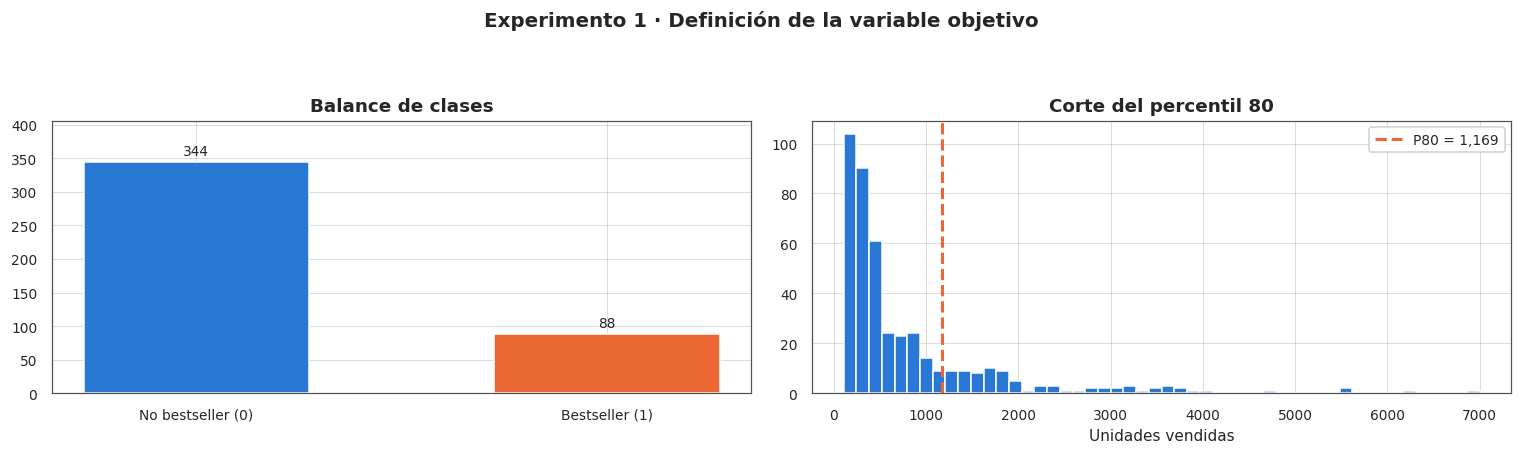

In [19]:
# ============================================================================
#  6.1 Construcción del objetivo is_bestseller
# ============================================================================
# El percentil se calcula sobre el bloque A (recorte de la sección 2.10): es la
# población homogénea en la que "vender mucho" tiene un significado único.
UMBRAL_BESTSELLER = df_feat["units_sold"].quantile(0.80)
y_clf1 = (df_feat["units_sold"] >= UMBRAL_BESTSELLER).astype(int)

print(f"Percentil 80 de units_sold (bloque A): {UMBRAL_BESTSELLER:,.0f} unidades")
print("\nDistribución de clases:")
print(y_clf1.value_counts().rename({0: "No bestseller", 1: "Bestseller"}).to_string())
print(f"\nProporción de positivos: {y_clf1.mean():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
conteo = y_clf1.value_counts().sort_index()
ax[0].bar(["No bestseller (0)", "Bestseller (1)"], conteo.values, color=C_SERIE[:2], width=.55)
ax[0].bar_label(ax[0].containers[0], fmt="%d", padding=3, fontsize=9)
ax[0].set_title("Balance de clases"); ax[0].margins(y=.18)

ax[1].hist(df_feat["units_sold"], bins=50, color=C_SERIE[0])
ax[1].axvline(UMBRAL_BESTSELLER, color=C_SERIE[1], ls="--", lw=2,
              label=f"P80 = {UMBRAL_BESTSELLER:,.0f}")
ax[1].set_title("Corte del percentil 80"); ax[1].set_xlabel("Unidades vendidas"); ax[1].legend()

fig.suptitle("Experimento 1 · Definición de la variable objetivo", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.92]); plt.show()

In [20]:
# ============================================================================
#  6.2 Preparación de datos con FEATURES_MODELO (sección 5.1)
# ============================================================================
X1_tr, X1_te, y1_tr, y1_te, info1 = preparar_datos(
    df_feat, y_clf1,
    estratificar=True,      # mantiene la proporción de clases en train y test
    escalar=None            # los árboles no requieren escalado
)
print("\nProporción de positivos -> train: {:.4f} | test: {:.4f}".format(y1_tr.mean(), y1_te.mean()))

Features       : ['author', 'author_rating', 'genre', 'publisher', 'sale_price', 'book_age', 'price_relative_to_genre', 'book_average_rating', 'book_ratings_count', 'social_proof_score']
One-Hot        : ['author_rating', 'genre', 'publisher']
Target Encoding: ['author']
Escalado       : None
X_train (302, 21) | X_test (130, 21) | features finales: 21

Proporción de positivos -> train: 0.2053 | test: 0.2000


In [21]:
# ============================================================================
#  6.3 Ajuste de hiperparámetros con Optuna (objetivo: PR-AUC)
# ============================================================================
import optuna
from optuna.samplers import TPESampler
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS_EXP1 = 100

neg, pos = int((y1_tr == 0).sum()), int((y1_tr == 1).sum())
SCALE_POS_WEIGHT = neg / pos
print(f"scale_pos_weight = {neg} / {pos} = {SCALE_POS_WEIGHT:.4f}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# El espacio de búsqueda se centra en la región REGULARIZADA: con ~350 filas de
# entrenamiento, los árboles profundos memorizan y el desempeño en test se desploma.
def objetivo_exp1(trial):
    params = dict(
        n_estimators     = trial.suggest_int("n_estimators", 150, 600, step=50),
        max_depth        = trial.suggest_int("max_depth", 1, 4),
        learning_rate    = trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        subsample        = trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree = trial.suggest_float("colsample_bytree", 0.5, 1.0),
        min_child_weight = trial.suggest_int("min_child_weight", 1, 20),
        reg_lambda       = trial.suggest_float("reg_lambda", 1.0, 100.0, log=True),
        reg_alpha        = trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        gamma            = trial.suggest_float("gamma", 1e-8, 5.0, log=True),
    )
    m = XGBClassifier(objective="binary:logistic", eval_metric="aucpr",
                      scale_pos_weight=SCALE_POS_WEIGHT, random_state=RANDOM_STATE,
                      n_jobs=-1, tree_method="hist", **params)
    return cross_val_score(m, X1_tr, y1_tr, cv=cv,
                           scoring="average_precision", n_jobs=-1).mean()

estudio_exp1 = optuna.create_study(direction="maximize",
                                   sampler=TPESampler(seed=RANDOM_STATE),
                                   study_name="xgb_bestseller")
estudio_exp1.optimize(objetivo_exp1, n_trials=N_TRIALS_EXP1, show_progress_bar=True)

print("\nMejores hiperparámetros:")
for k, v in estudio_exp1.best_params.items():
    print(f"  {k:<18} {v}")
print(f"\nPR-AUC promedio en validación cruzada: {estudio_exp1.best_value:.4f}")

xgb_clf = XGBClassifier(objective="binary:logistic", eval_metric="aucpr",
                        scale_pos_weight=SCALE_POS_WEIGHT, random_state=RANDOM_STATE,
                        n_jobs=-1, tree_method="hist",
                        **estudio_exp1.best_params).fit(X1_tr, y1_tr)

scale_pos_weight = 240 / 62 = 3.8710


  0%|          | 0/100 [00:00<?, ?it/s]


Mejores hiperparámetros:
  n_estimators       150
  max_depth          3
  learning_rate      0.129550487857695
  subsample          0.9871346148438952
  colsample_bytree   0.9371262074408613
  min_child_weight   1
  reg_lambda         9.821282882972097
  reg_alpha          5.261610298841717e-07
  gamma              0.009810660838421938

PR-AUC promedio en validación cruzada: 0.7178


EXPERIMENTO 1 — MÉTRICAS EN TEST
  Accuracy   0.8385
  Precision  0.5610
  Recall     0.8846
  F1-Score   0.6866
  ROC-AUC    0.9386
  PR-AUC     0.8261

  Línea base de PR-AUC (prevalencia): 0.2000
  Lift de PR-AUC sobre el azar       : 4.13x

               precision    recall  f1-score   support

No bestseller     0.9663    0.8269    0.8912       104
   Bestseller     0.5610    0.8846    0.6866        26

     accuracy                         0.8385       130
    macro avg     0.7636    0.8558    0.7889       130
 weighted avg     0.8852    0.8385    0.8503       130



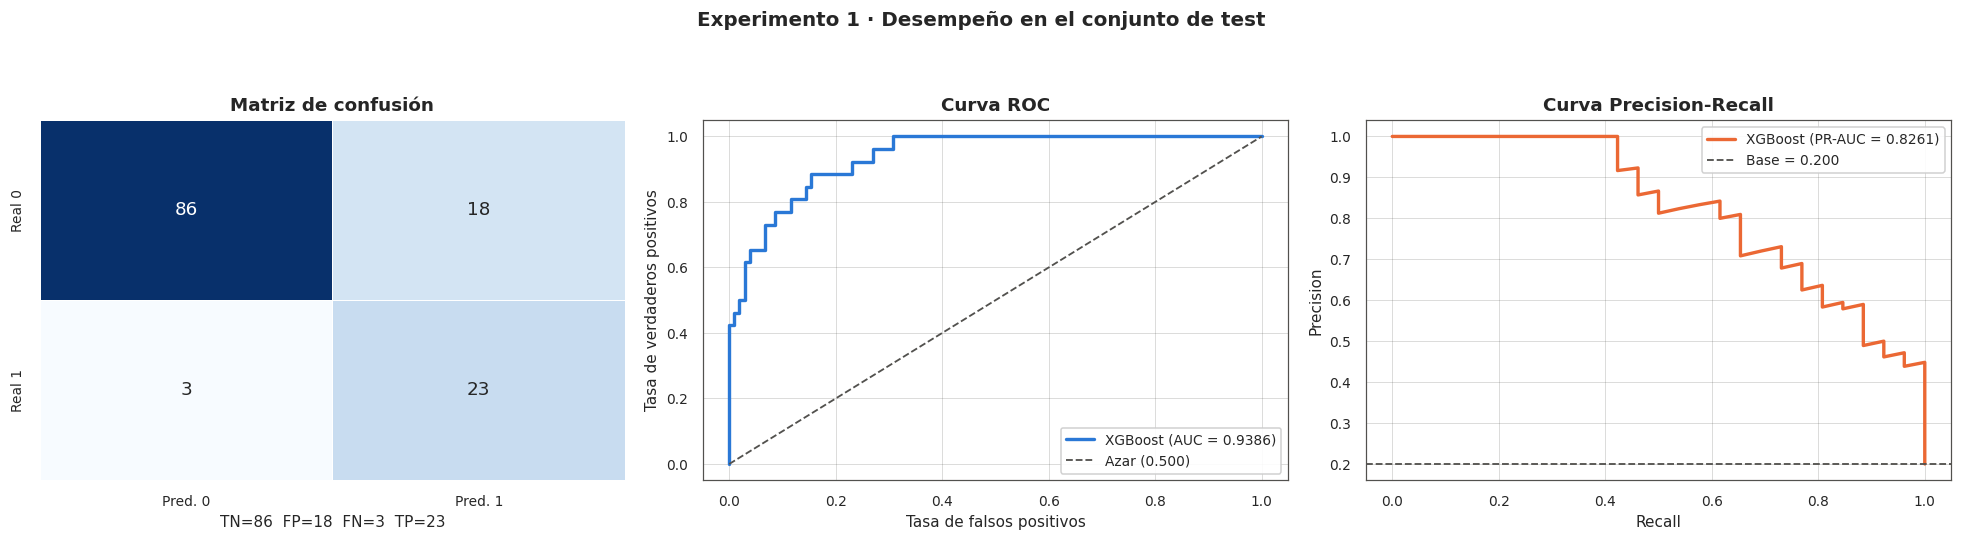

In [22]:
# ============================================================================
#  6.4 Evaluación en el conjunto de test
# ============================================================================
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score,
                             average_precision_score, f1_score, roc_curve,
                             precision_recall_curve, accuracy_score,
                             precision_score, recall_score)

y1_pred  = xgb_clf.predict(X1_te)
y1_proba = xgb_clf.predict_proba(X1_te)[:, 1]

metricas_exp1 = {
    "Accuracy" : accuracy_score(y1_te, y1_pred),
    "Precision": precision_score(y1_te, y1_pred, zero_division=0),
    "Recall"   : recall_score(y1_te, y1_pred, zero_division=0),
    "F1-Score" : f1_score(y1_te, y1_pred, zero_division=0),
    "ROC-AUC"  : roc_auc_score(y1_te, y1_proba),
    "PR-AUC"   : average_precision_score(y1_te, y1_proba),
}
print("=" * 62); print("EXPERIMENTO 1 — MÉTRICAS EN TEST"); print("=" * 62)
for k, v in metricas_exp1.items(): print(f"  {k:<10} {v:.4f}")
print(f"\n  Línea base de PR-AUC (prevalencia): {y1_te.mean():.4f}")
print(f"  Lift de PR-AUC sobre el azar       : {metricas_exp1['PR-AUC'] / y1_te.mean():.2f}x")
print("\n" + classification_report(y1_te, y1_pred,
                                   target_names=["No bestseller", "Bestseller"], digits=4))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
cm = confusion_matrix(y1_te, y1_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0], linewidths=.5,
            xticklabels=["Pred. 0", "Pred. 1"], yticklabels=["Real 0", "Real 1"])
tn, fp, fn, tp = cm.ravel()
ax[0].set_title("Matriz de confusión"); ax[0].set_xlabel(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

fpr, tpr, _ = roc_curve(y1_te, y1_proba)
ax[1].plot(fpr, tpr, lw=2.2, color=C_SERIE[0], label=f"XGBoost (AUC = {metricas_exp1['ROC-AUC']:.4f})")
ax[1].plot([0, 1], [0, 1], ls="--", lw=1.2, color=C_REF, label="Azar (0.500)")
ax[1].set_xlabel("Tasa de falsos positivos"); ax[1].set_ylabel("Tasa de verdaderos positivos")
ax[1].set_title("Curva ROC"); ax[1].legend(loc="lower right")

prec, rec, _ = precision_recall_curve(y1_te, y1_proba)
ax[2].plot(rec, prec, lw=2.2, color=C_SERIE[1], label=f"XGBoost (PR-AUC = {metricas_exp1['PR-AUC']:.4f})")
ax[2].axhline(y1_te.mean(), ls="--", lw=1.2, color=C_REF, label=f"Base = {y1_te.mean():.3f}")
ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision")
ax[2].set_title("Curva Precision-Recall"); ax[2].legend(loc="upper right")

fig.suptitle("Experimento 1 · Desempeño en el conjunto de test", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

Beeswarm: cada punto es un libro del test. Eje X = impacto en el log-odds de
ser bestseller; color = valor de la feature.



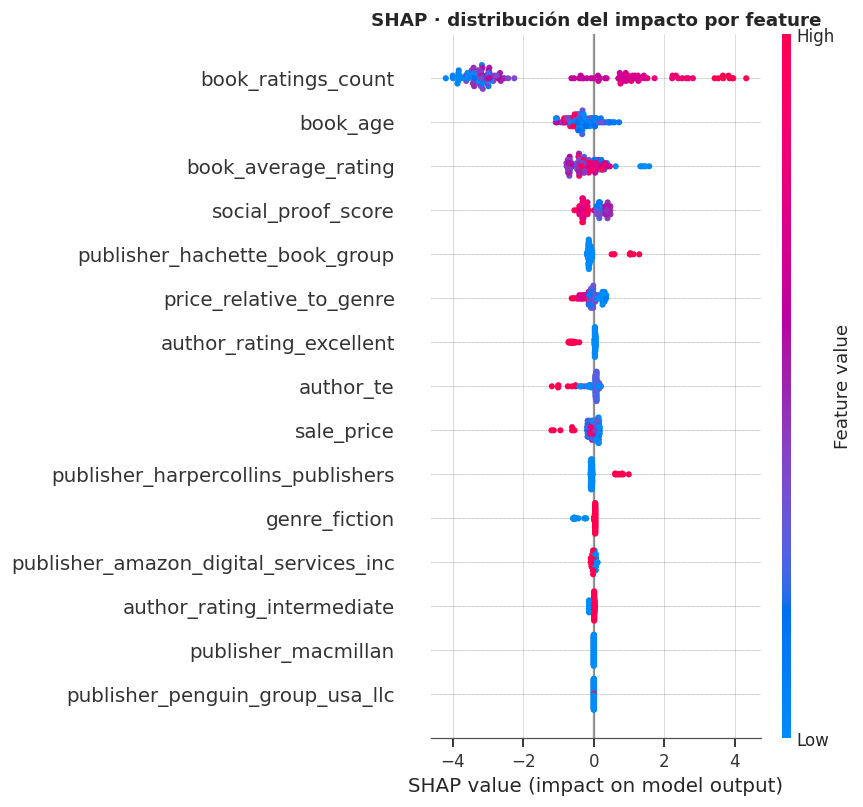

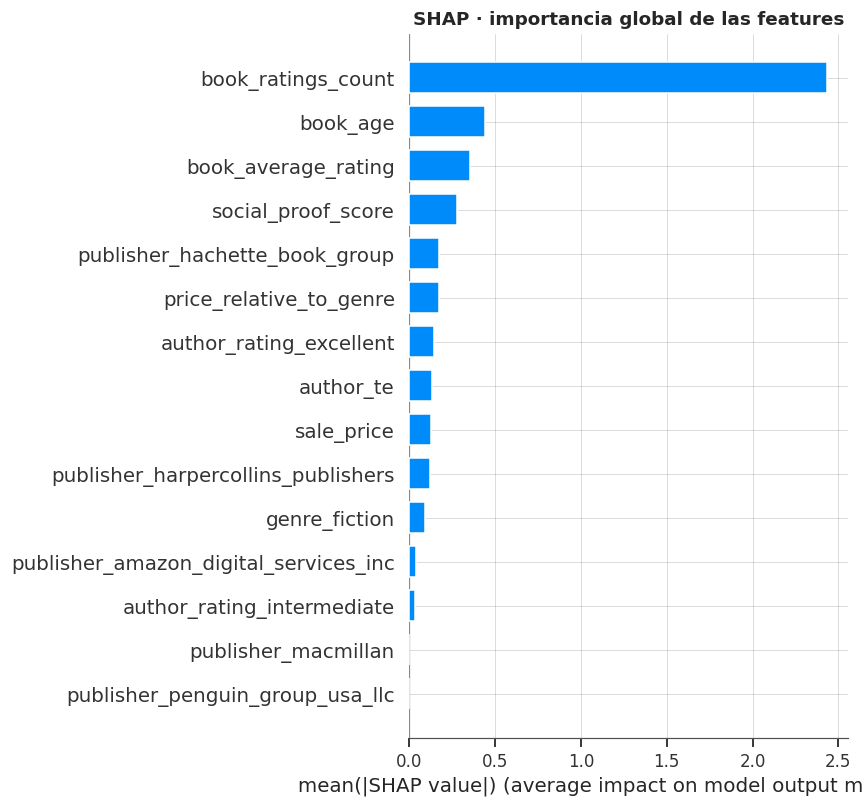


SHAP (local y consistente) vs. importancia por ganancia (global y sesgada):


,SHAP_medio,Ganancia_XGB,rank_shap,rank_gain
book_ratings_count,2.44,0.31,1,1
book_age,0.44,0.07,2,4
book_average_rating,0.35,0.06,3,7
social_proof_score,0.28,0.06,4,8
publisher_hachette_book_group,0.18,0.07,5,6
price_relative_to_genre,0.18,0.07,6,5
author_rating_excellent,0.14,0.09,7,2
author_te,0.13,0.05,8,9
sale_price,0.13,0.08,9,3
publisher_harpercollins_publishers,0.12,0.05,10,10



Caso individual — índice 31 | probabilidad 0.9855 | clase real 1


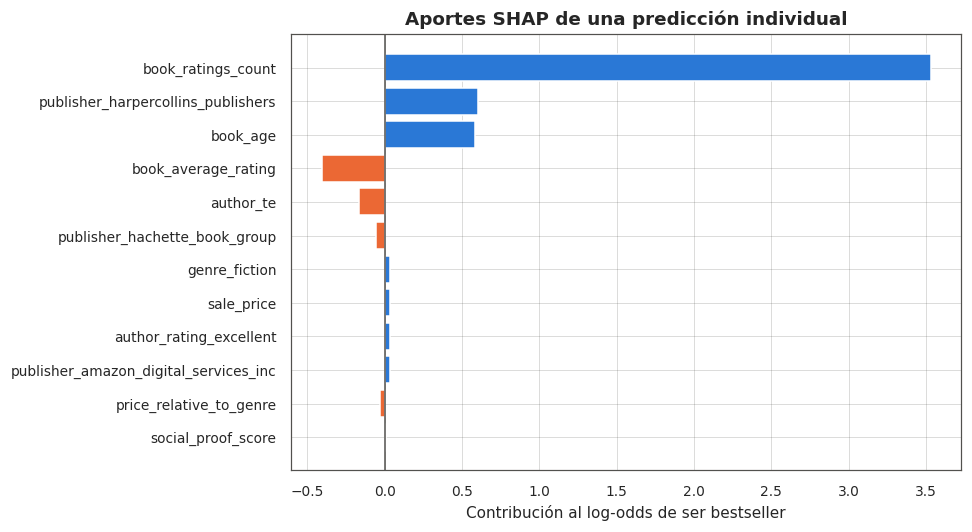

In [23]:
# ============================================================================
#  6.7 Explicabilidad con SHAP
# ============================================================================
import shap

explainer   = shap.TreeExplainer(xgb_clf)
shap_values = explainer.shap_values(X1_te)

print("Beeswarm: cada punto es un libro del test. Eje X = impacto en el log-odds de")
print("ser bestseller; color = valor de la feature.\n")
shap.summary_plot(shap_values, X1_te, plot_type="dot", show=False, max_display=15)
plt.title("SHAP · distribución del impacto por feature", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

shap.summary_plot(shap_values, X1_te, plot_type="bar", show=False, max_display=15)
plt.title("SHAP · importancia global de las features", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

imp_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=X1_te.columns, name="SHAP_medio")
imp_gain = pd.Series(xgb_clf.feature_importances_, index=X1_te.columns, name="Ganancia_XGB")
comparacion = (pd.concat([imp_shap, imp_gain], axis=1)
                 .assign(rank_shap=lambda d: d["SHAP_medio"].rank(ascending=False).astype(int),
                         rank_gain=lambda d: d["Ganancia_XGB"].rank(ascending=False).astype(int))
                 .sort_values("SHAP_medio", ascending=False))
print("\nSHAP (local y consistente) vs. importancia por ganancia (global y sesgada):")
display(comparacion.head(12))

idx_max = int(np.argmax(y1_proba))
print(f"\nCaso individual — índice {X1_te.index[idx_max]} | "
      f"probabilidad {y1_proba[idx_max]:.4f} | clase real {int(y1_te.iloc[idx_max])}")
aporte = pd.Series(shap_values[idx_max, :], index=X1_te.columns)
aporte = aporte.reindex(aporte.abs().sort_values(ascending=False).index).head(12)[::-1]
plt.figure(figsize=(9, 5))
plt.barh(aporte.index, aporte.values,
         color=[C_SERIE[1] if v < 0 else C_SERIE[0] for v in aporte.values])
plt.axvline(0, color=C_REF, lw=1)
plt.title("Aportes SHAP de una predicción individual")
plt.xlabel("Contribución al log-odds de ser bestseller")
plt.tight_layout(); plt.show()

In [24]:
# ============================================================================
#  ANEXO · Prueba de humo de XGBoost con 10 observaciones sintéticas
# ----------------------------------------------------------------------------
#  Estos datos NO forman parte del análisis: son inventados a propósito para
#  verificar que el clasificador funciona como se espera sobre una regla
#  conocida de antemano. Ninguna conclusión del TP se apoya en esta celda.
# ============================================================================
from xgboost import XGBClassifier

# Regla verdadera que inventamos:  bestseller  <=>  precio < 20  Y  rating > 4.0
demo = pd.DataFrame({
    "sale_price"         : [ 12.0,  15.0,   8.0,  45.0,  50.0,  18.0,  30.0,  10.0,  40.0,  22.0],
    "book_average_rating": [  4.5,   4.2,   4.8,   4.9,   3.1,   4.6,   4.4,   3.2,   2.8,   4.7],
    "book_ratings_count" : [ 5000,  3000,  9000,  7000,   400,  6000,  2000,  8000,   300,  1500],
})
demo["is_bestseller"] = ((demo["sale_price"] < 20) & (demo["book_average_rating"] > 4.0)).astype(int)

print("Datos de prueba (la regla verdadera es: precio < 20 Y rating > 4.0)")
print(demo.to_string(index=False))
print(f"\nPositivos: {demo['is_bestseller'].sum()} de {len(demo)}")

X_demo = demo.drop(columns="is_bestseller")
y_demo = demo["is_bestseller"]

neg, pos = int((y_demo == 0).sum()), int((y_demo == 1).sum())
modelo_demo = XGBClassifier(
    objective="binary:logistic", eval_metric="logloss",
    n_estimators=30, max_depth=2, learning_rate=0.3,
    scale_pos_weight=neg / pos, random_state=42,
).fit(X_demo, y_demo)

proba = modelo_demo.predict_proba(X_demo)[:, 1]
resultado = demo.assign(prob_predicha=proba.round(4),
                        pred_umbral_050=(proba >= 0.5).astype(int))
print("\n--- Predicción sobre los MISMOS datos de entrenamiento ---")
print(resultado[["sale_price", "book_average_rating", "is_bestseller",
                 "prob_predicha", "pred_umbral_050"]].to_string(index=False))
aciertos = (resultado["pred_umbral_050"] == resultado["is_bestseller"]).sum()
print(f"Aciertos: {aciertos}/{len(demo)}  <-- con 10 filas esto NO significa nada:")
print("el modelo tiene capacidad de sobra para memorizarlas. Es una prueba de")
print("MECÁNICA (¿corre, devuelve probabilidades coherentes?), no de desempeño.")

# --- La prueba que sí informa: 3 libros nuevos que el modelo nunca vio
nuevos = pd.DataFrame({
    "sale_price"         : [ 14.0,  38.0,  16.0],
    "book_average_rating": [  4.7,   4.8,   3.5],
    "book_ratings_count" : [ 4000,  5500,  7000],
})
esperado = ((nuevos["sale_price"] < 20) & (nuevos["book_average_rating"] > 4.0)).astype(int)
p_nuevos = modelo_demo.predict_proba(nuevos)[:, 1]

print("\n--- Generalización: 3 libros nuevos ---")
print(nuevos.assign(regla_verdadera=esperado.values,
                    prob_predicha=p_nuevos.round(4),
                    prediccion=(p_nuevos >= 0.5).astype(int)).to_string(index=False))
ok = ((p_nuevos >= 0.5).astype(int) == esperado.values).all()
print(f"\n¿Recuperó la regla en casos no vistos?  {'SÍ' if ok else 'NO'}")

print("\n--- Qué variables usó ---")
print(pd.Series(modelo_demo.feature_importances_, index=X_demo.columns)
        .sort_values(ascending=False).round(4).to_string())
print("\nbook_ratings_count es ruido por construcción: su importancia debería ser baja.")

Datos de prueba (la regla verdadera es: precio < 20 Y rating > 4.0)
 sale_price  book_average_rating  book_ratings_count  is_bestseller
      12.00                 4.50                5000              1
      15.00                 4.20                3000              1
       8.00                 4.80                9000              1
      45.00                 4.90                7000              0
      50.00                 3.10                 400              0
      18.00                 4.60                6000              1
      30.00                 4.40                2000              0
      10.00                 3.20                8000              0
      40.00                 2.80                 300              0
      22.00                 4.70                1500              0

Positivos: 4 de 10

--- Predicción sobre los MISMOS datos de entrenamiento ---
 sale_price  book_average_rating  is_bestseller  prob_predicha  pred_umbral_050
      12.00             

Acierto sobre 4.000 casos nuevos, promedio de 5 semillas:
 n_entrenamiento  acierto
              10    84.90
              20    86.40
              30    97.40
              50    96.50
              80    97.50
             120    99.40
             200    98.90
             400    99.70
             800    99.90


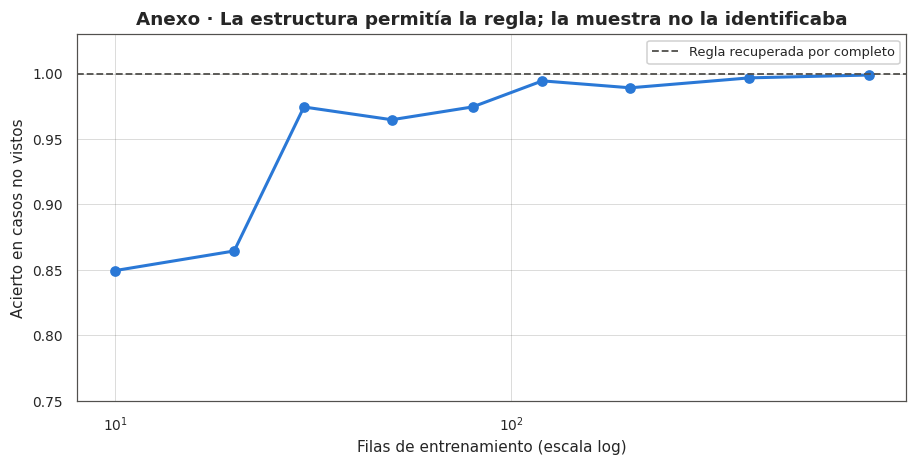


La transición ocurre entre 20 y 30 filas: ahí aparecen suficientes casos
'barato pero mal calificado' como para que el segundo corte resulte rentable.


In [25]:
# ============================================================================
#  ANEXO (cont.) · ¿Cuántas observaciones hacen falta para recuperar la regla?
# ----------------------------------------------------------------------------
#  Repite la prueba de humo con muestras sintéticas de distinto tamaño y evalúa
#  sobre 4.000 casos nuevos. Produce los números citados en la lectura siguiente.
# ============================================================================
def _probar_tamano(n, semilla):
    rg = np.random.default_rng(semilla)
    d = pd.DataFrame({
        "sale_price"         : rg.uniform(5, 55, n).round(2),
        "book_average_rating": rg.uniform(2.5, 5.0, n).round(2),
        "book_ratings_count" : rg.integers(200, 9000, n),
    })
    yy = ((d["sale_price"] < 20) & (d["book_average_rating"] > 4.0)).astype(int)
    if yy.nunique() < 2:
        return np.nan
    mm = XGBClassifier(objective="binary:logistic", eval_metric="logloss",
                       n_estimators=30, max_depth=2, learning_rate=0.3,
                       scale_pos_weight=(yy == 0).sum() / max((yy == 1).sum(), 1),
                       random_state=RANDOM_STATE).fit(d, yy)
    rv = np.random.default_rng(999)
    t = pd.DataFrame({"sale_price": rv.uniform(5, 55, 4000).round(2),
                      "book_average_rating": rv.uniform(2.5, 5.0, 4000).round(2),
                      "book_ratings_count": rv.integers(200, 9000, 4000)})
    yt = ((t["sale_price"] < 20) & (t["book_average_rating"] > 4.0)).astype(int)
    return float(((mm.predict_proba(t)[:, 1] >= .5).astype(int) == yt).mean())

TAMANOS = [10, 20, 30, 50, 80, 120, 200, 400, 800]
curva = pd.DataFrame({
    "n_entrenamiento": TAMANOS,
    "acierto_generalizacion": [np.nanmean([_probar_tamano(n, s) for s in range(5)]) for n in TAMANOS],
})
print("Acierto sobre 4.000 casos nuevos, promedio de 5 semillas:")
print(curva.assign(acierto=lambda d: (d["acierto_generalizacion"] * 100).round(1))
           .drop(columns="acierto_generalizacion").to_string(index=False))

plt.figure(figsize=(8.5, 4.4))
plt.plot(curva["n_entrenamiento"], curva["acierto_generalizacion"], "o-", lw=2,
         color=C_SERIE[0], markersize=6)
plt.axhline(1.0, color=C_REF, ls="--", lw=1.2, label="Regla recuperada por completo")
plt.xscale("log"); plt.ylim(0.75, 1.03)
plt.xlabel("Filas de entrenamiento (escala log)"); plt.ylabel("Acierto en casos no vistos")
plt.title("Anexo · La estructura permitía la regla; la muestra no la identificaba")
plt.legend(fontsize=8.5); plt.tight_layout(); plt.show()

print("\nLa transición ocurre entre 20 y 30 filas: ahí aparecen suficientes casos")
print("'barato pero mal calificado' como para que el segundo corte resulte rentable.")

### Lectura del resultado

**El modelo no aprendió la regla, y eso es lo valioso de la prueba.** Falló en los dos libros baratos
pero mal calificados —precio 10 / rating 3.2 y precio 16 / rating 3.5— marcándolos como bestsellers.
Lo que aprendió fue esencialmente *"barato ⇒ bestseller"*, ignorando la segunda condición.

El diagnóstico no es que el modelo sea incapaz de representar la regla: `max_depth=2` permite
exactamente dos condiciones anidadas, que es lo que la regla necesita. **El problema son los datos.**
Con 10 filas y sólo 4 positivos no hay ningún ejemplo del caso crítico —barato *pero* mal
calificado—, y sin esa evidencia el árbol no tiene por qué descubrir que la regla es una conjunción
en lugar de una sola condición sobre el precio.

Es la distinción entre **capacidad de representación** y **capacidad de identificación**: que una
familia de modelos pueda expresar una función no significa que una muestra dada alcance para
encontrarla.

#### Cuántos datos hacen falta

La celda anterior repite el experimento con muestras de distinto tamaño y evalúa sobre 4.000 casos
nuevos (promedio de 5 semillas):

| Filas de entrenamiento | Acierto sobre casos no vistos |
|---:|---:|
| 10 | 84.9 % |
| 20 | 86.4 % |
| **30** | **97.4 %** |
| 120 | 99.4 % |
| 800 | 99.9 % |

El salto está entre 20 y 30 filas: ahí aparecen suficientes casos "barato pero mal calificado" como
para que el segundo corte se vuelva rentable en términos de ganancia. A partir de ~120 filas la regla
queda prácticamente recuperada.

#### Lo que sí funcionó

Dos señales confirman que la mecánica del clasificador es correcta:

- **`book_ratings_count` quedó con importancia 0.0000.** Esa variable es ruido por construcción —no
  interviene en la regla verdadera— y el modelo la descartó por completo. Un valor alto ahí habría
  indicado que el modelo estaba ajustando ruido.
- **Las probabilidades son coherentes**: monótonas respecto del precio y agrupadas en pocos valores
  discretos. Eso es exactamente lo esperable de un ensamble de árboles poco profundos: hay pocas
  hojas, y todas las observaciones que caen en la misma hoja reciben idéntica probabilidad.

> **Por qué esta prueba importa para el trabajo.** El dataset real tiene ~1.000 libros y una fracción
> importante de la variación en ventas proviene de factores no observados (marketing, timing, boca a
> boca). Este anexo muestra en miniatura el mismo fenómeno que limita al Experimento 1: cuando faltan
> ejemplos de las combinaciones que discriminan, el modelo se queda con la regla más simple que los
> datos soportan. No es un defecto del algoritmo, es información que no está en la muestra.

---
## 7. Experimento 2 — Regresión de demanda y elasticidad de precio

### Por qué se modela $\log(1+y)$ y no $y$

La variable `units_sold` tiene asimetría positiva fuerte también dentro del bloque conservado en
2.10. Trabajar con $z = \log(1+y)$ tiene tres consecuencias:

1. **Estabiliza la varianza.** Si el error es multiplicativo ($y = \mu \cdot \varepsilon$), el
   logaritmo lo vuelve aditivo ($\log y = \log\mu + \log\varepsilon$), que es el supuesto de la
   pérdida cuadrática.
2. **Cambia la métrica implícita a error relativo.** Minimizar el error cuadrático en escala
   logarítmica equivale a minimizar el error *porcentual* en escala original.
3. **`log1p` en lugar de `log`** porque $\log(0)$ diverge y el catálogo contiene libros con ventas
   muy bajas. Su inversa exacta es `expm1`.

> **Nota sobre normalidad.** Ni los árboles ni el *boosting* asumen que $y$ sea normal; el supuesto
> de normalidad, en los modelos que lo tienen, recae sobre los **residuos** y sólo importa para la
> inferencia. La transformación se justifica por los puntos 1 y 2, no por "normalizar".

> **Sesgo de retransformación.** $\mathbb{E}[y] \neq \exp(\mathbb{E}[\log y]) - 1$ por la desigualdad
> de Jensen: al deshacer el logaritmo se obtiene aproximadamente la **mediana** condicional, no la
> media. Es un estimador conservador y válido para comparar escenarios de precio, que es el uso que
> se le da acá.

| Aspecto | XGBoost | LightGBM |
|---|---|---|
| Crecimiento del árbol | *level-wise*: expande todos los nodos de un nivel | *leaf-wise*: expande la hoja de mayor pérdida |
| Consecuencia | árboles balanceados, más regularizados | árboles profundos y asimétricos, menor pérdida con igual número de hojas, mayor riesgo de sobreajuste |
| Búsqueda de cortes | pre-ordenado / histogramas | histogramas + GOSS + EFB |
| Control de complejidad | `max_depth` | `num_leaves` y `min_child_samples` |
| Velocidad | menor | mayor, sobre todo con muchas features |

Con datasets medianos, el crecimiento *leaf-wise* de LightGBM tiende a sobreajustar si no se limitan
`num_leaves` y `min_child_samples`. Ésa es la hipótesis que el experimento contrasta.


In [26]:
# ============================================================================
#  7.1 Objetivo: log1p(units_sold) y preparación de datos
# ============================================================================
y_reg = np.log1p(df_feat["units_sold"])

print(f"units_sold   -> media {df_feat['units_sold'].mean():>12,.1f} | "
      f"mediana {df_feat['units_sold'].median():>10,.1f} | std {df_feat['units_sold'].std():>12,.1f}")
print(f"log1p(units) -> media {y_reg.mean():>12.4f} | "
      f"mediana {y_reg.median():>10.4f} | std {y_reg.std():>12.4f}\n")

X2_tr, X2_te, y2_tr, y2_te, info2 = preparar_datos(
    df_feat, y_reg,
    estratificar=False,
    escalar=None
)

units_sold   -> media        782.8 | mediana      430.5 | std        950.3
log1p(units) -> media       6.1395 | mediana     6.0673 | std       1.0147

Features       : ['author', 'author_rating', 'genre', 'publisher', 'sale_price', 'book_age', 'price_relative_to_genre', 'book_average_rating', 'book_ratings_count', 'social_proof_score']
One-Hot        : ['author_rating', 'genre', 'publisher']
Target Encoding: ['author']
Escalado       : None
X_train (302, 21) | X_test (130, 21) | features finales: 21


In [27]:
# ============================================================================
#  7.2 Modelos base sin ajustar (referencia)
# ============================================================================
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.dummy import DummyRegressor

def evaluar_regresion(nombre, modelo, X_te, y_te_log):
    '''Métricas en escala logarítmica (donde se optimiza) y en unidades (donde se decide).'''
    pred_log = modelo.predict(X_te)
    real_u, pred_u = np.expm1(y_te_log), np.expm1(pred_log)
    return {
        "Modelo"   : nombre,
        "RMSE_log" : float(np.sqrt(mean_squared_error(y_te_log, pred_log))),
        "MAE_log"  : float(mean_absolute_error(y_te_log, pred_log)),
        "R2_log"   : float(r2_score(y_te_log, pred_log)),
        "RMSE_unid": float(np.sqrt(mean_squared_error(real_u, pred_u))),
        "MAE_unid" : float(mean_absolute_error(real_u, pred_u)),
        "R2_unid"  : float(r2_score(real_u, pred_u)),
    }

resultados_exp2 = []
dummy = DummyRegressor(strategy="mean").fit(X2_tr, y2_tr)
resultados_exp2.append(evaluar_regresion("Baseline (media)", dummy, X2_te, y2_te))

xgb_reg_base = XGBRegressor(objective="reg:squarederror", random_state=RANDOM_STATE,
                            n_jobs=-1, tree_method="hist").fit(X2_tr, y2_tr)
resultados_exp2.append(evaluar_regresion("XGBoost (default)", xgb_reg_base, X2_te, y2_te))

lgb_reg_base = LGBMRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1).fit(X2_tr, y2_tr)
resultados_exp2.append(evaluar_regresion("LightGBM (default)", lgb_reg_base, X2_te, y2_te))

display(pd.DataFrame(resultados_exp2).set_index("Modelo"))

,RMSE_log,MAE_log,R2_log,RMSE_unid,MAE_unid,R2_unid
Modelo,,,,,,
Baseline (media),1.15,0.97,-0.03,"1,243.90",727.60,-0.22
XGBoost (default),0.62,0.44,0.70,"1,015.56",517.47,0.19
LightGBM (default),0.58,0.42,0.73,878.20,431.37,0.39


In [28]:
# ============================================================================
#  7.3 Optimización con Optuna — XGBoost
# ============================================================================
import optuna
from optuna.samplers import TPESampler
from sklearn.model_selection import KFold, cross_val_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 100           # presupuesto de evaluaciones del sampler TPE
CV_REG   = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def objetivo_xgb(trial):
    params = {
        "n_estimators"     : trial.suggest_int("n_estimators", 200, 900, step=100),
        "max_depth"        : trial.suggest_int("max_depth", 3, 10),
        "learning_rate"    : trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample"        : trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree" : trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight" : trial.suggest_int("min_child_weight", 1, 10),
        "reg_alpha"        : trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda"       : trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        "gamma"            : trial.suggest_float("gamma", 1e-8, 5.0, log=True),
    }
    modelo = XGBRegressor(objective="reg:squarederror", random_state=RANDOM_STATE,
                          n_jobs=-1, tree_method="hist", **params)
    return -cross_val_score(modelo, X2_tr, y2_tr, cv=CV_REG,
                            scoring="neg_root_mean_squared_error", n_jobs=-1).mean()

estudio_xgb = optuna.create_study(direction="minimize",
                                  sampler=TPESampler(seed=RANDOM_STATE),
                                  study_name="xgb_units_sold")
estudio_xgb.optimize(objetivo_xgb, n_trials=N_TRIALS, show_progress_bar=True)

print(f"\nMejor RMSE (log, validación cruzada): {estudio_xgb.best_value:.4f}")
print("Mejores hiperparámetros XGBoost:")
for k, v in estudio_xgb.best_params.items():
    print(f"  {k:<18} {v}")

xgb_reg = XGBRegressor(objective="reg:squarederror", random_state=RANDOM_STATE,
                       n_jobs=-1, tree_method="hist", **estudio_xgb.best_params).fit(X2_tr, y2_tr)

  0%|          | 0/100 [00:00<?, ?it/s]


Mejor RMSE (log, validación cruzada): 0.4710
Mejores hiperparámetros XGBoost:
  n_estimators       200
  max_depth          8
  learning_rate      0.1603295900904233
  subsample          0.8666750515141666
  colsample_bytree   0.9123112823794642
  min_child_weight   2
  reg_alpha          5.389248123734715e-08
  reg_lambda         0.0017549940461028893
  gamma              0.4031090227997606


In [29]:
# ============================================================================
#  7.4 Optimización con Optuna — LightGBM
# ============================================================================
def objetivo_lgbm(trial):
    params = {
        "n_estimators"     : trial.suggest_int("n_estimators", 200, 900, step=100),
        "num_leaves"       : trial.suggest_int("num_leaves", 8, 128, log=True),
        "max_depth"        : trial.suggest_int("max_depth", 3, 12),
        "learning_rate"    : trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample"        : trial.suggest_float("subsample", 0.6, 1.0),
        "subsample_freq"   : trial.suggest_int("subsample_freq", 1, 5),
        "colsample_bytree" : trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 60),
        "reg_alpha"        : trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda"       : trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
    }
    modelo = LGBMRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1, **params)
    return -cross_val_score(modelo, X2_tr, y2_tr, cv=CV_REG,
                            scoring="neg_root_mean_squared_error", n_jobs=-1).mean()

estudio_lgbm = optuna.create_study(direction="minimize",
                                   sampler=TPESampler(seed=RANDOM_STATE),
                                   study_name="lgbm_units_sold")
estudio_lgbm.optimize(objetivo_lgbm, n_trials=N_TRIALS, show_progress_bar=True)

print(f"\nMejor RMSE (log, validación cruzada): {estudio_lgbm.best_value:.4f}")
print("Mejores hiperparámetros LightGBM:")
for k, v in estudio_lgbm.best_params.items():
    print(f"  {k:<18} {v}")

lgb_reg = LGBMRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1,
                        **estudio_lgbm.best_params).fit(X2_tr, y2_tr)

  0%|          | 0/100 [00:00<?, ?it/s]


Mejor RMSE (log, validación cruzada): 0.4872
Mejores hiperparámetros LightGBM:
  n_estimators       200
  num_leaves         31
  max_depth          10
  learning_rate      0.135924127685957
  subsample          0.9366956075731359
  subsample_freq     2
  colsample_bytree   0.8054653428248835
  min_child_samples  11
  reg_alpha          1.4509648127973841e-08
  reg_lambda         1.5588058144577e-05


EXPERIMENTO 2 — COMPARATIVA EN TEST


,RMSE_log,MAE_log,R2_log,RMSE_unid,MAE_unid,R2_unid
Modelo,,,,,,
Baseline (media),1.15,0.97,-0.03,"1,243.90",727.60,-0.22
XGBoost (default),0.62,0.44,0.70,"1,015.56",517.47,0.19
LightGBM (default),0.58,0.42,0.73,878.20,431.37,0.39
XGBoost (Optuna),0.58,0.42,0.74,912.27,464.06,0.35
LightGBM (Optuna),0.62,0.47,0.70,927.72,504.81,0.32



Modelo ganador por RMSE en escala logarítmica: XGBoost (Optuna)
  RMSE_log 0.5759 | R2_log 0.7413 | R2 del baseline -0.0268


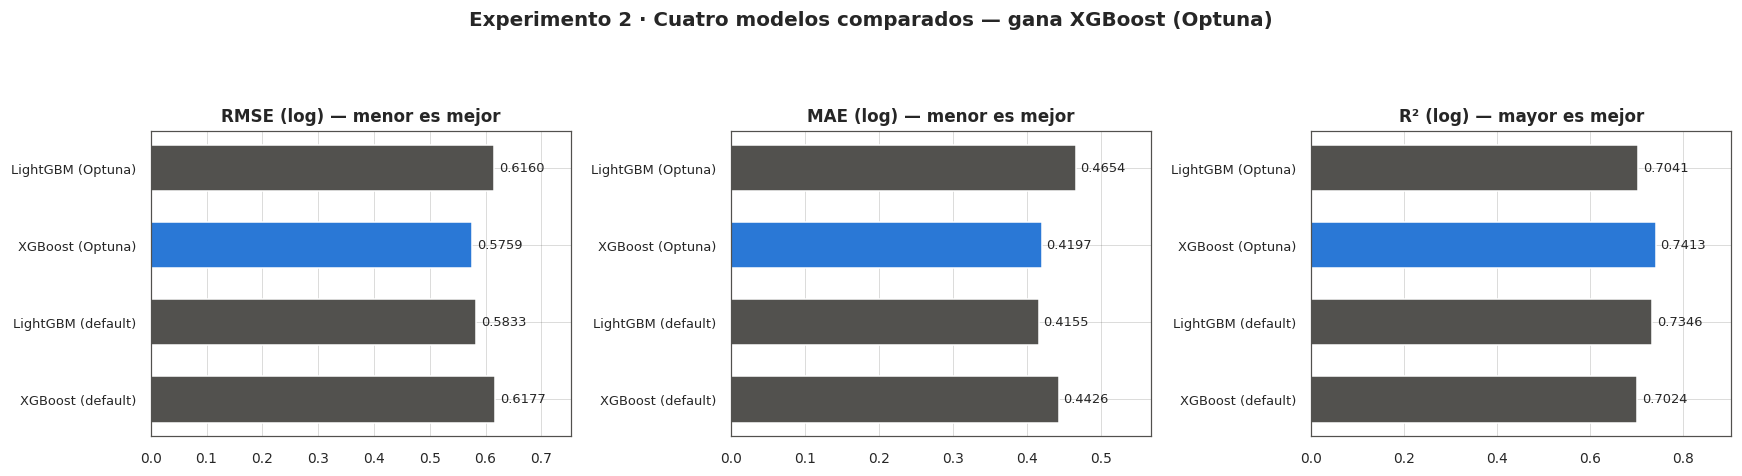

In [30]:
# ============================================================================
#  7.5 Comparativa final en test y selección del modelo ganador
# ============================================================================
resultados_exp2.append(evaluar_regresion("XGBoost (Optuna)",  xgb_reg, X2_te, y2_te))
resultados_exp2.append(evaluar_regresion("LightGBM (Optuna)", lgb_reg, X2_te, y2_te))

tabla_exp2 = pd.DataFrame(resultados_exp2).set_index("Modelo")
print("=" * 78)
print("EXPERIMENTO 2 — COMPARATIVA EN TEST")
print("=" * 78)
display(tabla_exp2)

# Registro explícito nombre -> objeto entrenado. Elegir el modelo con una condición
# sobre el texto del nombre ("si dice XGBoost, usá xgb_reg") confundiría la variante
# por defecto con la optimizada, que son modelos distintos.
MODELOS_REG = {
    "XGBoost (default)" : xgb_reg_base,
    "LightGBM (default)": lgb_reg_base,
    "XGBoost (Optuna)"  : xgb_reg,
    "LightGBM (Optuna)" : lgb_reg,
}
GANADOR_REG_NOMBRE = tabla_exp2.drop(index=["Baseline (media)"])["RMSE_log"].idxmin()
MODELO_DEMANDA     = MODELOS_REG[GANADOR_REG_NOMBRE]

print(f"\nModelo ganador por RMSE en escala logarítmica: {GANADOR_REG_NOMBRE}")
print(f"  RMSE_log {tabla_exp2.loc[GANADOR_REG_NOMBRE, 'RMSE_log']:.4f}"
      f" | R2_log {tabla_exp2.loc[GANADOR_REG_NOMBRE, 'R2_log']:.4f}"
      f" | R2 del baseline {tabla_exp2.loc['Baseline (media)', 'R2_log']:.4f}")
if "default" in GANADOR_REG_NOMBRE:
    print("\n  Nota: gana un modelo SIN optimizar. Con ~345 filas de entrenamiento, Optuna")
    print("  puede ajustarse al ruido de los folds de validación y perder en test. No es un")
    print("  error del procedimiento: es la razón por la que los modelos base están en la tabla.")

comp = tabla_exp2.drop(index=["Baseline (media)"])[["RMSE_log", "MAE_log", "R2_log"]]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
colores = [C_SERIE[0] if n == GANADOR_REG_NOMBRE else C_REF for n in comp.index]
for a, (col, titulo) in zip(ax, [("RMSE_log", "RMSE (log) — menor es mejor"),
                                 ("MAE_log",  "MAE (log) — menor es mejor"),
                                 ("R2_log",   "R² (log) — mayor es mejor")]):
    a.barh(comp.index, comp[col].values, color=colores, height=.6)
    a.bar_label(a.containers[0], fmt="%.4f", padding=3, fontsize=8.5)
    a.set_title(titulo, fontsize=11); a.margins(x=.22)
    a.tick_params(axis="y", labelsize=8.5)
fig.suptitle(f"Experimento 2 · Cuatro modelos comparados — gana {GANADOR_REG_NOMBRE}",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.9]); plt.show()

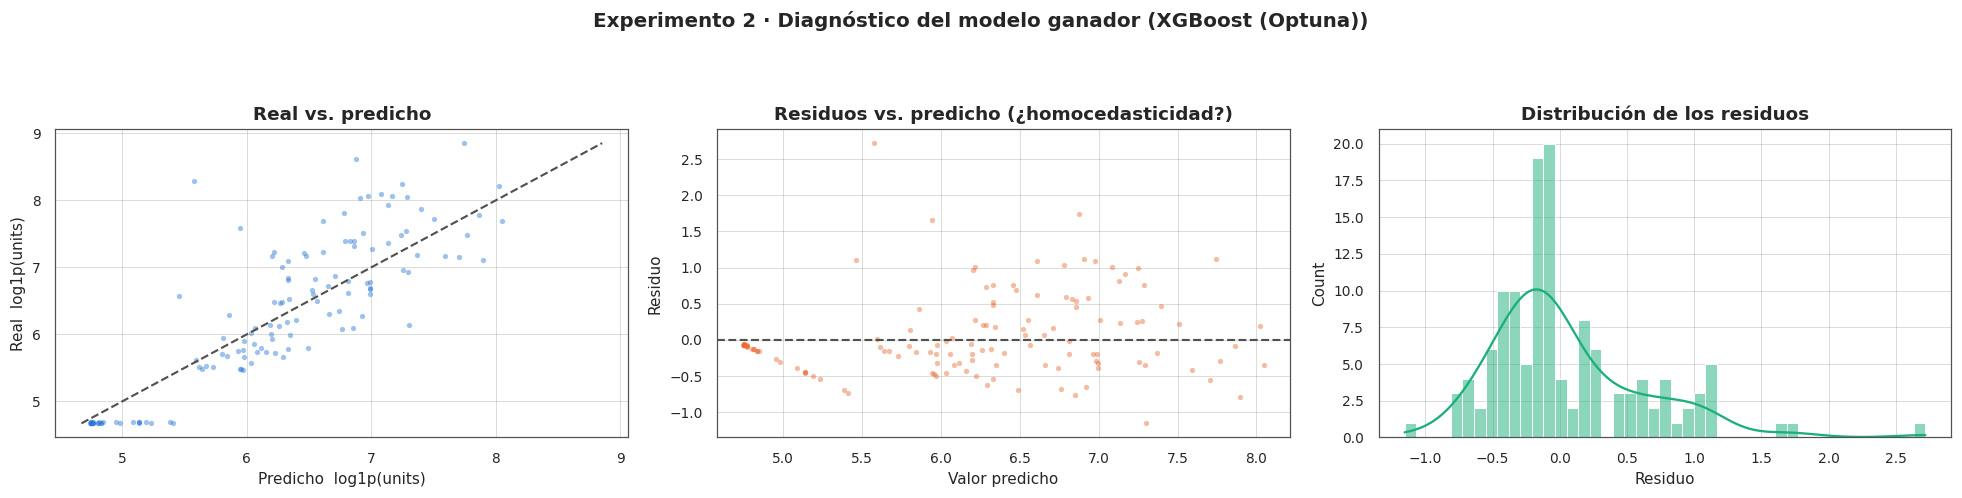

Media de residuos 0.0492 | Desvío 0.5738
Un patrón de embudo en el panel central indicaría heterocedasticidad residual;
residuos centrados en 0 y aproximadamente simétricos validan el uso de RMSE.



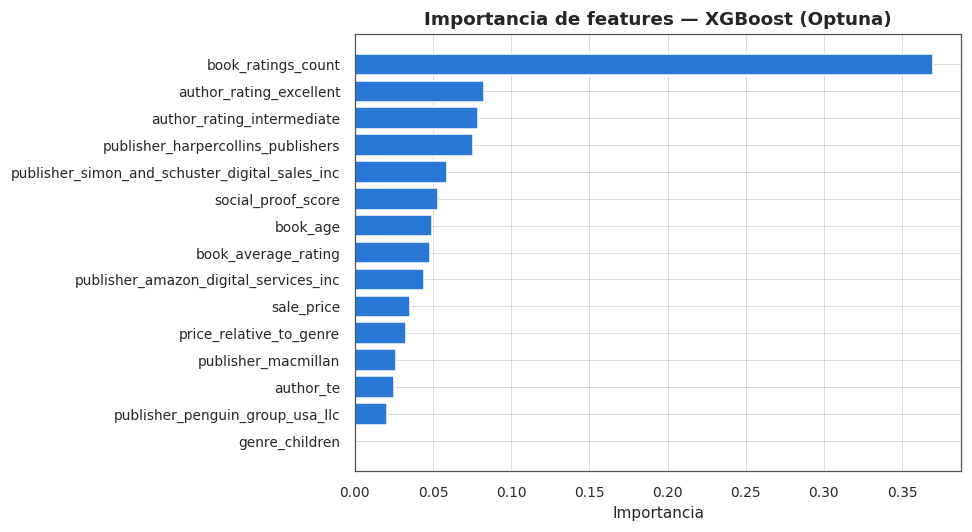

In [31]:
# ============================================================================
#  7.6 Diagnóstico de residuos e importancia de features
# ============================================================================
pred_log = MODELO_DEMANDA.predict(X2_te)
resid    = y2_te.values - pred_log

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))

ax[0].scatter(pred_log, y2_te, s=12, alpha=.45, color=C_SERIE[0], linewidths=0)
lims = [min(pred_log.min(), y2_te.min()), max(pred_log.max(), y2_te.max())]
ax[0].plot(lims, lims, ls="--", lw=1.4, color=C_REF)
ax[0].set_xlabel("Predicho  log1p(units)"); ax[0].set_ylabel("Real  log1p(units)")
ax[0].set_title("Real vs. predicho")

ax[1].scatter(pred_log, resid, s=12, alpha=.45, color=C_SERIE[1], linewidths=0)
ax[1].axhline(0, ls="--", lw=1.4, color=C_REF)
ax[1].set_xlabel("Valor predicho"); ax[1].set_ylabel("Residuo")
ax[1].set_title("Residuos vs. predicho (¿homocedasticidad?)")

sns.histplot(resid, bins=45, kde=True, ax=ax[2], color=C_SERIE[2])
ax[2].set_title("Distribución de los residuos"); ax[2].set_xlabel("Residuo")

fig.suptitle(f"Experimento 2 · Diagnóstico del modelo ganador ({GANADOR_REG_NOMBRE})",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.91]); plt.show()

print(f"Media de residuos {resid.mean():.4f} | Desvío {resid.std():.4f}")
print("Un patrón de embudo en el panel central indicaría heterocedasticidad residual;")
print("residuos centrados en 0 y aproximadamente simétricos validan el uso de RMSE.\n")

imp2 = (pd.Series(MODELO_DEMANDA.feature_importances_, index=X2_tr.columns)
          .sort_values(ascending=False).head(15)[::-1])
plt.figure(figsize=(9, 5))
plt.barh(imp2.index, imp2.values, color=C_SERIE[0])
plt.title(f"Importancia de features — {GANADOR_REG_NOMBRE}")
plt.xlabel("Importancia"); plt.tight_layout(); plt.show()

### 7.7 Módulo de simulación de elasticidad de precio

La **elasticidad precio de la demanda** mide la sensibilidad porcentual de las cantidades ante
cambios porcentuales del precio:

$$\varepsilon = \frac{\partial \ln Q}{\partial \ln P}$$

- $\varepsilon < -1$: demanda **elástica** → bajar el precio aumenta el ingreso total.
- $-1 < \varepsilon < 0$: demanda **inelástica** → subir el precio aumenta el ingreso total.
- $\varepsilon = -1$: punto de ingreso máximo.

El ingreso proyectado de cada escenario es
$\text{Ingreso}(P) = P \cdot \hat Q(P)$, con $\hat Q(P) = \exp(\hat f(x, P)) - 1$.

**Procedimiento.** Para 3 títulos del conjunto de test se recorre `sale_price` manteniendo el resto
de los atributos fijos (*ceteris paribus*). El escenario se construye repitiendo exactamente el
pipeline de entrenamiento: se recalcula `price_relative_to_genre` con las **medias de género
aprendidas en train** (`info2["genre_price_map"]`), se imputa con las **medianas y modas de train**,
y se codifica con el **mismo encoder** ajustado en train. Sin eso, el modelo vería un precio nuevo
acompañado de un posicionamiento relativo viejo y la simulación mentiría.

#### El rango simulado se limita a los precios observados

Un modelo de árboles **no extrapola**: fuera del rango de entrenamiento, su predicción se queda
congelada en el valor de la última hoja. Si se simulan precios que el catálogo nunca tuvo, las
unidades predichas se vuelven constantes y el ingreso $P \times Q$ crece de forma **artificialmente
lineal**, de modo que el "óptimo" cae siempre en el extremo superior del rango — un resultado del
método, no del mercado.

Por eso el recorrido se acota entre los percentiles 2 y 98 del precio observado en *train*, y la
celda informa esos límites. Cualquier lectura fuera de esa ventana sería extrapolación.

#### La elasticidad de un modelo de árboles es una función escalonada

La definición $\varepsilon = \partial \ln Q / \partial \ln P$ supone una demanda derivable. Un
ensamble de árboles, en cambio, predice por **tramos constantes**: $\hat Q$ no cambia hasta cruzar un
punto de corte, y ahí salta. La elasticidad calculada por diferencias finitas hereda esa forma: vale
prácticamente **cero** dentro de cada tramo y muestra **picos** en los saltos.

Conviene leerla así: el valor puntual en el precio actual suele ser ~0 (dentro de un tramo) y no
significa que la demanda sea perfectamente inelástica, sino que el modelo no distingue ese precio del
inmediatamente vecino. El panel derecho de 7.7.4 grafica la elasticidad a lo largo de todo el rango
justamente para que esa estructura escalonada quede a la vista en lugar de resumirse en un número.

> **Advertencia metodológica.** Esto es una simulación *observacional*, no un experimento causal. El
> modelo aprendió correlaciones de un catálogo donde el precio no fue asignado al azar: es plausible
> que los libros caros sean sistemáticamente distintos (tapa dura, autores consagrados). Las curvas
> describen **qué predice el modelo para un libro con esos atributos y ese precio**, no el efecto
> causal de cambiarle el precio a *este* libro. Identificar causalidad requeriría variación exógena
> de precios (pruebas A/B) o variables instrumentales. El uso legítimo de esta sección es
> **priorizar qué títulos testear**, no reemplazar el test.

In [32]:
# ============================================================================
#  7.7.1 Constructor de escenarios de precio
# ============================================================================
# Todos los parámetros provienen de info2, es decir, fueron aprendidos SOLO en train.
COLS_ENTRADA    = info2["cols_entrada"]
GENRE_PRICE_MAP = info2["genre_price_map"]
PRECIO_MEDIO_TR = info2["media_global_price"]
MEDIANAS_TR     = info2["medianas"]
MODAS_TR        = info2["modas"]
ENCODER_TR      = info2["encoder"]
OHE_TR          = info2["ohe_cols"]
FEATURES_TR     = info2["features"]

# Ventana de simulación: sólo precios efectivamente observados en entrenamiento.
# Los árboles no extrapolan, así que fuera de este rango la predicción se congela y
# el ingreso P*Q crecería de forma lineal y espuria (ver el markdown de 7.7).
PRECIO_MIN_SIM = float(df_feat.loc[X2_tr.index, "sale_price"].quantile(0.02))
PRECIO_MAX_SIM = float(df_feat.loc[X2_tr.index, "sale_price"].quantile(0.98))
PASO_SIM       = round((PRECIO_MAX_SIM - PRECIO_MIN_SIM) / 90, 3)


def construir_escenarios(fila_original: pd.Series, precios: np.ndarray) -> pd.DataFrame:
    '''Replica un libro variando sale_price y rehaciendo el pipeline de train.'''
    base = pd.DataFrame([fila_original[COLS_ENTRADA]] * len(precios)).reset_index(drop=True)
    base["sale_price"] = precios

    # price_relative_to_genre depende del precio: se recalcula con el mapa de TRAIN
    media_genero = GENRE_PRICE_MAP.get(fila_original["genre"], PRECIO_MEDIO_TR)
    if not media_genero or not np.isfinite(media_genero):
        media_genero = PRECIO_MEDIO_TR
    base["price_relative_to_genre"] = base["sale_price"] / media_genero
    # el resto de los atributos del libro no depende del precio: se mantienen fijos

    # Imputación con los MISMOS estadísticos de train
    for c, v in MEDIANAS_TR.items():
        if c in base.columns:
            base[c] = pd.to_numeric(base[c], errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(v)
    for c, v in MODAS_TR.items():
        if c in base.columns:
            base[c] = base[c].fillna(v)

    X = base
    if ENCODER_TR is not None:
        X = ENCODER_TR.transform(X)
    if OHE_TR:
        X = pd.get_dummies(X, columns=OHE_TR, drop_first=False, dtype=float)
    return X.reindex(columns=FEATURES_TR, fill_value=0.0).astype(float)


def simular_precio(fila_original: pd.Series, modelo,
                   p_min: float = None, p_max: float = None,
                   paso: float = None) -> pd.DataFrame:
    p_min = PRECIO_MIN_SIM if p_min is None else p_min
    p_max = PRECIO_MAX_SIM if p_max is None else p_max
    paso  = PASO_SIM       if paso  is None else paso

    precios  = np.arange(p_min, p_max + 1e-9, paso)
    pred_log = modelo.predict(construir_escenarios(fila_original, precios))
    unidades = np.clip(np.expm1(pred_log), 0, None)

    sim = pd.DataFrame({"precio_simulado"   : precios,
                        "unidades_predichas": unidades,
                        "ingreso_proyectado": precios * unidades})
    # elasticidad puntual: d ln Q / d ln P por diferencias finitas
    sim["elasticidad"] = np.gradient(np.log(np.clip(sim["unidades_predichas"], 1e-9, None)),
                                     np.log(sim["precio_simulado"]))
    return sim


precio_obs = df_feat.loc[X2_tr.index, "sale_price"]
print("Funciones de simulación listas.")
print(f"Modelo de demanda: {GANADOR_REG_NOMBRE}")
print(f"Precio observado en train -> min {precio_obs.min():.2f} | mediana {precio_obs.median():.2f} "
      f"| max {precio_obs.max():.2f}")
print(f"Ventana de simulación (percentiles 2-98): USD {PRECIO_MIN_SIM:.2f} a USD {PRECIO_MAX_SIM:.2f}"
      f"  (paso {PASO_SIM})")
print(f"Medias de precio por género (aprendidas en train): "
      f"{ {k: round(v, 2) for k, v in GENRE_PRICE_MAP.items()} }")

Funciones de simulación listas.
Modelo de demanda: XGBoost (Optuna)
Precio observado en train -> min 0.99 | mediana 3.99 | max 15.37
Ventana de simulación (percentiles 2-98): USD 0.99 a USD 11.99  (paso 0.122)
Medias de precio por género (aprendidas en train): {'children': 5.54, 'fiction': 4.39, 'non_fiction': 4.76}


In [33]:
# ============================================================================
#  7.7.2 Selección de 3 títulos de prueba (reales, del conjunto de test)
# ============================================================================
df_test_orig = df_feat.loc[X2_te.index]

# Un libro de ventas bajas, uno medio y uno alto: la curva de demanda no es la misma
# en todo el catálogo.
cuantiles    = df_test_orig["units_sold"].quantile([0.25, 0.50, 0.95])
seleccion_idx = list(dict.fromkeys(
    (df_test_orig["units_sold"] - q).abs().idxmin() for q in cuantiles))
etiquetas = ["Ventas bajas (P25)", "Ventas medias (P50)", "Ventas altas (P95)"][:len(seleccion_idx)]

cols_muestra = [c for c in ["book_name", "author", "genre", "sale_price", "units_sold",
                            "book_average_rating", "book_ratings_count", "book_age"]
                if c in df_test_orig.columns]
print("Títulos seleccionados para la simulación:\n")
display(df_test_orig.loc[seleccion_idx, cols_muestra].assign(segmento=etiquetas))

Títulos seleccionados para la simulación:



,book_name,author,genre,sale_price,units_sold,book_average_rating,book_ratings_count,book_age,segmento
333,Brain on Fire,Susannah Cahalan,fiction,10.65,241,4.00,92849,14,Ventas bajas (P25)
180,Death of a Salesman,Arthur Miller,fiction,10.91,498,3.49,132061,77,Ventas medias (P50)
17,Pretty Little Liars,Sara Shepard,fiction,4.99,3200,3.90,156328,20,Ventas altas (P95)


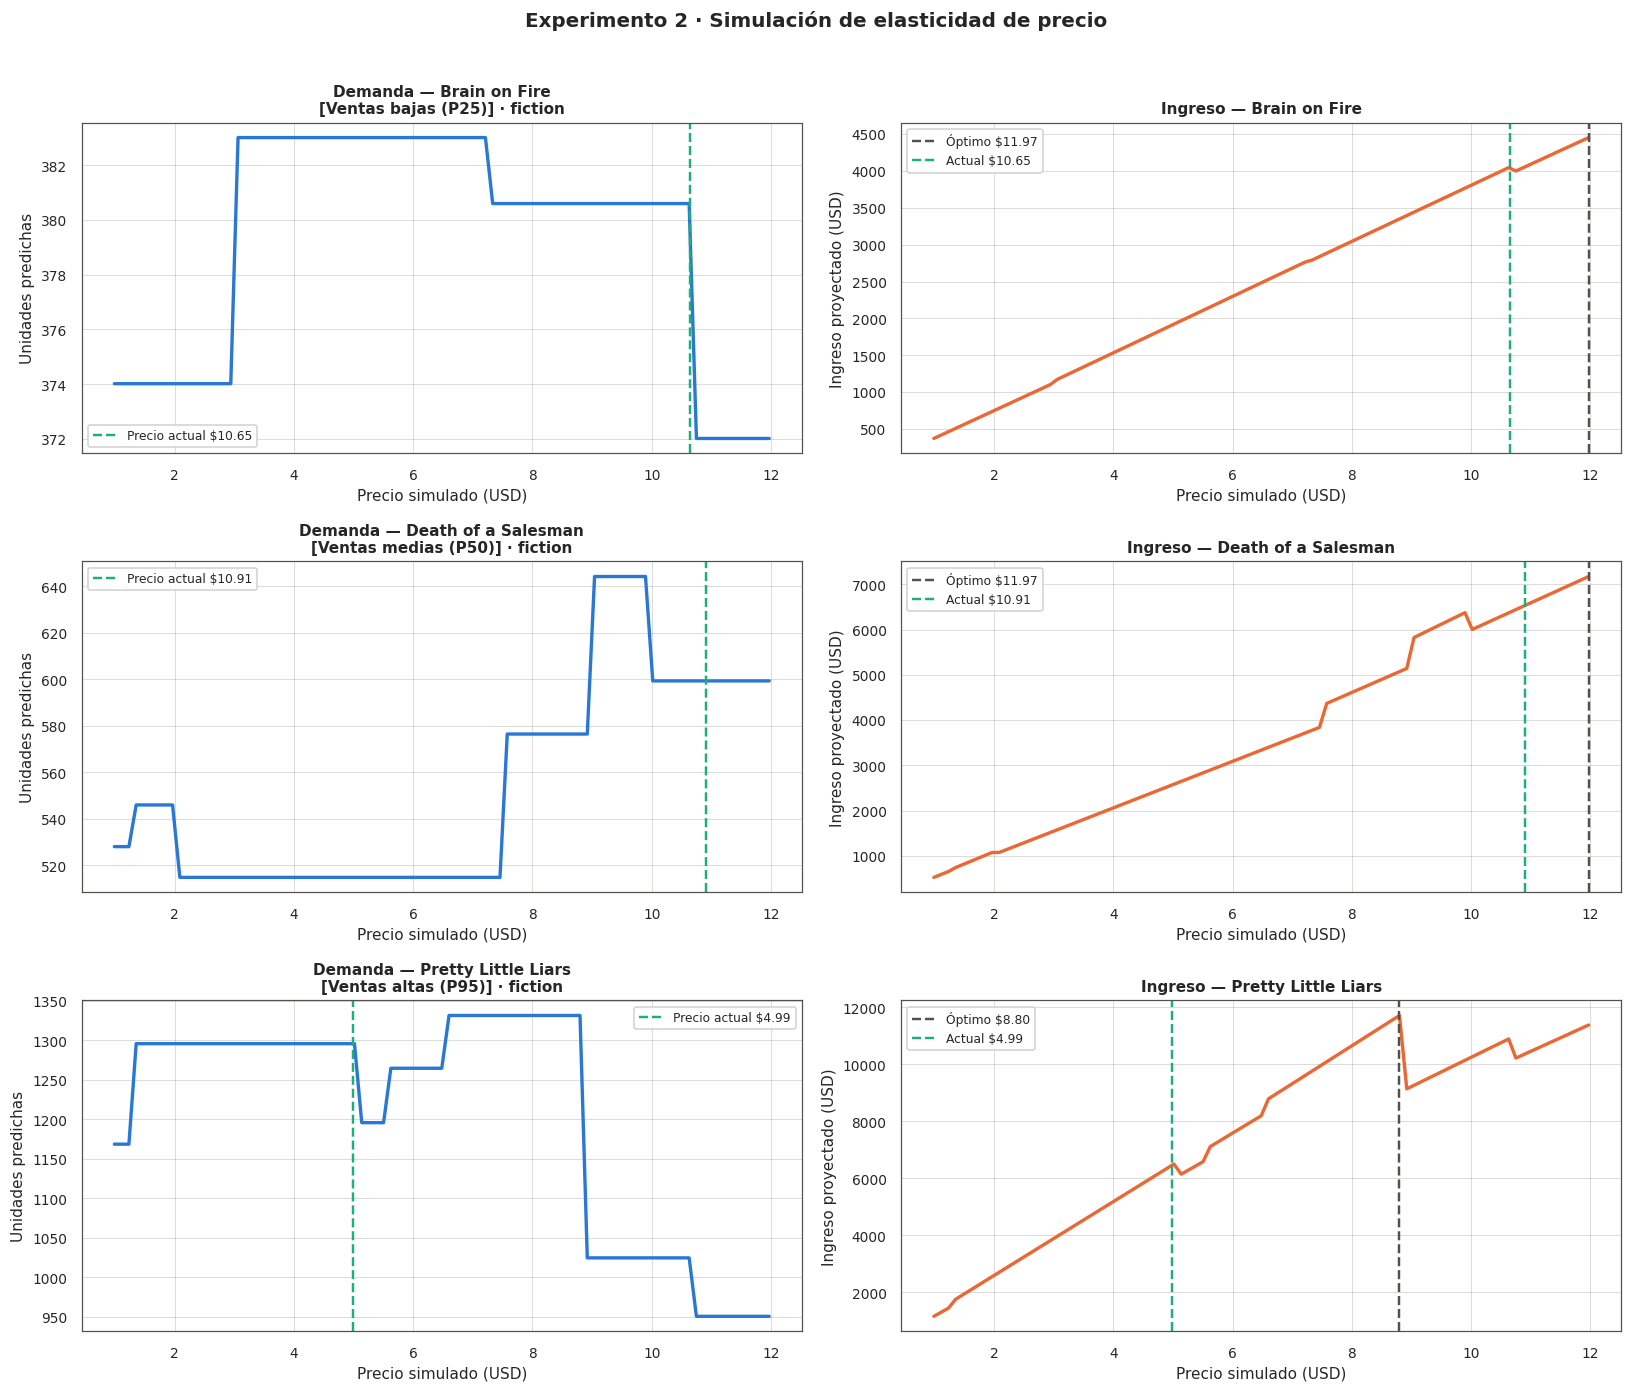

In [34]:
# ============================================================================
#  7.7.3 Curvas de demanda e ingreso
# ============================================================================
simulaciones, resumen_sim = {}, []

fig, axes = plt.subplots(len(seleccion_idx), 2, figsize=(15, 4.3 * len(seleccion_idx)))
axes = np.atleast_2d(axes)

for i, (idx_libro, etiqueta) in enumerate(zip(seleccion_idx, etiquetas)):
    fila = df_test_orig.loc[idx_libro]
    sim  = simular_precio(fila, MODELO_DEMANDA)
    simulaciones[idx_libro] = sim

    titulo = str(fila["book_name"])[:42] if "book_name" in fila else f"Libro {idx_libro}"
    p_opt  = sim.loc[sim["ingreso_proyectado"].idxmax()]
    p_real = float(fila["sale_price"])

    a = axes[i, 0]
    a.plot(sim["precio_simulado"], sim["unidades_predichas"], lw=2.2, color=C_SERIE[0])
    a.axvline(p_real, color=C_SERIE[2], ls="--", lw=1.6, label=f"Precio actual ${p_real:.2f}")
    a.set_xlabel("Precio simulado (USD)"); a.set_ylabel("Unidades predichas")
    a.set_title(f"Demanda — {titulo}\n[{etiqueta}] · {fila['genre']}", fontsize=10)
    a.legend(fontsize=8)

    b = axes[i, 1]
    b.plot(sim["precio_simulado"], sim["ingreso_proyectado"], lw=2.2, color=C_SERIE[1])
    b.axvline(p_opt["precio_simulado"], color=C_REF, ls="--", lw=1.6,
              label=f"Óptimo ${p_opt['precio_simulado']:.2f}")
    b.axvline(p_real, color=C_SERIE[2], ls="--", lw=1.6, label=f"Actual ${p_real:.2f}")
    b.set_xlabel("Precio simulado (USD)"); b.set_ylabel("Ingreso proyectado (USD)")
    b.set_title(f"Ingreso — {titulo}", fontsize=10)
    b.legend(fontsize=8)

    ing_actual = float(np.interp(p_real, sim["precio_simulado"], sim["ingreso_proyectado"]))
    resumen_sim.append({
        "libro"                : titulo,
        "segmento"             : etiqueta,
        "genero"               : fila["genre"],
        "precio_actual"        : p_real,
        "precio_optimo"        : float(p_opt["precio_simulado"]),
        "unidades_en_optimo"   : float(p_opt["unidades_predichas"]),
        "ingreso_en_optimo"    : float(p_opt["ingreso_proyectado"]),
        "ingreso_actual_est"   : ing_actual,
        "delta_ingreso_%"      : (float(p_opt["ingreso_proyectado"]) / ing_actual - 1) * 100
                                  if ing_actual > 0 else np.nan,
        "elasticidad_en_actual": float(np.interp(p_real, sim["precio_simulado"], sim["elasticidad"])),
    })

fig.suptitle("Experimento 2 · Simulación de elasticidad de precio", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.97]); plt.show()

RESULTADOS DE LA SIMULACIÓN DE PRECIOS
Ventana simulada: USD 0.99 a USD 11.99 (percentiles 2-98 del precio observado en train)


,libro,segmento,genero,precio_actual,precio_optimo,unidades_en_optimo,ingreso_en_optimo,ingreso_actual_est,delta_ingreso_%,elasticidad_en_actual
0,Brain on Fire,Ventas bajas (P25),fiction,10.65,11.97,372.02,"4,453.06","4,036.75",10.31,-1.00
1,Death of a Salesman,Ventas medias (P50),fiction,10.91,11.97,599.30,"7,173.62","6,538.37",9.72,-0.00
2,Pretty Little Liars,Ventas altas (P95),fiction,4.99,8.80,"1,331.63","11,715.64","6,466.60",81.17,-1.33



Lectura por título:

  Brain on Fire
     elasticidad en el precio actual (USD 10.65):  -1.003  -> ELÁSTICA   (subir el precio reduciría el ingreso en ese punto)
     precio de ingreso máximo dentro de la ventana   : USD 11.97  [óptimo en el BORDE SUPERIOR de la ventana]

  Death of a Salesman
     elasticidad en el precio actual (USD 10.91):  -0.000  -> INELÁSTICA (subir el precio aumentaría el ingreso en ese punto)
     precio de ingreso máximo dentro de la ventana   : USD 11.97  [óptimo en el BORDE SUPERIOR de la ventana]

  Pretty Little Liars
     elasticidad en el precio actual (USD 4.99):  -1.331  -> ELÁSTICA   (subir el precio reduciría el ingreso en ese punto)
     precio de ingreso máximo dentro de la ventana   : USD 8.80

------------------------------------------------------------------------------------------------
Cómo leer estos dos números juntos.
  La elasticidad es LOCAL: describe la pendiente del ingreso en el precio actual.
  El 'precio óptimo' es GLOBAL dentro de 

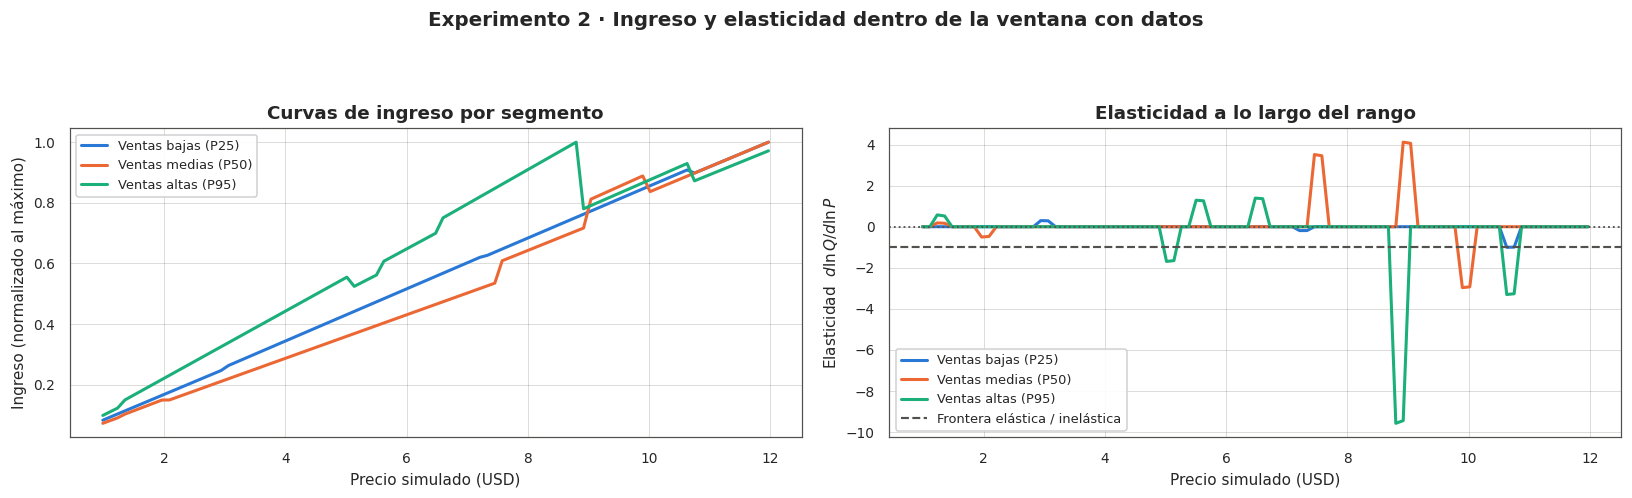

In [35]:
# ============================================================================
#  7.7.4 Resumen de la simulación y lectura económica
# ============================================================================
tabla_sim = pd.DataFrame(resumen_sim)
print("=" * 96)
print("RESULTADOS DE LA SIMULACIÓN DE PRECIOS")
print(f"Ventana simulada: USD {PRECIO_MIN_SIM:.2f} a USD {PRECIO_MAX_SIM:.2f} "
      f"(percentiles 2-98 del precio observado en train)")
print("=" * 96)
display(tabla_sim)

print("\nLectura por título:")
for _, r in tabla_sim.iterrows():
    e, p_act, p_opt = r["elasticidad_en_actual"], r["precio_actual"], r["precio_optimo"]
    if   e < -1: diag = "ELÁSTICA   (subir el precio reduciría el ingreso en ese punto)"
    elif e < 0:  diag = "INELÁSTICA (subir el precio aumentaría el ingreso en ese punto)"
    else:        diag = "no negativa (el modelo no ve demanda decreciente en ese punto)"
    # la grilla avanza de PASO_SIM en PASO_SIM y puede no tocar el extremo exacto:
    # se considera "borde" cualquier óptimo dentro de un paso del límite de la ventana
    borde = ""
    if p_opt >= PRECIO_MAX_SIM - PASO_SIM:   borde = "  [óptimo en el BORDE SUPERIOR de la ventana]"
    elif p_opt <= PRECIO_MIN_SIM + PASO_SIM: borde = "  [óptimo en el BORDE INFERIOR de la ventana]"
    print(f"\n  {r['libro'][:44]}")
    print(f"     elasticidad en el precio actual (USD {p_act:.2f}): {e:>7.3f}  -> {diag}")
    print(f"     precio de ingreso máximo dentro de la ventana   : USD {p_opt:.2f}{borde}")

# Coherencia entre la elasticidad local y el óptimo global: son cosas distintas.
n_borde = int(sum(tabla_sim["precio_optimo"] >= PRECIO_MAX_SIM - PASO_SIM))
print("\n" + "-" * 96)
print("Cómo leer estos dos números juntos.")
print("  La elasticidad es LOCAL: describe la pendiente del ingreso en el precio actual.")
print("  El 'precio óptimo' es GLOBAL dentro de la ventana simulada. Pueden discrepar si la")
print("  curva no es monótona: un título puede ser elástico en su precio actual y aun así")
print("  alcanzar su ingreso máximo en otro tramo del rango.")
if n_borde:
    print(f"\n  ATENCIÓN: {n_borde} de {len(tabla_sim)} títulos tienen su óptimo en el borde de la")
    print("  ventana. Un óptimo de borde NO es un óptimo económico: indica que dentro del rango")
    print("  con datos el ingreso todavía crece, y que el modelo no puede decir qué pasa más")
    print("  allá porque los árboles no extrapolan. La recomendación accionable en ese caso es")
    print("  'testear precios por encima del actual', no 'fijar ese precio'.")

# ¿El modelo aprendió alguna sensibilidad al precio?
elast_max = float(max(abs(simulaciones[k]["elasticidad"]).max() for k in simulaciones))
print("\n" + "-" * 96)
print(f"Sensibilidad al precio aprendida por el modelo: |elasticidad| máxima = {elast_max:.3f}")
if elast_max < 0.5:
    print("  El modelo es prácticamente INSENSIBLE al precio: las unidades predichas apenas")
    print("  cambian al moverlo. En consecuencia el ingreso P x Q crece casi linealmente y el")
    print("  'precio óptimo' refleja esa linealidad, no una decisión de mercado.")
    print("  Causa probable: en el catálogo el precio explica muy poco de las ventas frente al")
    print("  autor, el género y la prueba social (ver la importancia de features en 7.6).")
    print("  Conclusión honesta: estos datos NO sostienen una recomendación de precios.")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for (idx_libro, etiqueta), color in zip(zip(seleccion_idx, etiquetas), C_SERIE):
    sim = simulaciones[idx_libro]
    ing = sim["ingreso_proyectado"]
    ax[0].plot(sim["precio_simulado"], ing / max(ing.max(), 1e-9), lw=2, label=etiqueta, color=color)
    ax[1].plot(sim["precio_simulado"], sim["elasticidad"], lw=2, label=etiqueta, color=color)
ax[0].set_xlabel("Precio simulado (USD)"); ax[0].set_ylabel("Ingreso (normalizado al máximo)")
ax[0].set_title("Curvas de ingreso por segmento"); ax[0].legend(fontsize=8.5)
ax[1].axhline(-1, color=C_REF, ls="--", lw=1.4, label="Frontera elástica / inelástica")
ax[1].axhline(0, color=C_REF, ls=":", lw=1.2)
ax[1].set_xlabel("Precio simulado (USD)"); ax[1].set_ylabel(r"Elasticidad  $d\ln Q / d\ln P$")
ax[1].set_title("Elasticidad a lo largo del rango"); ax[1].legend(fontsize=8.5)
fig.suptitle("Experimento 2 · Ingreso y elasticidad dentro de la ventana con datos",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.91]); plt.show()

---
## 8. Experimento 3 — Clasificación de margen: SVM vs. Random Forest

### 8.1 Redefinición del objetivo

#### El objetivo previsto y por qué no es viable

La especificación original define

$$\texttt{high_margin} = \mathbb{1}\left[\texttt{margin_ratio} > \text{mediana}(\texttt{margin_ratio})\right],
\qquad \texttt{margin_ratio} = \frac{\texttt{publisher_revenue}}{\texttt{gross_sales}}$$

La auditoría de la sección 2.8 mostró que `margin_ratio` **no es una variable continua**: toma
exactamente dos estados, $0.6$ y $0$. No hay márgenes del 45 %, del 52 % ni del 71 %; la editorial
se lleva el 60 % o no se lleva nada.

Eso vuelve inaplicable el corte por la mediana, y de una forma particularmente engañosa. Al redondear
los montos a dos decimales (sección 1.3), los valores nominalmente iguales a $0.6$ quedan dispersos
en un rango de $\pm 4 \times 10^{-5}$ por error de redondeo. La mediana cae **dentro de esa nube de
ruido**, de modo que el corte parte ese grupo casi por la mitad y produce un balance de clases
aparentemente saludable —cercano al 50/50— que en realidad **separa errores de punto flotante**.

Un modelo entrenado contra esa etiqueta no puede superar el azar, porque la etiqueta no codifica
ninguna propiedad del libro. El balance perfecto, que a primera vista parecería una virtud del
diseño, es el síntoma.

#### El objetivo que sí sostiene el dataset

Dada la estructura binaria real, la pregunta de negocio bien planteada es:

$$\texttt{genera_ingreso} = \mathbb{1}\left[\texttt{publisher_revenue} > 0\right]$$

*¿Obtiene la editorial algún ingreso por este título, o el margen se lo lleva íntegramente el canal?*
Es una decisión editorial real —sobre qué contratos o formatos conviene negociar— y es la única
partición que los datos soportan. El problema queda moderadamente desbalanceado (≈ 65 / 35), lo que
mantiene vigente la discusión de métricas de la sección 6.

#### Contraste conceptual

| | SVM (RBF) | Random Forest |
|---|---|---|
| Frontera de decisión | suave, global | escalonada, ejes-paralela |
| Escalado | imprescindible | irrelevante |
| Interacciones | dependen del kernel | las captura de forma nativa |
| Costo de entrenamiento | entre $O(n^2)$ y $O(n^3)$ | $O(B \cdot n \log n)$, paralelizable |
| Interpretabilidad | baja | importancias disponibles |

POR QUÉ SE REDEFINE EL OBJETIVO
  Valores distintos de margin_ratio (3 decimales): [np.float64(0.0), np.float64(0.6)]
  Rango real dentro del grupo '0.6': [0.59996188, 0.60001888]
  Mediana                          : 0.59999815
  Corte por la mediana -> 216 positivos de 432 (balance 0.500)

  Ese 50/50 aparente separa ERROR DE REDONDEO, no rentabilidad: la mediana cae
  dentro de la nube de ruido numérico del grupo nominalmente igual a 0.6.

OBJETIVO ADOPTADO: genera_ingreso = (publisher_revenue > 0)
publisher_revenue
Con ingreso editorial    271
Sin ingreso editorial    161

Proporción de positivos: 0.6273


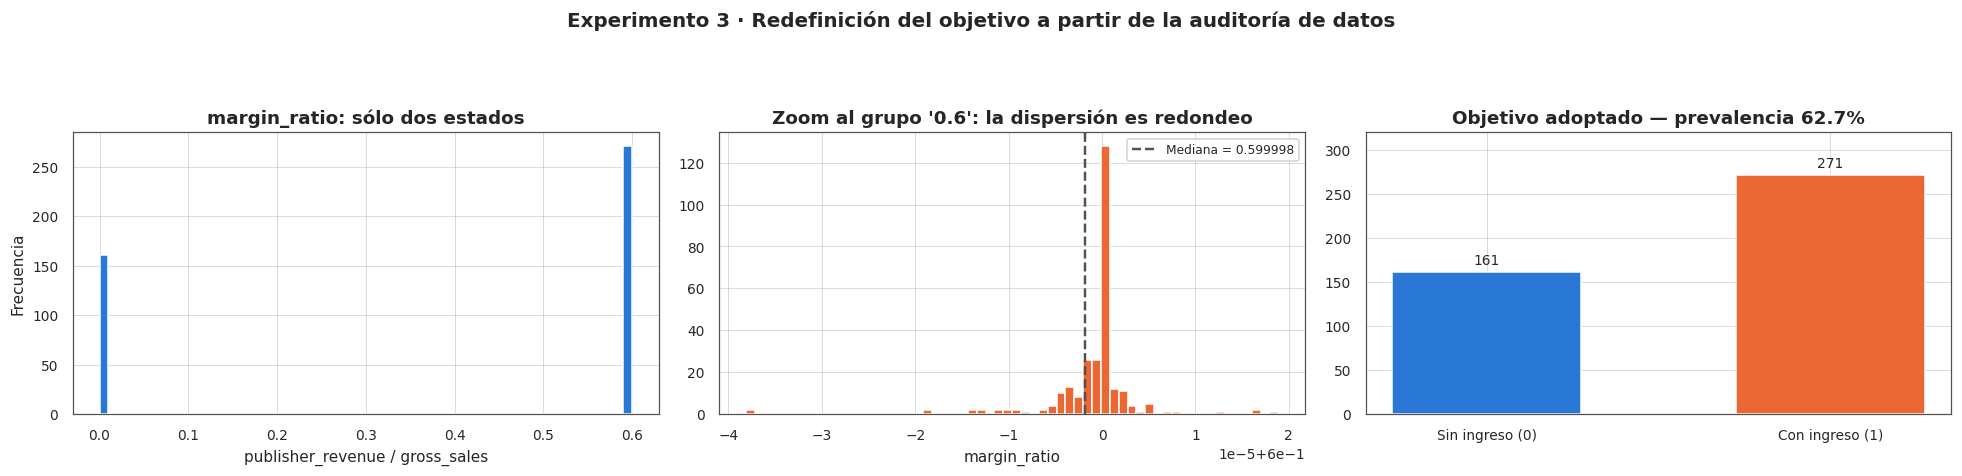

In [36]:
# ============================================================================
#  8.1 Construcción del objetivo: genera_ingreso
# ============================================================================
from sklearn.model_selection import GridSearchCV     # import local: la sección 8 no depende de la 6

# --- Evidencia de por qué NO se usa el corte por la mediana de margin_ratio
margen = df_feat["margin_ratio"].replace([np.inf, -np.inf], np.nan)
print("=" * 78)
print("POR QUÉ SE REDEFINE EL OBJETIVO")
print("=" * 78)
print(f"  Valores distintos de margin_ratio (3 decimales): "
      f"{sorted(margen.round(3).dropna().unique())}")
print(f"  Rango real dentro del grupo '0.6': "
      f"[{margen[margen > 0.3].min():.8f}, {margen[margen > 0.3].max():.8f}]")
print(f"  Mediana                          : {margen.median():.8f}")
y_mediana = (margen > margen.median()).astype(float)
print(f"  Corte por la mediana -> {int(y_mediana.sum())} positivos de {int(y_mediana.notna().sum())} "
      f"(balance {y_mediana.mean():.3f})")
print("\n  Ese 50/50 aparente separa ERROR DE REDONDEO, no rentabilidad: la mediana cae")
print("  dentro de la nube de ruido numérico del grupo nominalmente igual a 0.6.")

# --- Objetivo efectivamente usado
y_clf3 = (df_feat["publisher_revenue"] > 0).astype(int)
print("\n" + "=" * 78)
print("OBJETIVO ADOPTADO: genera_ingreso = (publisher_revenue > 0)")
print("=" * 78)
print(y_clf3.value_counts().rename({0: "Sin ingreso editorial", 1: "Con ingreso editorial"}).to_string())
print(f"\nProporción de positivos: {y_clf3.mean():.4f}")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))

ax[0].hist(margen.dropna(), bins=60, color=C_SERIE[0])
ax[0].set_title("margin_ratio: sólo dos estados")
ax[0].set_xlabel("publisher_revenue / gross_sales"); ax[0].set_ylabel("Frecuencia")

sub = margen[margen > 0.3]
ax[1].hist(sub, bins=60, color=C_SERIE[1])
ax[1].axvline(margen.median(), color=C_REF, ls="--", lw=1.6,
              label=f"Mediana = {margen.median():.6f}")
ax[1].set_title("Zoom al grupo '0.6': la dispersión es redondeo")
ax[1].set_xlabel("margin_ratio"); ax[1].legend(fontsize=8)

conteo = y_clf3.value_counts().sort_index()
ax[2].bar(["Sin ingreso (0)", "Con ingreso (1)"], conteo.values, color=C_SERIE[:2], width=.55)
ax[2].bar_label(ax[2].containers[0], fmt="%d", padding=3, fontsize=9)
ax[2].set_title(f"Objetivo adoptado — prevalencia {y_clf3.mean():.1%}")
ax[2].margins(y=.18)

fig.suptitle("Experimento 3 · Redefinición del objetivo a partir de la auditoría de datos",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.9]); plt.show()

In [37]:
# ============================================================================
#  8.2 Preparación de datos
# ============================================================================
# El escalado NO se aplica acá: va dentro del Pipeline del SVM, para que el
# StandardScaler se reajuste en cada fold de la validación cruzada.
X3_tr, X3_te, y3_tr, y3_te, info3 = preparar_datos(
    df_feat, y_clf3,
    estratificar=True,
    escalar=None
)
y3_tr, y3_te = y3_tr.astype(int), y3_te.astype(int)

print(f"\nBalance -> train: {y3_tr.mean():.4f} | test: {y3_te.mean():.4f}")

Features       : ['author', 'author_rating', 'genre', 'publisher', 'sale_price', 'book_age', 'price_relative_to_genre', 'book_average_rating', 'book_ratings_count', 'social_proof_score']
One-Hot        : ['author_rating', 'genre', 'publisher']
Target Encoding: ['author']
Escalado       : None
X_train (302, 21) | X_test (130, 21) | features finales: 21

Balance -> train: 0.6258 | test: 0.6308


In [38]:
# ============================================================================
#  8.3 SVM: pipelines con kernel RBF y lineal
# ============================================================================
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

pipe_svc_rbf = Pipeline([
    ("scaler", StandardScaler()),                      # imprescindible antes del kernel
    ("svc", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
])
grid_rbf = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1, 1]}

pipe_svc_lin = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="linear", probability=True, random_state=RANDOM_STATE)),
])
grid_lin = {"svc__C": [0.01, 0.1, 1, 10]}

cv3 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

gs_rbf = GridSearchCV(pipe_svc_rbf, grid_rbf, scoring="f1", cv=cv3, n_jobs=-1, verbose=1)
gs_rbf.fit(X3_tr, y3_tr)
print(f"\n[SVC rbf]    mejores params: {gs_rbf.best_params_}  | F1 CV = {gs_rbf.best_score_:.4f}")

gs_lin = GridSearchCV(pipe_svc_lin, grid_lin, scoring="f1", cv=cv3, n_jobs=-1, verbose=1)
gs_lin.fit(X3_tr, y3_tr)
print(f"[SVC linear] mejores params: {gs_lin.best_params_}  | F1 CV = {gs_lin.best_score_:.4f}")

svc_rbf, svc_lin = gs_rbf.best_estimator_, gs_lin.best_estimator_
print(f"\nVectores de soporte (rbf): {svc_rbf.named_steps['svc'].n_support_} "
      f"sobre {len(X3_tr)} observaciones de entrenamiento")

Fitting 5 folds for each of 16 candidates, totalling 80 fits

[SVC rbf]    mejores params: {'svc__C': 1, 'svc__gamma': 0.01}  | F1 CV = 0.8732
Fitting 5 folds for each of 4 candidates, totalling 20 fits
[SVC linear] mejores params: {'svc__C': 0.1}  | F1 CV = 0.8721

Vectores de soporte (rbf): [68 76] sobre 302 observaciones de entrenamiento


In [39]:
# ============================================================================
#  8.4 Random Forest
# ============================================================================
rf_base = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                                 class_weight="balanced_subsample")
grid_rf = {
    "n_estimators"     : [300, 600],
    "max_depth"        : [None, 8, 15],
    "min_samples_leaf" : [1, 3, 8],
    "max_features"     : ["sqrt", "log2"],
}
gs_rf = GridSearchCV(rf_base, grid_rf, scoring="f1", cv=cv3, n_jobs=-1, verbose=1)
gs_rf.fit(X3_tr, y3_tr)

print(f"\n[RandomForest] mejores params: {gs_rf.best_params_}")
print(f"[RandomForest] F1 CV = {gs_rf.best_score_:.4f}")
rf_clf = gs_rf.best_estimator_

Fitting 5 folds for each of 36 candidates, totalling 180 fits

[RandomForest] mejores params: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}
[RandomForest] F1 CV = 0.8667


In [40]:
# ============================================================================
#  8.5 Comparativa de métricas en test
# ============================================================================
modelos_exp3 = {"SVM (RBF)": svc_rbf, "SVM (Lineal)": svc_lin, "Random Forest": rf_clf}

filas3, probas3 = [], {}
for nombre, modelo in modelos_exp3.items():
    yp = modelo.predict(X3_te)
    pp = modelo.predict_proba(X3_te)[:, 1]
    probas3[nombre] = pp
    filas3.append({
        "Modelo"   : nombre,
        "Accuracy" : accuracy_score(y3_te, yp),
        "Precision": precision_score(y3_te, yp, zero_division=0),
        "Recall"   : recall_score(y3_te, yp, zero_division=0),
        "F1-Score" : f1_score(y3_te, yp, zero_division=0),
        "ROC-AUC"  : roc_auc_score(y3_te, pp),
        "PR-AUC"   : average_precision_score(y3_te, pp),
    })

tabla_exp3 = pd.DataFrame(filas3).set_index("Modelo")
print("=" * 78)
print("EXPERIMENTO 3 — MÉTRICAS EN TEST")
print("=" * 78)
display(tabla_exp3)

GANADOR_EXP3 = tabla_exp3["F1-Score"].idxmax()
print(f"\nMejor modelo por F1-Score: {GANADOR_EXP3}")

for nombre, modelo in modelos_exp3.items():
    print(f"\n--- {nombre} ---")
    print(classification_report(y3_te, modelo.predict(X3_te),
                                target_names=["Sin ingreso", "Con ingreso"], digits=4))

EXPERIMENTO 3 — MÉTRICAS EN TEST


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Modelo,,,,,,
SVM (RBF),0.84,0.97,0.77,0.86,0.84,0.93
SVM (Lineal),0.84,0.97,0.77,0.86,0.89,0.94
Random Forest,0.82,0.94,0.77,0.85,0.88,0.94



Mejor modelo por F1-Score: SVM (RBF)

--- SVM (RBF) ---
              precision    recall  f1-score   support

 Sin ingreso     0.7077    0.9583    0.8142        48
 Con ingreso     0.9692    0.7683    0.8571        82

    accuracy                         0.8385       130
   macro avg     0.8385    0.8633    0.8357       130
weighted avg     0.8727    0.8385    0.8413       130


--- SVM (Lineal) ---
              precision    recall  f1-score   support

 Sin ingreso     0.7077    0.9583    0.8142        48
 Con ingreso     0.9692    0.7683    0.8571        82

    accuracy                         0.8385       130
   macro avg     0.8385    0.8633    0.8357       130
weighted avg     0.8727    0.8385    0.8413       130


--- Random Forest ---
              precision    recall  f1-score   support

 Sin ingreso     0.6984    0.9167    0.7928        48
 Con ingreso     0.9403    0.7683    0.8456        82

    accuracy                         0.8231       130
   macro avg     0.8194   

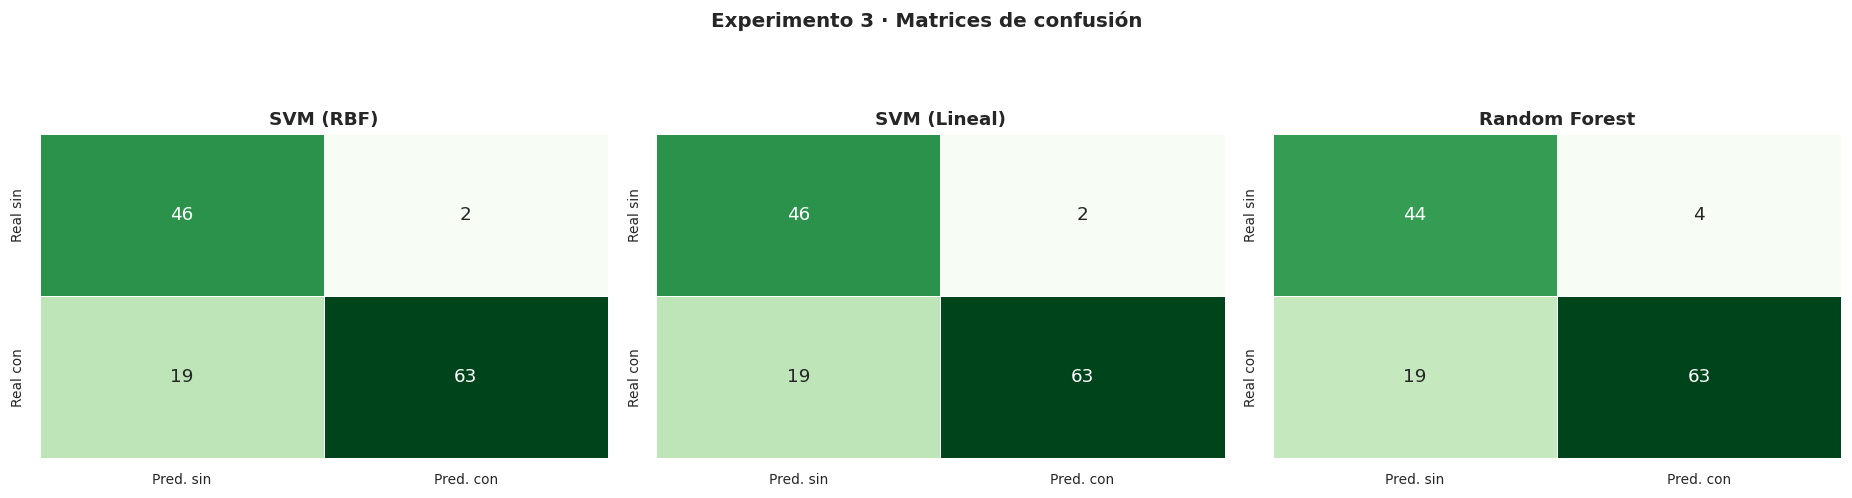

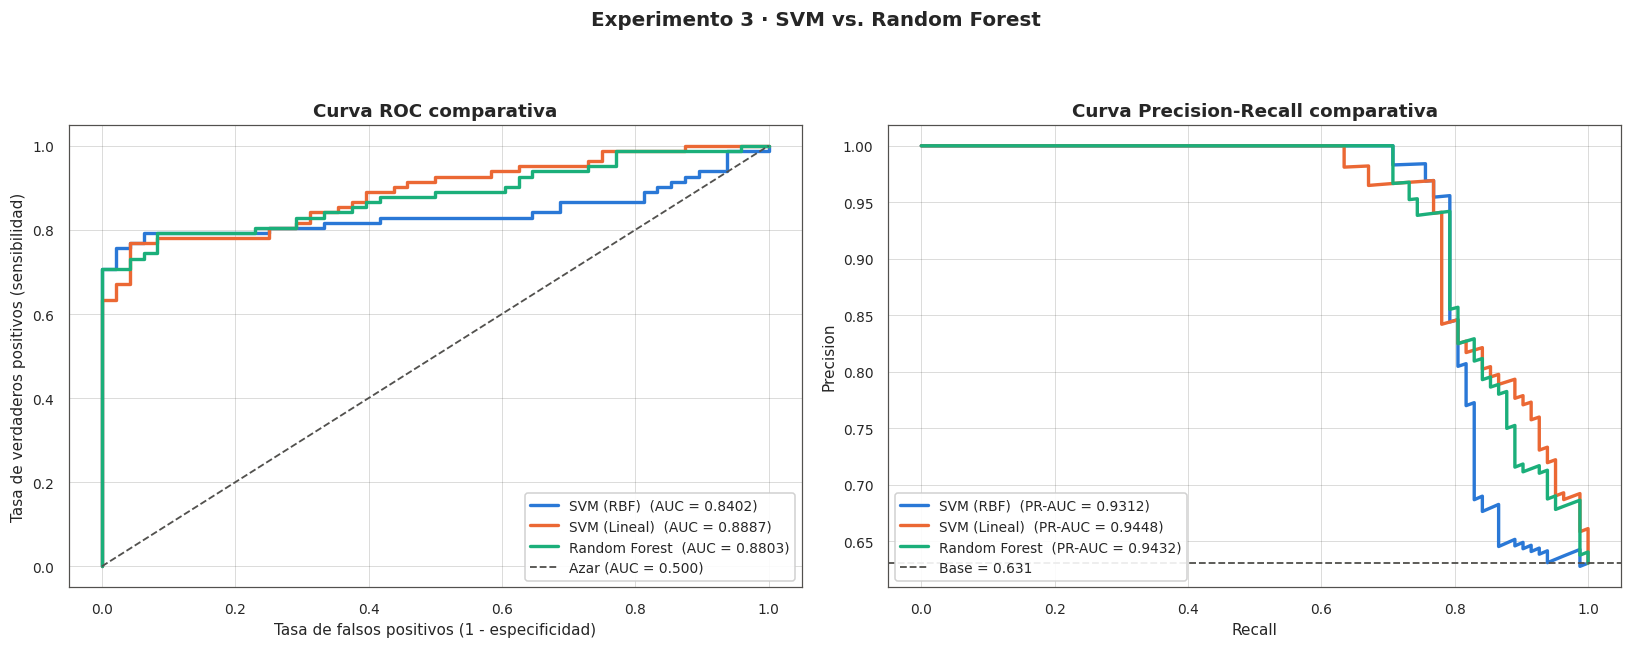

In [41]:
# ============================================================================
#  8.6 Matrices de confusión y curvas comparativas
# ============================================================================
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a, (nombre, modelo) in zip(ax, modelos_exp3.items()):
    cm = confusion_matrix(y3_te, modelo.predict(X3_te))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=a, linewidths=.5,
                xticklabels=["Pred. sin", "Pred. con"],
                yticklabels=["Real sin", "Real con"])
    a.set_title(nombre)
fig.suptitle("Experimento 3 · Matrices de confusión", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.9]); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for (nombre, color) in zip(modelos_exp3, C_SERIE):
    fpr_i, tpr_i, _ = roc_curve(y3_te, probas3[nombre])
    ax[0].plot(fpr_i, tpr_i, lw=2.2, color=color,
               label=f"{nombre}  (AUC = {roc_auc_score(y3_te, probas3[nombre]):.4f})")
    pr_i, rc_i, _ = precision_recall_curve(y3_te, probas3[nombre])
    ax[1].plot(rc_i, pr_i, lw=2.2, color=color,
               label=f"{nombre}  (PR-AUC = {average_precision_score(y3_te, probas3[nombre]):.4f})")

ax[0].plot([0, 1], [0, 1], ls="--", lw=1.2, color=C_REF, label="Azar (AUC = 0.500)")
ax[0].set_xlabel("Tasa de falsos positivos (1 - especificidad)")
ax[0].set_ylabel("Tasa de verdaderos positivos (sensibilidad)")
ax[0].set_title("Curva ROC comparativa"); ax[0].legend(loc="lower right")

ax[1].axhline(y3_te.mean(), ls="--", lw=1.2, color=C_REF, label=f"Base = {y3_te.mean():.3f}")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Curva Precision-Recall comparativa"); ax[1].legend(loc="lower left")

fig.suptitle("Experimento 3 · SVM vs. Random Forest", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

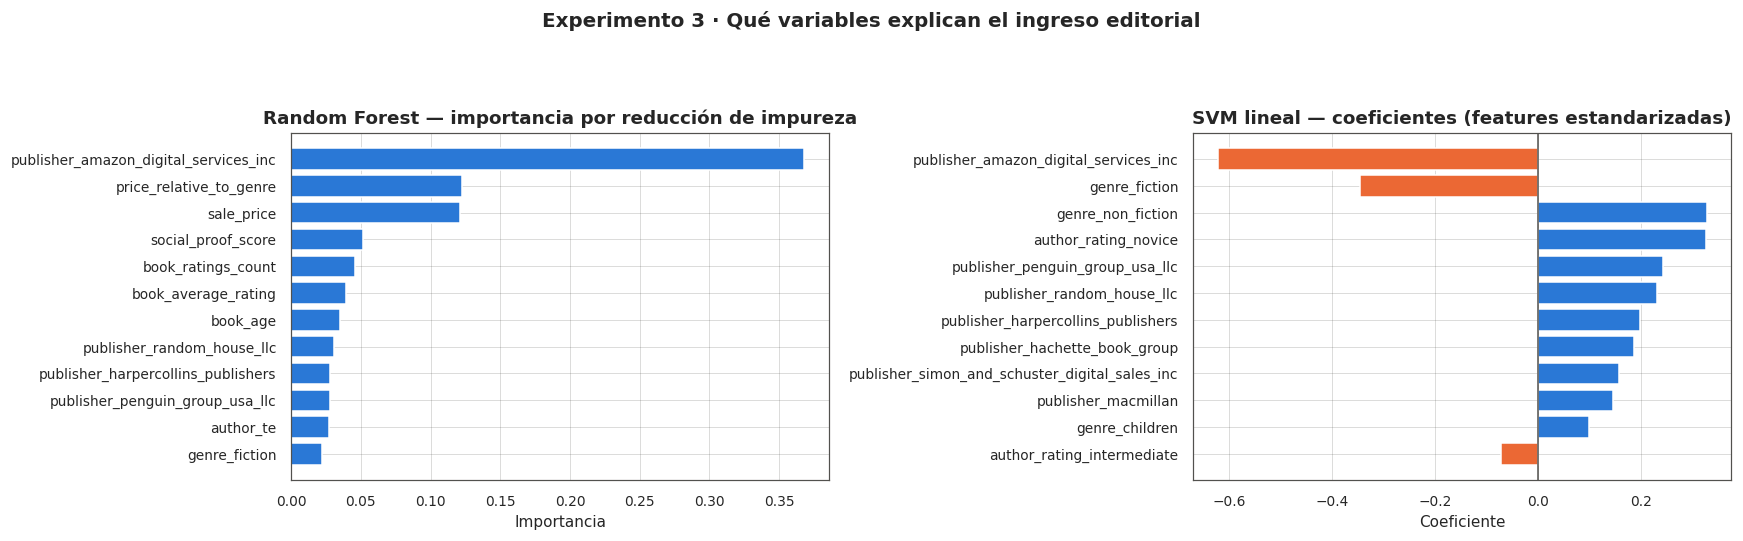

Permutation importance de SVM (RBF) (caída de F1 al permutar cada feature):


,feature,caida_media_F1,desvio
0,publisher_amazon_digital_services_inc,0.07,0.02
1,genre_non_fiction,0.02,0.01
2,genre_fiction,0.02,0.01
3,author_rating_novice,0.01,0.00
4,publisher_random_house_llc,0.01,0.01
5,publisher_hachette_book_group,0.01,0.01
6,publisher_simon_and_schuster_digital_sales_inc,0.01,0.01
7,social_proof_score,0.00,0.00
8,book_ratings_count,0.00,0.00
9,publisher_penguin_group_usa_llc,0.00,0.01


In [42]:
# ============================================================================
#  8.7 Interpretabilidad: importancias del RF y coeficientes del SVM lineal
# ============================================================================
from sklearn.inspection import permutation_importance

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

imp_rf = (pd.Series(rf_clf.feature_importances_, index=X3_tr.columns)
            .sort_values(ascending=False).head(12)[::-1])
ax[0].barh(imp_rf.index, imp_rf.values, color=C_SERIE[0])
ax[0].set_title("Random Forest — importancia por reducción de impureza")
ax[0].set_xlabel("Importancia")

coef = pd.Series(svc_lin.named_steps["svc"].coef_.ravel(), index=X3_tr.columns)
coef_top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12)[::-1]
ax[1].barh(coef_top.index, coef_top.values,
           color=[C_SERIE[1] if v < 0 else C_SERIE[0] for v in coef_top.values])
ax[1].axvline(0, color=C_REF, lw=1)
ax[1].set_title("SVM lineal — coeficientes (features estandarizadas)")
ax[1].set_xlabel("Coeficiente")

fig.suptitle("Experimento 3 · Qué variables explican el ingreso editorial", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.91]); plt.show()

print(f"Permutation importance de {GANADOR_EXP3} (caída de F1 al permutar cada feature):")
pi = permutation_importance(modelos_exp3[GANADOR_EXP3], X3_te, y3_te,
                            n_repeats=10, random_state=RANDOM_STATE, scoring="f1", n_jobs=-1)
display(pd.DataFrame({"feature": X3_te.columns,
                      "caida_media_F1": pi.importances_mean,
                      "desvio": pi.importances_std})
          .sort_values("caida_media_F1", ascending=False).head(12).reset_index(drop=True))

### Anexo: Prueba de humo del Experimento 3 con datos sintéticos

#### Pregunta de negocio asociada:
> **¿Qué libros dejarán margen de ganancia o ingresos reales para la editorial (`publisher_revenue > 0`)?**

Para validar de manera controlada el comportamiento del mejor modelo obtenido en el Experimento 3 (el pipeline con **SVM (RBF)**, guardado en `svc_rbf`), generaremos un pequeño lote de 5 observaciones sintéticas.

Cada una de estas observaciones simula diferentes perfiles de libros en base a sus características más relevantes para este problema (como el sello de la editorial, el precio de venta y el posicionamiento relativo):

In [43]:
# ============================================================================
#  Prueba de humo de SVM RBF (Experimento 3) con datos sintéticos
# ============================================================================
import pandas as pd
import numpy as np

# Creamos un conjunto de datos sintéticos simulando perfiles de prueba coherentes
# con las columnas que el modelo final espera después de la ingeniería de features.
X_sintetico = pd.DataFrame({
    'sale_price'                      : [1.99, 12.99, 0.99, 8.50, 4.99],
    'book_age'                        : [10.0, 50.0,  5.0,  20.0, 15.0],
    'price_relative_to_genre'         : [0.45, 2.50,  0.22, 1.80, 1.07],
    'book_average_rating'             : [4.10, 4.50,  3.20, 3.80, 4.20],
    'book_ratings_count'              : [150000.0, 5000.0, 80000.0, 20000.0, 120000.0],
    'social_proof_score'              : [48.80, 38.30, 36.10, 37.60, 49.10],
    'author_te'                       : [0.63, 0.63, 0.63, 0.63, 0.63],
    'author_rating_excellent'         : [1.0, 0.0, 0.0, 0.0, 1.0],
    'author_rating_famous'            : [0.0, 1.0, 0.0, 0.0, 0.0],
    'author_rating_intermediate'      : [0.0, 0.0, 1.0, 1.0, 0.0],
    'author_rating_novice'            : [0.0, 0.0, 0.0, 0.0, 0.0],
    'genre_children'                  : [0.0, 0.0, 0.0, 0.0, 0.0],
    'genre_fiction'                   : [1.0, 0.0, 1.0, 1.0, 1.0],
    'genre_non_fiction'               : [0.0, 1.0, 0.0, 0.0, 0.0],
    'publisher_amazon_digital_services_inc': [0.0, 0.0, 1.0, 0.0, 0.0],
    'publisher_hachette_book_group'   : [0.0, 0.0, 0.0, 1.0, 0.0],
    'publisher_harpercollins_publishers': [0.0, 1.0, 0.0, 0.0, 0.0],
    'publisher_macmillan'             : [0.0, 0.0, 0.0, 0.0, 0.0],
    'publisher_penguin_group_usa_llc' : [1.0, 0.0, 0.0, 0.0, 1.0],
    'publisher_random_house_llc'      : [0.0, 0.0, 0.0, 0.0, 0.0],
    'publisher_simon_and_schuster_digital_sales_inc': [0.0, 0.0, 0.0, 0.0, 0.0]
})

# Descripciones de los perfiles para la presentación final de negocio
descripciones = [
    "Bestseller Tradicional (Penguin, rating alto, precio accesible)",
    "No ficción Especializada (Caro, HarperCollins, rating alto, pocas reviews)",
    "Libro Autopublicado Barato (Amazon, baja calificación general)",
    "Ficción de consumo masivo (Hachette, precio medio/alto)",
    "Ficción consolidada (Penguin, precio equilibrado, excelente reputación del autor)"
]

# Obtenemos las predicciones y sus probabilidades asociadas mediante el ganador SVM RBF
modelo_ganador = modelos_exp3["SVM (RBF)"]
predicciones = modelo_ganador.predict(X_sintetico)
probabilidades = modelo_ganador.predict_proba(X_sintetico)[:, 1]

# Consolidador final de los resultados
resultados = pd.DataFrame({
    "Perfil del libro": descripciones,
    "Probabilidad de Ingreso (%)": (probabilidades * 100).round(2),
    "Genera Ingreso Editorial": ["SÍ" if p == 1 else "NO" for p in predicciones]
})

print("=" * 95)
print("EVALUACIÓN DE DATA SINTÉTICA CONTRA EL PIPELINE SVM (RBF)")
print("Asociado a la pregunta de negocio: ¿Generará este título un retorno real para la editorial?")
print("=" * 95)
display(resultados)

EVALUACIÓN DE DATA SINTÉTICA CONTRA EL PIPELINE SVM (RBF)
Asociado a la pregunta de negocio: ¿Generará este título un retorno real para la editorial?


,Perfil del libro,Probabilidad de Ingreso (%),Genera Ingreso Editorial
0,"Bestseller Tradicional (Penguin, rating alto, precio accesible)",94.58,SÍ
1,"No ficción Especializada (Caro, HarperCollins, rating alto, pocas reviews)",99.38,SÍ
2,"Libro Autopublicado Barato (Amazon, baja calificación general)",41.38,NO
3,"Ficción de consumo masivo (Hachette, precio medio/alto)",96.52,SÍ
4,"Ficción consolidada (Penguin, precio equilibrado, excelente reputación del autor)",94.69,SÍ
